In [3]:
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from difflib import get_close_matches

df=pd.read_csv("nyc311_raw_data.csv")
df

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date
0,71197447,2026-11-21T02:21:27.000,DOT,Department of Transportation,Street Condition,Pothole,WESTCHESTER AVENUE,Open,The Department of Transportation referred this...,2026-11-21T02:21:27.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,71196982,2026-11-21T02:06:07.000,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,10 PALADINO AVENUE,In Progress,NaN,NaN,...,NaN,Residential Building/House,10035.0,NEW YORK,8.0,40.800524,-73.931565,NaN,NaN,NaN
2,71204627,2026-11-21T02:05:17.000,NYPD,New York City Police Department,Noise - Residential,Loud Music/Party,48-16 46 STREET,In Progress,NaN,NaN,...,NaN,Residential Building/House,11377.0,WOODSIDE,26.0,40.739018,-73.919536,NaN,NaN,NaN
3,71197670,2026-11-21T02:05:14.000,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,1704 SEDDON STREET,In Progress,NaN,NaN,...,NaN,Residential Building/House,10461.0,BRONX,18.0,40.841247,-73.849787,NaN,NaN,NaN
4,71200970,2026-11-21T02:05:04.000,NYPD,New York City Police Department,Noise - Commercial,Loud Music/Party,88 2 AVENUE,In Progress,NaN,NaN,...,NaN,Store/Commercial,10003.0,NEW YORK,2.0,40.726870,-73.988909,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,71091684,2026-11-12T16:59:22.000,NYPD,New York City Police Department,Abandoned Vehicle,With License Plate,419 SCHROEDERS AVENUE,Closed,The New York City Police Department responded ...,2026-11-12T17:00:02.000,...,NaN,Street/Sidewalk,11239.0,BROOKLYN,42.0,40.653381,-73.876511,NaN,2026-11-12T16:59:58.000,NaN
99996,71100788,2026-11-12T16:59:05.000,NYPD,New York City Police Department,Illegal Parking,Posted Parking Sign Violation,359 WEST 23 STREET,Closed,The New York City Police Department responded ...,2026-11-12T21:26:47.000,...,NaN,Street/Sidewalk,10011.0,NEW YORK,3.0,40.745977,-74.000083,NaN,2026-11-12T21:26:45.000,NaN
99997,71096187,2026-11-12T16:59:00.000,DOT,Department of Transportation,Traffic Signal Condition,Controller,NaN,Closed,Service Request status for this request is ava...,2026-11-12T16:59:00.000,...,NaN,NaN,11216.0,BROOKLYN,35.0,40.670125,-73.955271,Operating Improperly,2026-11-12T16:59:00.000,NaN
99998,71096372,2026-11-12T16:58:58.000,DEP,Department of Environmental Protection,Sewer Maintenance,Flooding on Street,146-34 32 AVENUE,Closed,The Department of Environment Protection inspe...,2026-11-17T00:23:10.000,...,NaN,Street,11354.0,FLUSHING,19.0,40.769812,-73.820683,NaN,2026-11-13T09:05:00.000,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   unique_key                      100000 non-null  int64  
 1   created_date                    100000 non-null  str    
 2   agency                          100000 non-null  str    
 3   agency_name                     100000 non-null  str    
 4   complaint_type                  100000 non-null  str    
 5   descriptor                      98263 non-null   str    
 6   incident_address                97552 non-null   str    
 7   status                          100000 non-null  str    
 8   resolution_description          90949 non-null   str    
 9   resolution_action_updated_date  91641 non-null   str    
 10  community_board                 100000 non-null  str    
 11  police_precinct                 100000 non-null  str    
 12  borough                     

In [6]:
df.duplicated().sum()

np.int64(2)

In [7]:
df[df.duplicated()]

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date
45000,71157777,2026-11-17T08:13:36.000,HPD,Department of Housing Preservation and Develop...,PAINT/PLASTER,CEILING,1201 SHAKESPEARE AVENUE,Closed,The Department of Housing Preservation and Dev...,2026-11-18T20:31:58.000,...,NaN,RESIDENTIAL BUILDING,10452.0,BRONX,16.0,40.836944,-73.923324,CHIPPED/PEELING/FLAKING,2026-11-18T20:31:58.000,NaN
45001,71156456,2026-11-17T08:13:36.000,HPD,Department of Housing Preservation and Develop...,APPLIANCE,ELECTRIC/GAS RANGE,1201 SHAKESPEARE AVENUE,Closed,HPD conducted an inspection of this complaint....,2026-11-18T20:31:58.000,...,NaN,RESIDENTIAL BUILDING,10452.0,BRONX,16.0,40.836944,-73.923324,OVEN DOOR MISSING OR BROKEN,2026-11-18T20:31:58.000,NaN


In [8]:
df.drop_duplicates(subset=['unique_key'],inplace=True
                   )

C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\3052502770.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=['unique_key'],inplace=True


In [9]:
df.columns

Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'incident_address', 'status', 'resolution_description',
       'resolution_action_updated_date', 'community_board', 'police_precinct',
       'borough', 'open_data_channel_type', 'park_facility_name',
       'facility_type', 'location_type', 'incident_zip', 'city',
       'council_district', 'latitude', 'longitude', 'descriptor_2',
       'closed_date', 'due_date'],
      dtype='str')

In [10]:
df.dtypes

unique_key                          int64
created_date                          str
agency                                str
agency_name                           str
complaint_type                        str
descriptor                            str
incident_address                      str
status                                str
resolution_description                str
resolution_action_updated_date        str
community_board                       str
police_precinct                       str
borough                               str
open_data_channel_type                str
park_facility_name                    str
facility_type                         str
location_type                         str
incident_zip                      float64
city                                  str
council_district                  float64
latitude                          float64
longitude                         float64
descriptor_2                          str
closed_date                       

In [11]:
df.drop_duplicates(subset=['unique_key'],inplace=True)
df.duplicated(subset=['unique_key']).sum()

C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\2214024128.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(subset=['unique_key'],inplace=True)


np.int64(0)

In [12]:
# Keep unique_key in the cleaned output for record traceability.

Create Date and Closed date Change DataType

In [13]:
print(df['created_date'].head(10).to_list())

['2026-11-21T02:21:27.000', '2026-11-21T02:06:07.000', '2026-11-21T02:05:17.000', '2026-11-21T02:05:14.000', '2026-11-21T02:05:04.000', '2026-11-21T02:04:49.000', '2026-11-21T02:02:53.000', '2026-11-21T02:02:44.000', '2026-11-21T02:02:26.000', '2026-11-21T02:02:24.000']


In [14]:
df['created_date'] = pd.to_datetime(
    df['created_date'],
    errors='coerce'
)

In [15]:
print(df['created_date'].head(10).to_list())

[Timestamp('2026-11-21 02:21:27'), Timestamp('2026-11-21 02:06:07'), Timestamp('2026-11-21 02:05:17'), Timestamp('2026-11-21 02:05:14'), Timestamp('2026-11-21 02:05:04'), Timestamp('2026-11-21 02:04:49'), Timestamp('2026-11-21 02:02:53'), Timestamp('2026-11-21 02:02:44'), Timestamp('2026-11-21 02:02:26'), Timestamp('2026-11-21 02:02:24')]


In [16]:
df['closed_date'] = pd.to_datetime(
    df['closed_date'],
    errors='coerce'
)

In [17]:
df.dtypes

unique_key                                 int64
created_date                      datetime64[us]
agency                                       str
agency_name                                  str
complaint_type                               str
descriptor                                   str
incident_address                             str
status                                       str
resolution_description                       str
resolution_action_updated_date               str
community_board                              str
police_precinct                              str
borough                                      str
open_data_channel_type                       str
park_facility_name                           str
facility_type                                str
location_type                                str
incident_zip                             float64
city                                         str
council_district                         float64
latitude            

In [18]:
df['created_date'].min(),df['created_date'].max()

(Timestamp('2026-11-12 16:58:34'), Timestamp('2026-11-21 02:21:27'))

In [19]:
invalid_dates = df[
    df["closed_date"] < df["created_date"]
]
invalid_dates

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date
7922,71197580,2026-11-20 11:10:02,DEP,Department of Environmental Protection,Water Maintenance,Water Main Break,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-21T00:10:54.000,...,NaN,Street,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-20 11:10:00,NaN
14496,71185773,2026-11-19 18:41:01,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running,1974 CONEY ISLAND AVENUE,Closed,The Department of Environmental Protection det...,2026-11-20T00:10:27.000,...,NaN,Sidewalk,11223.0,BROOKLYN,44.0,40.608968,-73.962195,NaN,2026-11-19 18:41:00,NaN
15107,71189294,2026-11-19 17:48:24,DEP,Department of Environmental Protection,Water Maintenance,Leak,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-20T00:11:48.000,...,NaN,NaN,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-19 17:48:00,NaN
17159,71191705,2026-11-19 14:40:00,DOT,Department of Transportation,Street Light Condition,Street Light Out,HENRY HUDSON PARK,Pending,Service Request status for this request is ava...,2026-11-13T14:39:00.000,...,NaN,NaN,10463.0,BRONX,11.0,40.880700,-73.919303,Location Type: Park,2026-11-13 14:39:00,NaN
17166,71189951,2026-11-19 14:39:00,DOT,Department of Transportation,Street Light Condition,Street Light Out,HENRY HUDSON PARK,Pending,Service Request status for this request is ava...,2026-11-13T14:39:00.000,...,NaN,NaN,10463.0,BRONX,11.0,40.880700,-73.919303,Location Type: Park,2026-11-13 14:39:00,NaN
17170,71180970,2026-11-19 14:38:00,DOT,Department of Transportation,Street Light Condition,Street Light Out,HENRY HUDSON PARK,Pending,Service Request status for this request is ava...,2026-11-13T14:38:00.000,...,NaN,NaN,10463.0,BRONX,11.0,40.880700,-73.919303,Location Type: Park,2026-11-13 14:38:00,NaN
19588,71180972,2026-11-19 11:00:00,DOT,Department of Transportation,Street Light Condition,Street Light Out,NaN,Pending,Service Request status for this request is ava...,2026-11-18T10:59:00.000,...,NaN,NaN,10301.0,STATEN ISLAND,49.0,40.637772,-74.076014,Location Type: Intersection,2026-11-18 10:59:00,NaN
21294,71187569,2026-11-19 08:39:04,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Leaking,365 7 AVENUE,Closed,The Department of Environmental Protection det...,2026-11-20T00:10:40.000,...,NaN,Sidewalk,10001.0,NEW YORK,3.0,40.748658,-73.992313,NaN,2026-11-19 08:39:00,NaN
21719,71191052,2026-11-19 08:05:10,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running,200 EAST 65 STREET,Closed,The Department of Environmental Protection det...,2026-11-20T00:09:39.000,...,NaN,Sidewalk,10065.0,NEW YORK,5.0,40.765162,-73.963514,NaN,2026-11-19 08:05:00,NaN
24425,71169920,2026-11-18 21:52:09,DEP,Department of Environmental Protection,Water Maintenance,Water Main Break,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-19T00:15:10.000,...,NaN,Street,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-18 21:52:00,NaN


In [20]:
isnull_closedDate=df[df['closed_date'].isna()]
isnull_closedDate

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date
0,71197447,2026-11-21 02:21:27,DOT,Department of Transportation,Street Condition,Pothole,WESTCHESTER AVENUE,Open,The Department of Transportation referred this...,2026-11-21T02:21:27.000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1,71196982,2026-11-21 02:06:07,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,10 PALADINO AVENUE,In Progress,NaN,NaN,...,NaN,Residential Building/House,10035.0,NEW YORK,8.0,40.800524,-73.931565,NaN,NaT,NaN
2,71204627,2026-11-21 02:05:17,NYPD,New York City Police Department,Noise - Residential,Loud Music/Party,48-16 46 STREET,In Progress,NaN,NaN,...,NaN,Residential Building/House,11377.0,WOODSIDE,26.0,40.739018,-73.919536,NaN,NaT,NaN
3,71197670,2026-11-21 02:05:14,NYPD,New York City Police Department,Noise - Residential,Banging/Pounding,1704 SEDDON STREET,In Progress,NaN,NaN,...,NaN,Residential Building/House,10461.0,BRONX,18.0,40.841247,-73.849787,NaN,NaT,NaN
4,71200970,2026-11-21 02:05:04,NYPD,New York City Police Department,Noise - Commercial,Loud Music/Party,88 2 AVENUE,In Progress,NaN,NaN,...,NaN,Store/Commercial,10003.0,NEW YORK,2.0,40.726870,-73.988909,NaN,NaT,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99976,71103472,2026-11-12 17:00:43,HPD,Department of Housing Preservation and Develop...,WATER LEAK,HEAVY FLOW,694 PENNSYLVANIA AVENUE,Open,The Department of Housing Preservation and Dev...,2026-11-12T00:00:00.000,...,NaN,RESIDENTIAL BUILDING,11207.0,BROOKLYN,42.0,40.660586,-73.892159,AT WALL OR CEILING,NaT,NaN
99978,71095306,2026-11-12 17:00:39,HPD,Department of Housing Preservation and Develop...,WATER LEAK,HEAVY FLOW,88-56 162 STREET,Open,The following complaint conditions are still o...,2026-11-12T00:00:00.000,...,NaN,RESIDENTIAL BUILDING,11432.0,JAMAICA,24.0,40.707474,-73.799639,AT WALL OR CEILING,NaT,NaN
99979,71093716,2026-11-12 17:00:39,HPD,Department of Housing Preservation and Develop...,UNSANITARY CONDITION,MOLD,88-56 162 STREET,Open,The following complaint conditions are still o...,2026-11-12T00:00:00.000,...,NaN,RESIDENTIAL BUILDING,11432.0,JAMAICA,24.0,40.707474,-73.799639,NaN,NaT,NaN
99981,71102330,2026-11-12 17:00:32,HPD,Department of Housing Preservation and Develop...,DOOR/WINDOW,DOOR,2011 VYSE AVENUE,Open,The following complaint conditions are still o...,2026-11-12T00:00:00.000,...,NaN,RESIDENTIAL BUILDING,10460.0,BRONX,15.0,40.842322,-73.881900,BROKEN OR MISSING,NaT,NaN


In [21]:
non_closed_with_date_Index = df[
    (df["status"].str.upper() != "CLOSED") &
    (df["closed_date"].notna())
].index
non_closed_with_date_Index

Index([ 1425,  2487,  2673,  2676,  2724,  2733,  2753,  2757,  2786,  2810,
       ...
       99670, 99683, 99693, 99762, 99815, 99843, 99904, 99905, 99943, 99983],
      dtype='int64', length=2444)

In [22]:
df.loc[non_closed_with_date_Index, "closed_date"] =pd.NaT

In [23]:
non_closed_with_date = df[
    (df["status"].str.upper() != "CLOSED") &
    (df["closed_date"].notna())
]
display(non_closed_with_date[
    ["status", "created_date", "closed_date"]
].head(20))

,status,created_date,closed_date


In [24]:
invalid_dates = df[
    df["closed_date"] < df["created_date"]
]
invalid_dates

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date
7922,71197580,2026-11-20 11:10:02,DEP,Department of Environmental Protection,Water Maintenance,Water Main Break,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-21T00:10:54.000,...,NaN,Street,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-20 11:10:00,NaN
14496,71185773,2026-11-19 18:41:01,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running,1974 CONEY ISLAND AVENUE,Closed,The Department of Environmental Protection det...,2026-11-20T00:10:27.000,...,NaN,Sidewalk,11223.0,BROOKLYN,44.0,40.608968,-73.962195,NaN,2026-11-19 18:41:00,NaN
15107,71189294,2026-11-19 17:48:24,DEP,Department of Environmental Protection,Water Maintenance,Leak,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-20T00:11:48.000,...,NaN,NaN,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-19 17:48:00,NaN
21294,71187569,2026-11-19 08:39:04,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Leaking,365 7 AVENUE,Closed,The Department of Environmental Protection det...,2026-11-20T00:10:40.000,...,NaN,Sidewalk,10001.0,NEW YORK,3.0,40.748658,-73.992313,NaN,2026-11-19 08:39:00,NaN
21719,71191052,2026-11-19 08:05:10,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running,200 EAST 65 STREET,Closed,The Department of Environmental Protection det...,2026-11-20T00:09:39.000,...,NaN,Sidewalk,10065.0,NEW YORK,5.0,40.765162,-73.963514,NaN,2026-11-19 08:05:00,NaN
24425,71169920,2026-11-18 21:52:09,DEP,Department of Environmental Protection,Water Maintenance,Water Main Break,513 EAST 82 STREET,Closed,The Department of Environmental Protection det...,2026-11-19T00:15:10.000,...,NaN,Street,10028.0,NEW YORK,5.0,40.772921,-73.947989,NaN,2026-11-18 21:52:00,NaN
24857,71175681,2026-11-18 21:01:14,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running Full,1981 CONEY ISLAND AVENUE,Closed,The Department of Environmental Protection det...,2026-11-19T00:15:27.000,...,NaN,Sidewalk,11223.0,BROOKLYN,48.0,40.608855,-73.962148,NaN,2026-11-18 21:01:00,NaN
24934,71169932,2026-11-18 20:51:17,DEP,Department of Environmental Protection,Water Maintenance,Fire Hydrant Running Full,EAST 68 STREET,Closed,The Department of Environmental Protection inv...,2026-11-19T00:14:55.000,...,NaN,Sidewalk,11234.0,NaN,46.0,40.623045,-73.915191,NaN,2026-11-18 20:51:00,NaN
24995,71171363,2026-11-18 20:45:10,DEP,Department of Environmental Protection,Sewer Maintenance,Manhole Overflow,WITHERS STREET,Closed,The Department of Environmental Protection has...,2026-11-19T00:14:55.000,...,NaN,Sewer,11211.0,NaN,34.0,40.717786,-73.940330,NaN,2026-11-18 20:45:00,NaN
25215,71169939,2026-11-18 20:21:01,DEP,Department of Environmental Protection,Water Maintenance,Dirty Water,1454 EAST 71 STREET,Closed,The Department of Environmental Protection inv...,2026-11-19T00:14:07.000,...,NaN,NaN,11234.0,BROOKLYN,46.0,40.622611,-73.910556,NaN,2026-11-18 20:21:00,NaN


In [25]:
invalid_date_mask = (
    df['closed_date'].notna() &
    df['created_date'].notna() &
    (df['closed_date'] < df['created_date'])
)
print(f'Invalid closed dates before creation: {invalid_date_mask.sum()}')
df.loc[invalid_date_mask, 'closed_date'] = pd.NaT

Invalid closed dates before creation: 42


In [26]:
invalid_dates = df[
    df["closed_date"] < df["created_date"]
]
invalid_dates

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,facility_type,location_type,incident_zip,city,council_district,latitude,longitude,descriptor_2,closed_date,due_date


In [27]:
df['closed_date'].describe()

count                         68629
mean     2026-11-17 09:23:29.553162
min             2026-11-12 16:59:00
25%             2026-11-15 15:25:17
50%             2026-11-17 13:38:37
75%             2026-11-19 08:42:50
max             2026-11-21 02:22:25
Name: closed_date, dtype: object

In [28]:
df['created_date'].isnull().sum()

np.int64(0)

In [29]:
df.columns

Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'incident_address', 'status', 'resolution_description',
       'resolution_action_updated_date', 'community_board', 'police_precinct',
       'borough', 'open_data_channel_type', 'park_facility_name',
       'facility_type', 'location_type', 'incident_zip', 'city',
       'council_district', 'latitude', 'longitude', 'descriptor_2',
       'closed_date', 'due_date'],
      dtype='str')

In [30]:
for clm in df.select_dtypes(include='object').columns:
  print(clm)
  df[clm]=df[clm].str.upper().str.strip()

C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\3680633677.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for clm in df.select_dtypes(include='object').columns:


agency
agency_name
complaint_type
descriptor
incident_address
status
resolution_description
resolution_action_updated_date
community_board
police_precinct
borough
open_data_channel_type
park_facility_name
facility_type
location_type
city
descriptor_2
due_date


In [31]:
df['agency'].unique()

<StringArray>
[  'DOT',  'NYPD',   'DPR',  'DSNY',   'OOS',   'DHS',   'DEP',   'TLC',
 'DOHMH',  'DCWP',   'HPD',   'DOB',   'EDC',   'OTI']
Length: 14, dtype: str

In [32]:
df['agency'].isnull().sum()

np.int64(0)

In [33]:
df['agency_name'].unique()

<StringArray>
[                      'DEPARTMENT OF TRANSPORTATION',
                    'NEW YORK CITY POLICE DEPARTMENT',
                 'DEPARTMENT OF PARKS AND RECREATION',
                           'DEPARTMENT OF SANITATION',
                              'OFFICE OF THE SHERIFF',
                    'DEPARTMENT OF HOMELESS SERVICES',
             'DEPARTMENT OF ENVIRONMENTAL PROTECTION',
                      'TAXI AND LIMOUSINE COMMISSION',
            'DEPARTMENT OF HEALTH AND MENTAL HYGIENE',
       'DEPARTMENT OF CONSUMER AND WORKER PROTECTION',
 'DEPARTMENT OF HOUSING PRESERVATION AND DEVELOPMENT',
                            'DEPARTMENT OF BUILDINGS',
                   'ECONOMIC DEVELOPMENT CORPORATION',
                'OFFICE OF TECHNOLOGY AND INNOVATION']
Length: 14, dtype: str

In [34]:
df['complaint_type'].unique()

<StringArray>
[                    'STREET CONDITION',
                  'NOISE - RESIDENTIAL',
                   'NOISE - COMMERCIAL',
              'NOISE - STREET/SIDEWALK',
                      'ILLEGAL PARKING',
                      'NOISE - VEHICLE',
              'VIOLATION OF PARK RULES',
                      'ILLEGAL DUMPING',
                    'ABANDONED VEHICLE',
                    'CANNABIS RETAILER',
 ...
 'SPECIAL NATURAL AREA DISTRICT (SNAD)',
                 'DEP STREET CONDITION',
           'BEACH/POOL/SAUNA COMPLAINT',
               'HIGHWAY SIGN - MISSING',
            'PUBLIC PAYPHONE COMPLAINT',
                          'SNOW OR ICE',
                       'BOROUGH OFFICE',
         'BUILDING DRINKING WATER TANK',
                       'FOUND PROPERTY',
       'INSTITUTION DISPOSAL COMPLAINT']
Length: 161, dtype: str

In [35]:

# Define mapping dictionary to merge synonymous or highly similar categories
complaint_type_mapping = {
    'ELECTRIC': 'ELECTRICAL',
    'ANIMAL-ABUSE': 'ANIMAL ABUSE'
}

# Apply the mapping
df['complaint_type'] = df['complaint_type'].replace(complaint_type_mapping)

# Confirm unique values and their frequencies to ensure clean categories
print("Cleaned unique categories count:", df['complaint_type'].nunique())
display(df['complaint_type'].value_counts().head(30))

Cleaned unique categories count: 160


complaint_type
HEAT/HOT WATER                   17399
ILLEGAL PARKING                  16477
NOISE - RESIDENTIAL               8591
BLOCKED DRIVEWAY                  4748
UNSANITARY CONDITION              3827
NOISE - STREET/SIDEWALK           2804
PLUMBING                          2463
PAINT/PLASTER                     2044
NOISE                             1841
ABANDONED VEHICLE                 1772
STREET CONDITION                  1725
NOISE - COMMERCIAL                1663
DOOR/WINDOW                       1640
WATER LEAK                        1506
GENERAL                           1461
DIRTY CONDITION                   1392
STREET LIGHT CONDITION            1295
ENCAMPMENT                        1255
GENERAL CONSTRUCTION/PLUMBING     1229
WATER MAINTENANCE                 1162
NOISE - VEHICLE                   1067
ELECTRICAL                        1043
TRAFFIC SIGNAL CONDITION           975
SEWER MAINTENANCE                  970
FLOORING/STAIRS                    865
ILLEGAL DU

In [36]:
# List all unique complaint_type values containing 'SIGN', 'VEHICLE', or 'TREE'
target_keywords = ['SIGN', 'VEHICLE', 'TREE']
filtered_complaints = [
    cat for cat in df['complaint_type'].dropna().unique()
    if any(kw in cat for kw in target_keywords)
]
print("Matching complaint types:")
for item in sorted(filtered_complaints):
    print(f"- {item}")

Matching complaint types:
- ABANDONED VEHICLE
- DAMAGED TREE
- DEAD/DYING TREE
- DEP STREET CONDITION
- DERELICT VEHICLES
- FOR HIRE VEHICLE COMPLAINT
- FOR HIRE VEHICLE REPORT
- HIGHWAY SIGN - DAMAGED
- HIGHWAY SIGN - MISSING
- ILLEGAL TREE DAMAGE
- NEW TREE REQUEST
- NOISE - STREET/SIDEWALK
- NOISE - VEHICLE
- OVERGROWN TREE/BRANCHES
- SANITATION WORKER OR VEHICLE COMPLAINT
- STREET CONDITION
- STREET LIGHT CONDITION
- STREET SIGN - DAMAGED
- STREET SIGN - DANGLING
- STREET SIGN - MISSING
- STREET SWEEPING COMPLAINT
- TRAFFIC SIGNAL CONDITION


In [37]:
df['complaint_type'].unique()

<StringArray>
[                    'STREET CONDITION',
                  'NOISE - RESIDENTIAL',
                   'NOISE - COMMERCIAL',
              'NOISE - STREET/SIDEWALK',
                      'ILLEGAL PARKING',
                      'NOISE - VEHICLE',
              'VIOLATION OF PARK RULES',
                      'ILLEGAL DUMPING',
                    'ABANDONED VEHICLE',
                    'CANNABIS RETAILER',
 ...
 'SPECIAL NATURAL AREA DISTRICT (SNAD)',
                 'DEP STREET CONDITION',
           'BEACH/POOL/SAUNA COMPLAINT',
               'HIGHWAY SIGN - MISSING',
            'PUBLIC PAYPHONE COMPLAINT',
                          'SNOW OR ICE',
                       'BOROUGH OFFICE',
         'BUILDING DRINKING WATER TANK',
                       'FOUND PROPERTY',
       'INSTITUTION DISPOSAL COMPLAINT']
Length: 160, dtype: str

In [38]:
df.info()

<class 'pandas.DataFrame'>
Index: 99998 entries, 0 to 99999
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   unique_key                      99998 non-null  int64         
 1   created_date                    99998 non-null  datetime64[us]
 2   agency                          99998 non-null  str           
 3   agency_name                     99998 non-null  str           
 4   complaint_type                  99998 non-null  str           
 5   descriptor                      98261 non-null  str           
 6   incident_address                97550 non-null  str           
 7   status                          99998 non-null  str           
 8   resolution_description          90947 non-null  str           
 9   resolution_action_updated_date  91639 non-null  str           
 10  community_board                 99998 non-null  str           
 11  police_precinct   

In [39]:
# Let's check the unique values and frequencies in 'descriptor' to spot duplicates or spelling issues
with pd.option_context('display.max_rows', 100):
    display(df['descriptor'].value_counts().head(100))

descriptor
ENTIRE BUILDING                                              11894
LOUD MUSIC/PARTY                                              7158
APARTMENT ONLY                                                5505
POSTED PARKING SIGN VIOLATION                                 4671
BLOCKED HYDRANT                                               4459
BANGING/POUNDING                                              4160
NO ACCESS                                                     3462
BLOCKED SIDEWALK                                              2356
PESTS                                                         2091
WITH LICENSE PLATE                                            1772
LOUD TALKING                                                  1620
TRASH                                                         1427
PARTIAL ACCESS                                                1286
STREET LIGHT OUT                                              1088
MOLD                                               

In [40]:
df['descriptor_original'] = df['descriptor']

In [41]:
df['descriptor_clean'] = (
    df['descriptor']
    .str.replace(r'\s+', ' ', regex=True)
)

In [42]:


# Get all unique clean descriptors
unique_descriptors = df['descriptor_clean'].dropna().unique().tolist()

print(f"Total unique descriptors: {len(unique_descriptors)}")
print("Searching for potential spelling mistakes, variations, or merge candidates:\n")

for value in unique_descriptors:
    # Find matches with a 0.85 similarity cutoff
    matches = get_close_matches(value, unique_descriptors, n=3, cutoff=0.85)
    matches = [m for m in matches if m != value]
    if matches:
        print(f"{value} ----> {matches}")

Total unique descriptors: 648
Searching for potential spelling mistakes, variations, or merge candidates:

DRIVER COMPLAINT - NON PASSENGER ----> ['DRIVER COMPLAINT - PASSENGER']
FIRE HYDRANT RUNNING ----> ['FIRE HYDRANT RUNNING FULL']
STRUCTURE - OUTDOORS ----> ['STRUCTURE - INDOORS']
DRIVER REPORT - PASSENGER ----> ['DRIVER REPORT - NON PASSENGER']
PLANTED MORE THAN 2 YEARS AGO ----> ['PLANTED LESS THAN 2 YEARS AGO']
DRIVER COMPLAINT - PASSENGER ----> ['DRIVER COMPLAINT - NON PASSENGER']
DOOR FRAME ----> ['DOOR/FRAME']
WINDOW FRAME ----> ['WINDOW/FRAME']
FIRE HYDRANT RUNNING FULL ----> ['FIRE HYDRANT RUNNING']
WASTE LEFT IN FRONT OF OTHER RESIDENCE ----> ['WASTE LEFT IN FRONT OF RESIDENCE']
RECYCLING - PAPER/METAL/GLASS/RIGID PLASTIC ----> ['RECYCLING - METAL/GLASS/RIGID PLASTIC']
DRIVER REPORT - NON PASSENGER ----> ['DRIVER REPORT - PASSENGER']
STRUCTURE - INDOORS ----> ['STRUCTURE - OUTDOORS']
LAMPPOST BASE DOOR/COVER DAMAGED ----> ['LAMPPOST BASE DOOR/COVER OPEN']
PLANTED LESS THA

In [43]:
descriptor_mapping = {
    'WINDOW/FRAME': 'WINDOW FRAME',
    'DOOR/FRAME': 'DOOR FRAME',
    'OTHER - EXPLAIN BELOW': 'OTHER (EXPLAIN BELOW)',
    'UNSANITARY CONDITIONS': 'UNSANITARY CONDITION'
}

df['descriptor_clean'] = df['descriptor'].replace(descriptor_mapping)

In [44]:

descriptors = (
    df['descriptor_clean']
    .dropna()
    .unique()
    .tolist()
)
for value in descriptors:
    matches = get_close_matches(
        value,
        descriptors,
        n=3,
        cutoff=0.85
    )

    matches = [m for m in matches if m != value]

    if matches:
        print(value, "---->", matches)

DRIVER COMPLAINT - NON PASSENGER ----> ['DRIVER COMPLAINT - PASSENGER']
FIRE HYDRANT RUNNING ----> ['FIRE HYDRANT RUNNING FULL']
STRUCTURE - OUTDOORS ----> ['STRUCTURE - INDOORS']
DRIVER REPORT - PASSENGER ----> ['DRIVER REPORT - NON PASSENGER']
PLANTED MORE THAN 2 YEARS AGO ----> ['PLANTED LESS THAN 2 YEARS AGO']
DRIVER COMPLAINT - PASSENGER ----> ['DRIVER COMPLAINT - NON PASSENGER']
FIRE HYDRANT RUNNING FULL ----> ['FIRE HYDRANT RUNNING']
WASTE LEFT IN FRONT OF OTHER RESIDENCE ----> ['WASTE LEFT IN FRONT OF RESIDENCE']
RECYCLING - PAPER/METAL/GLASS/RIGID PLASTIC ----> ['RECYCLING - METAL/GLASS/RIGID PLASTIC']
DRIVER REPORT - NON PASSENGER ----> ['DRIVER REPORT - PASSENGER']
STRUCTURE - INDOORS ----> ['STRUCTURE - OUTDOORS']
LAMPPOST BASE DOOR/COVER DAMAGED ----> ['LAMPPOST BASE DOOR/COVER OPEN']
PLANTED LESS THAN 2 YEARS AGO ----> ['PLANTED MORE THAN 2 YEARS AGO']
WASTE LEFT IN FRONT OF RESIDENCE ----> ['WASTE LEFT IN FRONT OF OTHER RESIDENCE']
RECYCLING - METAL/GLASS/RIGID PLASTIC -

In [45]:
descriptor_mapping = {
    "FIRE HYDRANT RUNNING FULL": "FIRE HYDRANT RUNNING",
    "RECYCLING - METAL/GLASS/RIGID PLASTIC":
        "RECYCLING - PAPER/METAL/GLASS/RIGID PLASTIC"
}
df['descriptor_merged'] = ( df['descriptor_clean'].replace(descriptor_mapping)
)

In [46]:
df['descriptor_clean'] = df['descriptor_clean'].astype('string').str.strip()

In [47]:
print("Null values:", df['descriptor_clean'].isna().sum())

print("Empty values:", (df['descriptor_clean'] == '').sum())

print("Total rows:", len(df))

Null values: 1737
Empty values: 0
Total rows: 99998


In [48]:
df.columns

Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'incident_address', 'status', 'resolution_description',
       'resolution_action_updated_date', 'community_board', 'police_precinct',
       'borough', 'open_data_channel_type', 'park_facility_name',
       'facility_type', 'location_type', 'incident_zip', 'city',
       'council_district', 'latitude', 'longitude', 'descriptor_2',
       'closed_date', 'due_date', 'descriptor_original', 'descriptor_clean',
       'descriptor_merged'],
      dtype='str')

In [49]:
df['location_type'].unique()

<StringArray>
[                           nan,   'RESIDENTIAL BUILDING/HOUSE',
             'STORE/COMMERCIAL',              'STREET/SIDEWALK',
          'CLUB/BAR/RESTAURANT',                         'PARK',
                     'SIDEWALK',                       'STREET',
              'STREET/CURBSIDE',         'RESIDENTIAL BUILDING',
 ...
             'HOMELESS SHELTER',                         'PIER',
                  'COMMON AREA',              'OFFICE BUILDING',
 'FOOD ESTABLISHMENT OR VENDOR',              'HOUSE AND STORE',
                       'INSIDE',                 'SOUP KITCHEN',
                   'NON-PROFIT',                'PUBLIC STAIRS']
Length: 101, dtype: str

In [50]:
# Inspect the unique values and frequencies of 'location_type'
with pd.option_context('display.max_rows', 150):
    display(df['location_type'].value_counts(dropna=False))

location_type
RESIDENTIAL BUILDING              34213
STREET/SIDEWALK                   29524
RESIDENTIAL BUILDING/HOUSE         9539
NaN                                7167
STREET                             6522
SIDEWALK                           3956
STORE/COMMERCIAL                   1336
SEWER                               770
CLUB/BAR/RESTAURANT                 742
BUILDING/CONSTRUCTION SITE          707
BUSINESS                            477
PARK                                473
RESTAURANT/BAR/DELI/BAKERY          375
SUBWAY                              325
RESIDENTIAL                         312
3+ FAMILY APT. BUILDING             305
3+ FAMILY APARTMENT BUILDING        289
PARK/PLAYGROUND                     276
COMMERCIAL/MIXED USE BUILDING       263
HIGHWAY                             235
TAXI                                188
OTHER                               184
STREET/CURBSIDE                     140
MIXED USE                           140
1-2 FAMILY DWELLING       

In [51]:

location_mapping = {
    # Residential
    'RESIDENTIAL BUILDING/HOUSE': 'RESIDENTIAL',
    'RESIDENTIAL BUILDING': 'RESIDENTIAL',
    'RESIDENTIAL': 'RESIDENTIAL',
    'RESIDENCE': 'RESIDENTIAL',
    'RESIDENTIAL PROPERTY': 'RESIDENTIAL',
    'PRIVATE RESIDENCE': 'RESIDENTIAL',
    'PRIVATE HOUSE': 'RESIDENTIAL',

    # Street
    'STREET/SIDEWALK': 'STREET',
    'STREET/CURBSIDE': 'STREET',
    'STREET': 'STREET',

    # Apartment
    '3+ FAMILY APT. BUILDING': '3+ FAMILY APARTMENT BUILDING',

    # Commercial
    'COMERCIAL': 'COMMERCIAL',
    'STORE/COMMERCIAL': 'COMMERCIAL',
    'COMMERCIAL BUILDING': 'COMMERCIAL',
    'COMMERCIAL PROPERTY': 'COMMERCIAL',

    # Restaurant
    'CLUB/BAR/RESTAURANT': 'RESTAURANT',
    'RESTAURANT/BAR/DELI/BAKERY': 'RESTAURANT',

    # Park
    'PARK/PLAYGROUND': 'PARK',

    # Sewer
    'CATCH BASIN OR SEWER': 'CATCH BASIN/SEWER',

    # Parking
    'PARKING LOT OR GARAGE': 'PARKING LOT',

    # Other
    'OTHER (EXPLAIN BELOW)': 'OTHER',
    'OTHER (EXPLAIN IN COMPLAINT DETAILS)': 'OTHER',

    # Dwelling
    '1-2 FAMILY DWELLING': '1-3 FAMILY DWELLING'
}

df['location_type_clean'] = (
    df['location_type']
    .str.strip()
    .str.upper()
    .replace(location_mapping)
)

In [52]:
comparison = (
    df[['location_type', 'location_type_clean']]
    .drop_duplicates()
    .sort_values('location_type')
)

print(comparison.to_string(index=False))

                 location_type            location_type_clean
           1-2 FAMILY DWELLING            1-3 FAMILY DWELLING
 1-2 FAMILY MIXED USE BUILDING  1-2 FAMILY MIXED USE BUILDING
           1-3 FAMILY DWELLING            1-3 FAMILY DWELLING
  3+ FAMILY APARTMENT BUILDING   3+ FAMILY APARTMENT BUILDING
       3+ FAMILY APT. BUILDING   3+ FAMILY APARTMENT BUILDING
  3+ FAMILY MIXED USE BUILDING   3+ FAMILY MIXED USE BUILDING
                 ABOVE ADDRESS                  ABOVE ADDRESS
  AIRPORT OR TRAIN/BUS STATION   AIRPORT OR TRAIN/BUS STATION
                         ALLEY                          ALLEY
                     APARTMENT                      APARTMENT
                     BIKE LANE                      BIKE LANE
                        BRIDGE                         BRIDGE
    BUILDING (NON-RESIDENTIAL)     BUILDING (NON-RESIDENTIAL)
    BUILDING/CONSTRUCTION SITE     BUILDING/CONSTRUCTION SITE
              BUS STOP SHELTER               BUS STOP SHELTER
        

In [53]:
print("Before:", df['location_type'].nunique())

print("After:", df['location_type_clean'].nunique())

Before: 100
After: 81


In [54]:
df['city'].unique()

<StringArray>
[                  nan,            'NEW YORK',            'WOODSIDE',
               'BRONX',            'BROOKLYN',           'SUNNYSIDE',
            'ELMHURST',           'RIDGEWOOD',     'JACKSON HEIGHTS',
             'JAMAICA',           'REGO PARK',          'OZONE PARK',
    'SOUTH OZONE PARK',             'ASTORIA',        'FOREST HILLS',
     'OAKLAND GARDENS',       'COLLEGE POINT',       'STATEN ISLAND',
              'CORONA',          'WHITESTONE',    'LONG ISLAND CITY',
 'SOUTH RICHMOND HILL',            'FLUSHING',        'FAR ROCKAWAY',
           'WOODHAVEN',           'BELLEROSE', 'SPRINGFIELD GARDENS',
              'HOLLIS',             'BAYSIDE',       'FRESH MEADOWS',
        'HOWARD BEACH',       'RICHMOND HILL',       'EAST ELMHURST',
        'SAINT ALBANS',             'MASPETH',              'QUEENS',
         'KEW GARDENS',      'MIDDLE VILLAGE',      'QUEENS VILLAGE',
            'ROSEDALE',           'MANHATTAN',             'ARVERNE',
      

In [55]:
city_mapping = {
    'SAINT ALBANS': 'ST. ALBANS'
}
df['city']=df['city'].replace(city_mapping)

In [56]:
df['city'].unique()

<StringArray>
[                  nan,            'NEW YORK',            'WOODSIDE',
               'BRONX',            'BROOKLYN',           'SUNNYSIDE',
            'ELMHURST',           'RIDGEWOOD',     'JACKSON HEIGHTS',
             'JAMAICA',           'REGO PARK',          'OZONE PARK',
    'SOUTH OZONE PARK',             'ASTORIA',        'FOREST HILLS',
     'OAKLAND GARDENS',       'COLLEGE POINT',       'STATEN ISLAND',
              'CORONA',          'WHITESTONE',    'LONG ISLAND CITY',
 'SOUTH RICHMOND HILL',            'FLUSHING',        'FAR ROCKAWAY',
           'WOODHAVEN',           'BELLEROSE', 'SPRINGFIELD GARDENS',
              'HOLLIS',             'BAYSIDE',       'FRESH MEADOWS',
        'HOWARD BEACH',       'RICHMOND HILL',       'EAST ELMHURST',
          'ST. ALBANS',             'MASPETH',              'QUEENS',
         'KEW GARDENS',      'MIDDLE VILLAGE',      'QUEENS VILLAGE',
            'ROSEDALE',           'MANHATTAN',             'ARVERNE',
      

In [57]:
len(df['city'].unique())

52

In [58]:
# We resolve the SettingWithCopyWarning by explicitly making a copy of the dataframe
df = df.copy()

# Re-apply the mapping directly using .loc
df.loc[:, 'city'] = df['city'].replace({'SAINT ALBANS': 'ST. ALBANS'})
print("Cleaned city values (no warning):", df['city'].unique()[:10])

Cleaned city values (no warning): <StringArray>
[              nan,        'NEW YORK',        'WOODSIDE',           'BRONX',
        'BROOKLYN',       'SUNNYSIDE',        'ELMHURST',       'RIDGEWOOD',
 'JACKSON HEIGHTS',         'JAMAICA']
Length: 10, dtype: str


In [59]:
len(df['city'].unique())

52

In [60]:
df['city'].value_counts()

city
BROOKLYN               31258
BRONX                  20130
NEW YORK               19982
STATEN ISLAND           2842
JAMAICA                 2455
ASTORIA                 1939
FLUSHING                1580
RIDGEWOOD               1014
LONG ISLAND CITY        1008
WOODSIDE                 820
CORONA                   787
JACKSON HEIGHTS          764
QUEENS                   697
FAR ROCKAWAY             668
ELMHURST                 602
FRESH MEADOWS            567
SOUTH RICHMOND HILL      556
SOUTH OZONE PARK         546
EAST ELMHURST            540
REGO PARK                484
FOREST HILLS             459
OZONE PARK               452
MANHATTAN                441
QUEENS VILLAGE           382
MASPETH                  376
RICHMOND HILL            368
WOODHAVEN                362
MIDDLE VILLAGE           283
SUNNYSIDE                277
BAYSIDE                  247
SPRINGFIELD GARDENS      217
HOLLIS                   207
WHITESTONE               188
COLLEGE POINT            184
ST. ALBAN

In [61]:
df['incident_zip'].isnull().sum()

np.int64(908)

In [62]:
df['incident_zip'].unique()

array([   nan, 10035., 11377., 10461., 10003., 10454., 11204., 11203.,
       10029., 10031., 10453., 10472., 11232., 11239., 11211., 10034.,
       10458., 11238., 10467., 10456., 10463., 11104., 11373., 11206.,
       11385., 11372., 11432., 10021., 10040., 11374., 11364., 10460.,
       10026., 11417., 11210., 11420., 10465., 11102., 11375., 11435.,
       10011., 10012., 10473., 11356., 11222., 10305., 10469., 11368.,
       10002., 11357., 11101., 11216., 11214., 11217., 11225., 10013.,
       11235., 11218., 11237., 11212., 11230., 10014., 11419., 10452.,
       10468., 11354., 11208., 10032., 10001., 10025., 10459., 10462.,
       10019., 10033., 11226., 11249., 11691., 10457., 10455., 11207.,
       11223., 11236., 10028., 11421., 10030., 11426., 10027., 11434.,
       10475., 11234., 10023., 11369., 10451., 10039., 11229., 10004.,
       10301., 11220., 11221., 11215., 11209., 11201., 11233., 11205.,
       11694., 11413., 11213., 10314., 11219., 11105., 11106., 10128.,
      

In [63]:
df['incident_zip']

0            NaN
1        10035.0
2        11377.0
3        10461.0
4        10003.0
          ...   
99995    11239.0
99996    10011.0
99997    11216.0
99998    11354.0
99999    11355.0
Name: incident_zip, Length: 99998, dtype: float64

In [64]:
print("Unique ZIP codes count:", df['incident_zip'].nunique())

Unique ZIP codes count: 216


In [65]:
print("Null ZIP codes count:", df['incident_zip'].isna().sum())

Null ZIP codes count: 908


In [66]:
non_standard_zips = df[~df['incident_zip'].astype(str).str.match(r'^(10|11|12)\d{3}(\.\d+)?$', na=True)]['incident_zip'].unique()
print("\nNon-standard ZIP codes starting numbers or values outside typical NYC ranges:")
print(non_standard_zips)


Non-standard ZIP codes starting numbers or values outside typical NYC ranges:
[   83. 43130.]


In [67]:
df[df['incident_zip'] == 49202][
    ['incident_zip', 'incident_address',
     'city', 'borough', 'complaint_type']
]

,incident_zip,incident_address,city,borough,complaint_type


In [68]:
# Convert ZIP code to string
df['incident_zip_clean'] = (
    df['incident_zip']
    .astype('string')
    .str.replace(r'\.0$', '', regex=True)
    .str.strip()
)

# Identify records outside NYC ZIP code ranges
nyc_zip_pattern = r'^(100|101|102|103|104|110|111|112|113|114|116)\d{2}$'

df['zip_validation'] = 'VALID'

df.loc[
    df['incident_zip_clean'].isna() |
    df['incident_zip_clean'].eq(''),
    'zip_validation'
] = 'MISSING'

df.loc[
    df['incident_zip_clean'].notna() &
    ~df['incident_zip_clean'].str.match(nyc_zip_pattern, na=False),
    'zip_validation'
] = 'OUTSIDE_NYC_RANGE'

In [69]:
print(df['zip_validation'].value_counts())

print(
    df[df['zip_validation'] == 'OUTSIDE_NYC_RANGE'][
        ['incident_zip_clean', 'city', 'borough', 'complaint_type','incident_zip']
    ].drop_duplicates()
)

zip_validation
VALID                99085
MISSING                908
OUTSIDE_NYC_RANGE        5
Name: count, dtype: int64
      incident_zip_clean          city      borough      complaint_type  \
31891              11704  WEST BABYLON  UNSPECIFIED  CONSUMER COMPLAINT   
34828              11747      MELVILLE  UNSPECIFIED  CONSUMER COMPLAINT   
44600                 83      NEW YORK    MANHATTAN   BIKE/ROLLER/SKATE   
54285              11735   FARMINGDALE  UNSPECIFIED  CONSUMER COMPLAINT   
89511              43130     LANCASTER  UNSPECIFIED  CONSUMER COMPLAINT   

       incident_zip  
31891       11704.0  
34828       11747.0  
44600          83.0  
54285       11735.0  
89511       43130.0  


In [70]:
df['city'].value_counts(dropna=False).head(30)

city
BROOKLYN               31258
BRONX                  20130
NEW YORK               19982
NaN                     5123
STATEN ISLAND           2842
JAMAICA                 2455
ASTORIA                 1939
FLUSHING                1580
RIDGEWOOD               1014
LONG ISLAND CITY        1008
WOODSIDE                 820
CORONA                   787
JACKSON HEIGHTS          764
QUEENS                   697
FAR ROCKAWAY             668
ELMHURST                 602
FRESH MEADOWS            567
SOUTH RICHMOND HILL      556
SOUTH OZONE PARK         546
EAST ELMHURST            540
REGO PARK                484
FOREST HILLS             459
OZONE PARK               452
MANHATTAN                441
QUEENS VILLAGE           382
MASPETH                  376
RICHMOND HILL            368
WOODHAVEN                362
MIDDLE VILLAGE           283
SUNNYSIDE                277
Name: count, dtype: int64

In [71]:
df['status'].unique()

<StringArray>
['OPEN', 'IN PROGRESS', 'CLOSED', 'ASSIGNED', 'UNSPECIFIED', 'PENDING']
Length: 6, dtype: str

In [72]:
df['due_date'].isnull().sum()

np.int64(99678)

In [73]:
df['due_date'].dtype

<StringDtype(storage='python', na_value=nan)>

In [74]:
df['due_date']=pd.to_datetime(df['due_date'],format='%Y-%m-%dT%H:%M:%S.%f',errors='coerce')

In [75]:
df['due_date'].dtype

dtype('<M8[us]')

In [76]:
df['due_date'].unique()

<DatetimeArray>
[                'NaT', '2026-12-20 23:15:50', '2026-12-20 20:13:00',
 '2026-12-20 19:58:39', '2026-12-20 19:58:32', '2026-12-20 19:15:44',
 '2026-12-20 17:34:43', '2026-12-20 16:25:53', '2026-12-20 16:24:35',
 '2026-12-20 16:22:54',
 ...
 '2026-12-13 13:07:21', '2026-12-13 12:54:59', '2026-12-13 11:31:04',
 '2026-12-13 06:12:28', '2026-12-13 05:15:37', '2026-12-12 22:05:42',
 '2026-12-12 21:54:18', '2026-11-18 05:05:13', '2026-12-12 19:05:23',
 '2026-12-12 18:48:18']
Length: 186, dtype: datetime64[us]

In [77]:
# 1. Check if any due_date is chronologically before the created_date
inconsistent_due_dates = df[df['due_date'] < df['created_date']]
print(f"Number of rows where due_date is earlier than created_date: {len(inconsistent_due_dates)}")

# 2. For resolved/closed cases with a due_date, calculate if they were closed on time or overdue
df_with_due = df[df['due_date'].notna() & df['closed_date'].notna()]

if len(df_with_due) > 0:
    on_time = df_with_due[df_with_due['closed_date'] <= df_with_due['due_date']]
    overdue = df_with_due[df_with_due['closed_date'] > df_with_due['due_date']]
    print(f"\nOut of {len(df_with_due)} closed cases with a due date:")
    print(f"- On time: {len(on_time)} ({len(on_time)/len(df_with_due)*100:.2f}%)")
    print(f"- Overdue: {len(overdue)} ({len(overdue)/len(df_with_due)*100:.2f}%)")
else:
    print("\nNo closed cases have a valid due date to perform on-time vs overdue analysis.")

Number of rows where due_date is earlier than created_date: 0

Out of 31 closed cases with a due date:
- On time: 31 (100.00%)
- Overdue: 0 (0.00%)


In [78]:
print(f"- Total valid (non-null) due dates: {df['due_date'].notna().sum()}")
print(f"- Missing due dates (stored as NaT): {df['due_date'].isna().sum()}")

- Total valid (non-null) due dates: 320
- Missing due dates (stored as NaT): 99678


In [79]:
df['facility_type'].isnull().sum()

np.int64(99806)

In [80]:
df['facility_type'].unique()

<StringArray>
[nan, 'DSNY GARAGE']
Length: 2, dtype: str

In [81]:
df['facility_type'].describe()

count             192
unique              1
top       DSNY GARAGE
freq              192
Name: facility_type, dtype: object

In [82]:
df['facility_type'].head(30)

0     NaN
1     NaN
2     NaN
3     NaN
4     NaN
5     NaN
6     NaN
7     NaN
8     NaN
9     NaN
10    NaN
11    NaN
12    NaN
13    NaN
14    NaN
15    NaN
16    NaN
17    NaN
18    NaN
19    NaN
20    NaN
21    NaN
22    NaN
23    NaN
24    NaN
25    NaN
26    NaN
27    NaN
28    NaN
29    NaN
Name: facility_type, dtype: str

In [83]:
df['incident_address'].unique()

<StringArray>
[    'WESTCHESTER AVENUE',     '10 PALADINO AVENUE',        '48-16 46 STREET',
     '1704 SEDDON STREET',            '88 2 AVENUE',    '416 EAST 137 STREET',
         '7402 17 AVENUE',    '560 WINTHROP STREET',    '401 EAST 115 STREET',
    '600 WEST 146 STREET',
 ...
       '65 CASSIDY PLACE',       '2011 VYSE AVENUE',     '265 NEWKIRK AVENUE',
        '60-07 43 AVENUE', '147-07 HILLSIDE AVENUE',        '97-21 42 AVENUE',
    '2061 COLEMAN STREET',      '137-18 132 AVENUE', '84-30 KEW GARDENS ROAD',
       '12 BOERUM STREET']
Length: 45884, dtype: str

In [84]:
df['incident_zip'].unique()

array([   nan, 10035., 11377., 10461., 10003., 10454., 11204., 11203.,
       10029., 10031., 10453., 10472., 11232., 11239., 11211., 10034.,
       10458., 11238., 10467., 10456., 10463., 11104., 11373., 11206.,
       11385., 11372., 11432., 10021., 10040., 11374., 11364., 10460.,
       10026., 11417., 11210., 11420., 10465., 11102., 11375., 11435.,
       10011., 10012., 10473., 11356., 11222., 10305., 10469., 11368.,
       10002., 11357., 11101., 11216., 11214., 11217., 11225., 10013.,
       11235., 11218., 11237., 11212., 11230., 10014., 11419., 10452.,
       10468., 11354., 11208., 10032., 10001., 10025., 10459., 10462.,
       10019., 10033., 11226., 11249., 11691., 10457., 10455., 11207.,
       11223., 11236., 10028., 11421., 10030., 11426., 10027., 11434.,
       10475., 11234., 10023., 11369., 10451., 10039., 11229., 10004.,
       10301., 11220., 11221., 11215., 11209., 11201., 11233., 11205.,
       11694., 11413., 11213., 10314., 11219., 11105., 11106., 10128.,
      

In [85]:
print('Null addresses count:', df['incident_address'].isna().sum())
print('Sample of incident addresses:')
display(df['incident_address'].dropna().unique()[:50])

Null addresses count: 2448
Sample of incident addresses:


<StringArray>
[              'WESTCHESTER AVENUE',               '10 PALADINO AVENUE',
                  '48-16 46 STREET',               '1704 SEDDON STREET',
                      '88 2 AVENUE',              '416 EAST 137 STREET',
                   '7402 17 AVENUE',              '560 WINTHROP STREET',
              '401 EAST 115 STREET',              '600 WEST 146 STREET',
           '1841 UNIVERSITY AVENUE',           '721 ST NICHOLAS AVENUE',
              '2076 CRESTON AVENUE',              '1228 COLGATE AVENUE',
                     '750 4 AVENUE',              '571 RIVERSIDE DRIVE',
            '646 SCHROEDERS AVENUE',               '257 SOUTH 2 STREET',
               '101 SHERMAN AVENUE',              '475 VANDALIA AVENUE',
             '2364 LORILLARD PLACE',              '733 FRANKLIN AVENUE',
                '1180 ELTON STREET',              '2206 HOLLAND AVENUE',
              '735 EAST 163 STREET',         '2865 KINGSBRIDGE TERRACE',
              '699 VANDALIA AVENUE', 

In [86]:
# Clean the address column: capitalize, strip whitespace, replace multiple spaces with a single space
df['incident_address_clean'] = (
    df['incident_address']
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)
    .replace('NAN', None)
)

print('Cleaned unique addresses count:', df['incident_address_clean'].nunique())
display(df['incident_address_clean'].head(20))

Cleaned unique addresses count: 45357


0         WESTCHESTER AVENUE
1         10 PALADINO AVENUE
2            48-16 46 STREET
3         1704 SEDDON STREET
4                88 2 AVENUE
5        416 EAST 137 STREET
6             7402 17 AVENUE
7        560 WINTHROP STREET
8        401 EAST 115 STREET
9        600 WEST 146 STREET
10    1841 UNIVERSITY AVENUE
11    721 ST NICHOLAS AVENUE
12       2076 CRESTON AVENUE
13       1228 COLGATE AVENUE
14              750 4 AVENUE
15       571 RIVERSIDE DRIVE
16     646 SCHROEDERS AVENUE
17        257 SOUTH 2 STREET
18        101 SHERMAN AVENUE
19       475 VANDALIA AVENUE
Name: incident_address_clean, dtype: str

In [87]:
df['incident_address_clean'] .unique().tolist()

['WESTCHESTER AVENUE',
 '10 PALADINO AVENUE',
 '48-16 46 STREET',
 '1704 SEDDON STREET',
 '88 2 AVENUE',
 '416 EAST 137 STREET',
 '7402 17 AVENUE',
 '560 WINTHROP STREET',
 '401 EAST 115 STREET',
 '600 WEST 146 STREET',
 '1841 UNIVERSITY AVENUE',
 '721 ST NICHOLAS AVENUE',
 '2076 CRESTON AVENUE',
 '1228 COLGATE AVENUE',
 '750 4 AVENUE',
 '571 RIVERSIDE DRIVE',
 '646 SCHROEDERS AVENUE',
 '257 SOUTH 2 STREET',
 '101 SHERMAN AVENUE',
 '475 VANDALIA AVENUE',
 '2364 LORILLARD PLACE',
 '733 FRANKLIN AVENUE',
 '1180 ELTON STREET',
 '2206 HOLLAND AVENUE',
 '735 EAST 163 STREET',
 '2865 KINGSBRIDGE TERRACE',
 '699 VANDALIA AVENUE',
 '41-40 40 STREET',
 '87-44 52 AVENUE',
 '12 PARK STREET',
 '749 METROPOLITAN AVENUE',
 '1939 GRAND CONCOURSE',
 '82-68 89 STREET',
 '93-11 34 AVENUE',
 '163-46 JAMAICA AVENUE',
 '945 5 AVENUE',
 '79-17 CYPRESS AVENUE',
 '2 ELLWOOD STREET',
 '99-12 65 ROAD',
 '75 AVENUE',
 '1711 HOE AVENUE',
 '2082 FREDERICK DOUGLAS BOULEVARD',
 '137-09 CROSS BAY BOULEVARD',
 '2911 G

In [88]:


unique_addresses = df['incident_address_clean'].dropna().unique().tolist()
print(f'Total unique addresses: {len(unique_addresses)}')

# Let's inspect a subset of unique addresses for close spelling matches
print('Analyzing similar addresses...')
count = 0
for addr in unique_addresses[:1000]:
    matches = get_close_matches(addr, unique_addresses, n=2, cutoff=0.92)
    matches = [m for m in matches if m != addr]
    if matches:
        print(f'{addr} <---> {matches}')
        count += 1
        if count >= 30:
            break

Total unique addresses: 45357
Analyzing similar addresses...
10 PALADINO AVENUE <---> ['40 PALADINO AVENUE']
48-16 46 STREET <---> ['48-56 46 STREET']
88 2 AVENUE <---> ['988 2 AVENUE']
416 EAST 137 STREET <---> ['416 EAST 17 STREET']
7402 17 AVENUE <---> ['7406 17 AVENUE']
401 EAST 115 STREET <---> ['401 EAST 11 STREET']
600 WEST 146 STREET <---> ['600W WEST 146 STREET']
1841 UNIVERSITY AVENUE <---> ['1847 UNIVERSITY AVENUE']
721 ST NICHOLAS AVENUE <---> ['71 ST NICHOLAS AVENUE']
2076 CRESTON AVENUE <---> ['2760 CRESTON AVENUE']
750 4 AVENUE <---> ['70 4 AVENUE']
571 RIVERSIDE DRIVE <---> ['715 RIVERSIDE DRIVE']
646 SCHROEDERS AVENUE <---> ['644 SCHROEDERS AVENUE']
257 SOUTH 2 STREET <---> ['279 SOUTH 2 STREET']
101 SHERMAN AVENUE <---> ['210 SHERMAN AVENUE']
475 VANDALIA AVENUE <---> ['750 VANDALIA AVENUE']
2364 LORILLARD PLACE <---> ['2356 LORILLARD PLACE']
733 FRANKLIN AVENUE <---> ['33 FRANKLIN AVENUE']
2206 HOLLAND AVENUE <---> ['2226 HOLLAND AVENUE']
735 EAST 163 STREET <---> ['

In [89]:
df['incident_address'] = (
    df['incident_address']
    .astype('string')

    .str.replace(r'\s+', ' ', regex=True)
)

In [90]:


unique_addresses = df['incident_address_clean'].dropna().unique().tolist()
print(f'Total unique addresses: {len(unique_addresses)}')

# Let's inspect a subset of unique addresses for close spelling matches
print('Analyzing similar addresses...')
count = 0
for addr in unique_addresses[:1000]:
    matches = get_close_matches(addr, unique_addresses, n=2, cutoff=0.92)
    matches = [m for m in matches if m != addr]
    if matches:
        print(f'{addr} <---> {matches}')
        count += 1
        if count >= 30:
            break

Total unique addresses: 45357
Analyzing similar addresses...
10 PALADINO AVENUE <---> ['40 PALADINO AVENUE']
48-16 46 STREET <---> ['48-56 46 STREET']
88 2 AVENUE <---> ['988 2 AVENUE']
416 EAST 137 STREET <---> ['416 EAST 17 STREET']
7402 17 AVENUE <---> ['7406 17 AVENUE']
401 EAST 115 STREET <---> ['401 EAST 11 STREET']
600 WEST 146 STREET <---> ['600W WEST 146 STREET']
1841 UNIVERSITY AVENUE <---> ['1847 UNIVERSITY AVENUE']
721 ST NICHOLAS AVENUE <---> ['71 ST NICHOLAS AVENUE']
2076 CRESTON AVENUE <---> ['2760 CRESTON AVENUE']
750 4 AVENUE <---> ['70 4 AVENUE']
571 RIVERSIDE DRIVE <---> ['715 RIVERSIDE DRIVE']
646 SCHROEDERS AVENUE <---> ['644 SCHROEDERS AVENUE']
257 SOUTH 2 STREET <---> ['279 SOUTH 2 STREET']
101 SHERMAN AVENUE <---> ['210 SHERMAN AVENUE']
475 VANDALIA AVENUE <---> ['750 VANDALIA AVENUE']
2364 LORILLARD PLACE <---> ['2356 LORILLARD PLACE']
733 FRANKLIN AVENUE <---> ['33 FRANKLIN AVENUE']
2206 HOLLAND AVENUE <---> ['2226 HOLLAND AVENUE']
735 EAST 163 STREET <---> ['

In [91]:
# Map the spelling variations to standard versions
address_corrections = {
    '3333E BROADWAY': '33-33 BROADWAY',
    '2730 SEDGEWICK AVENUE': '2730 SEDGWICK AVENUE'
}

df['incident_address'] = df['incident_address'].replace(address_corrections)

# Let's verify the change worked
print("Verifying '3333E BROADWAY' correction:")
print(df[df['incident_address'] == '3333E BROADWAY'])

print("\nVerifying '2730 SEDGEWICK AVENUE' correction:")
print(df[df['incident_address'] == '2730 SEDGEWICK AVENUE'])

print("\nUpdated unique addresses counts:")
print(df['incident_address'].nunique())

Verifying '3333E BROADWAY' correction:
Empty DataFrame
Columns: [unique_key, created_date, agency, agency_name, complaint_type, descriptor, incident_address, status, resolution_description, resolution_action_updated_date, community_board, police_precinct, borough, open_data_channel_type, park_facility_name, facility_type, location_type, incident_zip, city, council_district, latitude, longitude, descriptor_2, closed_date, due_date, descriptor_original, descriptor_clean, descriptor_merged, location_type_clean, incident_zip_clean, zip_validation, incident_address_clean]
Index: []

[0 rows x 32 columns]

Verifying '2730 SEDGEWICK AVENUE' correction:
Empty DataFrame
Columns: [unique_key, created_date, agency, agency_name, complaint_type, descriptor, incident_address, status, resolution_description, resolution_action_updated_date, community_board, police_precinct, borough, open_data_channel_type, park_facility_name, facility_type, location_type, incident_zip, city, council_district, latitude

In [92]:
address_mapping = {
    '197 KNICKER BOCKER AVENUE':
        '197 KNICKERBOCKER AVENUE'
}
df['incident_address'] = df['incident_address'].replace(address_mapping)


In [93]:


unique_addresses_all = df['incident_address'].dropna().unique().tolist()
print(f'Checking all {len(unique_addresses_all)} unique addresses across the entire dataset...')

# To avoid an extremely slow nested loop (O(N^2) string comparisons),
# we will look for candidates that share the same street name but have slightly different spelling variations.
# Let's inspect potential matches without the [:1000] limit.

count = 0
for addr in unique_addresses_all:
    matches = get_close_matches(addr, unique_addresses_all, n=2, cutoff=0.92)
    matches = [m for m in matches if m != addr]
    if matches:
        print(f'{addr} <---> {matches}')
        count += 1
        # Stop after 100 outputs to keep the display readable, but the search itself goes through everything
        if count >= 100:
            break


Checking all 45355 unique addresses across the entire dataset...
10 PALADINO AVENUE <---> ['40 PALADINO AVENUE']
48-16 46 STREET <---> ['48-56 46 STREET']
88 2 AVENUE <---> ['988 2 AVENUE']
416 EAST 137 STREET <---> ['416 EAST 17 STREET']
7402 17 AVENUE <---> ['7406 17 AVENUE']
401 EAST 115 STREET <---> ['401 EAST 11 STREET']
600 WEST 146 STREET <---> ['600W WEST 146 STREET']
1841 UNIVERSITY AVENUE <---> ['1847 UNIVERSITY AVENUE']
721 ST NICHOLAS AVENUE <---> ['71 ST NICHOLAS AVENUE']
2076 CRESTON AVENUE <---> ['2760 CRESTON AVENUE']
750 4 AVENUE <---> ['70 4 AVENUE']
571 RIVERSIDE DRIVE <---> ['715 RIVERSIDE DRIVE']
646 SCHROEDERS AVENUE <---> ['644 SCHROEDERS AVENUE']
257 SOUTH 2 STREET <---> ['279 SOUTH 2 STREET']
101 SHERMAN AVENUE <---> ['210 SHERMAN AVENUE']
475 VANDALIA AVENUE <---> ['750 VANDALIA AVENUE']
2364 LORILLARD PLACE <---> ['2356 LORILLARD PLACE']
733 FRANKLIN AVENUE <---> ['33 FRANKLIN AVENUE']
2206 HOLLAND AVENUE <---> ['2226 HOLLAND AVENUE']
735 EAST 163 STREET <---

In [94]:
# Map '3333D BROADWAY' to '33-33 BROADWAY'
address_merge = {
    '3333D BROADWAY': '33-33 BROADWAY'
}

df['incident_address'] = df['incident_address'].replace(address_merge)

# Verify if '3333D BROADWAY' still exists
remaining_typos = df[df['incident_address'] == '3333D BROADWAY']
print(f"Number of remaining '3333D BROADWAY' rows: {len(remaining_typos)}")
print(f"Total unique incident addresses now: {df['incident_address'].nunique()}")

Number of remaining '3333D BROADWAY' rows: 0
Total unique incident addresses now: 45354


In [95]:
# Inspect the details of records with '3333C BROADWAY'
display(df[df['incident_address'] == '3333C BROADWAY'][['incident_address', 'city', 'borough', 'complaint_type', 'latitude', 'longitude']])

,incident_address,city,borough,complaint_type,latitude,longitude
75331,3333C BROADWAY,NEW YORK,MANHATTAN,HEAT/HOT WATER,40.818857,-73.955991
86612,3333C BROADWAY,NEW YORK,MANHATTAN,HEAT/HOT WATER,40.818857,-73.955991
89991,3333C BROADWAY,NEW YORK,MANHATTAN,HEAT/HOT WATER,40.818857,-73.955991
96338,3333C BROADWAY,NEW YORK,MANHATTAN,HEAT/HOT WATER,40.818857,-73.955991
98199,3333C BROADWAY,NEW YORK,MANHATTAN,HEAT/HOT WATER,40.818857,-73.955991


In [96]:
df['incident_address'] .value_counts()

incident_address
20 CLINTON STREET           412
1869 83 STREET              272
89-29 163 STREET            269
100 MESEROLE AVENUE         256
34-16 ASTORIA BLVD SOUTH    247
                           ... 
97-21 42 AVENUE               1
2061 COLEMAN STREET           1
137-18 132 AVENUE             1
84-30 KEW GARDENS ROAD        1
12 BOERUM STREET              1
Name: count, Length: 45354, dtype: Int64

In [97]:
df['community_board'].unique()

<StringArray>
[        'UNSPECIFIED BRONX',              '11 MANHATTAN',
                 '02 QUEENS',                  '10 BRONX',
              '03 MANHATTAN',                  '01 BRONX',
               '11 BROOKLYN',               '09 BROOKLYN',
              '09 MANHATTAN',                  '05 BRONX',
                  '09 BRONX',               '07 BROOKLYN',
               '05 BROOKLYN',               '01 BROOKLYN',
              '12 MANHATTAN',                  '06 BRONX',
               '08 BROOKLYN',                  '11 BRONX',
                  '03 BRONX',                  '08 BRONX',
                 '04 QUEENS',               '04 BROOKLYN',
                 '05 QUEENS',                 '03 QUEENS',
                 '12 QUEENS',              '08 MANHATTAN',
                 '06 QUEENS',                 '11 QUEENS',
              '10 MANHATTAN',                 '10 QUEENS',
               '14 BROOKLYN',                 '01 QUEENS',
               '03 BROOKLYN',             

In [98]:
# Let's inspect unique community board values and their frequencies to see what needs cleaning
with pd.option_context('display.max_rows', 100):
    display(df['community_board'].value_counts(dropna=False))

community_board
12 MANHATTAN                 3436
05 BROOKLYN                  2625
01 BROOKLYN                  2616
14 BROOKLYN                  2565
01 QUEENS                    2498
09 BRONX                     2456
10 MANHATTAN                 2422
04 BRONX                     2405
03 MANHATTAN                 2314
07 BRONX                     2304
12 QUEENS                    2300
17 BROOKLYN                  2179
06 BROOKLYN                  2143
02 BROOKLYN                  2140
05 BRONX                     2099
11 BROOKLYN                  2091
03 BROOKLYN                  2047
09 MANHATTAN                 1925
07 QUEENS                    1901
05 QUEENS                    1841
12 BRONX                     1813
02 QUEENS                    1790
07 MANHATTAN                 1759
08 MANHATTAN                 1673
15 BROOKLYN                  1665
04 MANHATTAN                 1637
08 BRONX                     1623
03 BRONX                     1615
08 BROOKLYN                  159

In [99]:
# Standardize formatting and merge duplicate/unspecified categories
# Many 'UNSPECIFIED' variants exist which should be consolidated.

community_board_mapping = {
    '0 UNSPECIFIED': 'UNSPECIFIED',
    'UNSPECIFIED BRONX': 'UNSPECIFIED',
    'UNSPECIFIED BROOKLYN': 'UNSPECIFIED',
    'UNSPECIFIED MANHATTAN': 'UNSPECIFIED',
    'UNSPECIFIED QUEENS': 'UNSPECIFIED',
    'UNSPECIFIED STATEN ISLAND': 'UNSPECIFIED'
}

# Let's clean up leading/trailing whitespaces and map the values
df['community_board'] = df['community_board'].str.strip().str.upper().replace(community_board_mapping)

# Check the newly cleaned distribution of community boards
with pd.option_context('display.max_rows', 100):
    display(df['community_board'].value_counts())

community_board
12 MANHATTAN        3436
05 BROOKLYN         2625
01 BROOKLYN         2616
14 BROOKLYN         2565
01 QUEENS           2498
09 BRONX            2456
10 MANHATTAN        2422
04 BRONX            2405
03 MANHATTAN        2314
07 BRONX            2304
12 QUEENS           2300
17 BROOKLYN         2179
06 BROOKLYN         2143
02 BROOKLYN         2140
05 BRONX            2099
11 BROOKLYN         2091
03 BROOKLYN         2047
09 MANHATTAN        1925
07 QUEENS           1901
05 QUEENS           1841
12 BRONX            1813
02 QUEENS           1790
07 MANHATTAN        1759
08 MANHATTAN        1673
15 BROOKLYN         1665
04 MANHATTAN        1637
08 BRONX            1623
03 BRONX            1615
08 BROOKLYN         1591
03 QUEENS           1589
09 BROOKLYN         1587
08 QUEENS           1568
11 MANHATTAN        1563
12 BROOKLYN         1482
11 BRONX            1473
10 BROOKLYN         1457
06 BRONX            1448
UNSPECIFIED         1406
09 QUEENS           1394
05 MANHAT

In [100]:
df['council_district'].unique()

array([nan,  8., 26., 18.,  2., 38., 40.,  7., 14.,  9., 17., 42., 34.,
       10., 15., 35., 13., 25., 32., 27.,  4., 30., 29., 23., 45., 28.,
       22., 36.,  3.,  1., 19., 33., 24., 50., 21., 11., 39., 48., 44.,
       12., 16., 20., 43.,  6., 31., 37., 41.,  5., 46., 49., 47., 51.])

In [101]:
df.info()

<class 'pandas.DataFrame'>
Index: 99998 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   unique_key                      99998 non-null  int64         
 1   created_date                    99998 non-null  datetime64[us]
 2   agency                          99998 non-null  str           
 3   agency_name                     99998 non-null  str           
 4   complaint_type                  99998 non-null  str           
 5   descriptor                      98261 non-null  str           
 6   incident_address                97550 non-null  string        
 7   status                          99998 non-null  str           
 8   resolution_description          90947 non-null  str           
 9   resolution_action_updated_date  91639 non-null  str           
 10  community_board                 99998 non-null  str           
 11  police_precinct   

In [102]:
# Inspect unique values, data types, nulls, and statistical distribution of council districts
print("Null values in council_district:", df['council_district'].isna().sum())
print("Unique council district values:")
print(sorted(df['council_district'].dropna().unique()))
display(df['council_district'].describe())

Null values in council_district: 1973
Unique council district values:
[np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0)]


count    98025.000000
mean        24.374313
std         14.504422
min          1.000000
25%         11.000000
50%         24.000000
75%         37.000000
max         51.000000
Name: council_district, dtype: float64

In [103]:
# Standardize the council_district column. Since it represents categorical values (districts 1-51 in NYC),
# converting it to an integer or nullable integer format is cleaner than having floats (like 28.0).
df['council_district'] = df['council_district'].astype('Int64')

# Confirm the cleaned unique values and display
print("Cleaned Council District distribution:")
display(df['council_district'].value_counts(dropna=False).sort_index())

Cleaned Council District distribution:


council_district
1       2172
2       2644
3       2260
4       1749
5       1151
6       1455
7       2367
8       2056
9       3359
10      3272
11      2629
12      1410
13      1948
14      2758
15      3002
16      2750
17      2780
18      2273
19      1051
20      1222
21      1286
22      2138
23       907
24      1563
25      1446
26      2145
27      1504
28      1701
29      1483
30      1684
31      1162
32      1304
33      2196
34      2123
35      2594
36      2281
37      1888
38      2146
39      2477
40      3161
41      1995
42      2192
43      1376
44      1324
45      1887
46      1063
47      1880
48      1664
49      1243
50       975
51       929
<NA>    1973
Name: count, dtype: Int64

In [104]:
df['council_district'].describe()

count      98025.0
mean     24.374313
std      14.504422
min            1.0
25%           11.0
50%           24.0
75%           37.0
max           51.0
Name: council_district, dtype: Float64

In [105]:
df['council_district'].duplicated().sum()

np.int64(99946)

In [106]:
df['council_district']

0        <NA>
1           8
2          26
3          18
4           2
         ... 
99995      42
99996       3
99997      35
99998      19
99999      20
Name: council_district, Length: 99998, dtype: Int64

In [107]:
df['police_precinct'].unique()

<StringArray>
[ 'UNSPECIFIED',  'PRECINCT 25', 'PRECINCT 108',  'PRECINCT 45',
   'PRECINCT 9',  'PRECINCT 40',  'PRECINCT 62',  'PRECINCT 71',
  'PRECINCT 30',  'PRECINCT 46',  'PRECINCT 43',  'PRECINCT 72',
  'PRECINCT 75',  'PRECINCT 90',  'PRECINCT 34',  'PRECINCT 48',
  'PRECINCT 77',  'PRECINCT 49',  'PRECINCT 42',  'PRECINCT 50',
 'PRECINCT 110',  'PRECINCT 83',  'PRECINCT 94', 'PRECINCT 104',
 'PRECINCT 115', 'PRECINCT 103',  'PRECINCT 19', 'PRECINCT 112',
 'PRECINCT 111',  'PRECINCT 28', 'PRECINCT 106',  'PRECINCT 70',
 'PRECINCT 114', 'PRECINCT 113',  'PRECINCT 81',  'PRECINCT 13',
   'PRECINCT 5', 'PRECINCT 109', 'PRECINCT 107', 'PRECINCT 122',
   'PRECINCT 7',  'PRECINCT 52',  'PRECINCT 23',  'PRECINCT 76',
  'PRECINCT 88',   'PRECINCT 1',  'PRECINCT 60',  'PRECINCT 73',
  'PRECINCT 66',  'PRECINCT 63',  'PRECINCT 47',   'PRECINCT 6',
 'PRECINCT 102',  'PRECINCT 44',  'PRECINCT 79',  'PRECINCT 33',
  'PRECINCT 10',  'PRECINCT 24',  'PRECINCT 18',  'PRECINCT 67',
 'PRECINCT 

In [108]:
print(f"Total rows in dataset: {len(df)}")
print(f"Number of unique precincts: {df['police_precinct'].nunique()}")
print(f"Total duplicated precinct entries: {df['police_precinct'].duplicated().sum()}")

print("\nTop 10 most frequent precincts in the dataset:")
display(df['police_precinct'].value_counts().head(10))

Total rows in dataset: 99998
Number of unique precincts: 78
Total duplicated precinct entries: 99920

Top 10 most frequent precincts in the dataset:


police_precinct
PRECINCT 75     2644
PRECINCT 70     2576
PRECINCT 114    2533
PRECINCT 43     2457
PRECINCT 44     2414
PRECINCT 52     2319
PRECINCT 67     2197
PRECINCT 62     2109
PRECINCT 46     2103
PRECINCT 34     2074
Name: count, dtype: int64

In [109]:
# Show the full list of unique police_precinct values sorted
print("Unique Police Precincts:")
print(sorted(df['police_precinct'].dropna().unique()))

Unique Police Precincts:
['PRECINCT 1', 'PRECINCT 10', 'PRECINCT 100', 'PRECINCT 101', 'PRECINCT 102', 'PRECINCT 103', 'PRECINCT 104', 'PRECINCT 105', 'PRECINCT 106', 'PRECINCT 107', 'PRECINCT 108', 'PRECINCT 109', 'PRECINCT 110', 'PRECINCT 111', 'PRECINCT 112', 'PRECINCT 113', 'PRECINCT 114', 'PRECINCT 115', 'PRECINCT 120', 'PRECINCT 121', 'PRECINCT 122', 'PRECINCT 123', 'PRECINCT 13', 'PRECINCT 14', 'PRECINCT 17', 'PRECINCT 18', 'PRECINCT 19', 'PRECINCT 20', 'PRECINCT 22', 'PRECINCT 23', 'PRECINCT 24', 'PRECINCT 25', 'PRECINCT 26', 'PRECINCT 28', 'PRECINCT 30', 'PRECINCT 32', 'PRECINCT 33', 'PRECINCT 34', 'PRECINCT 40', 'PRECINCT 41', 'PRECINCT 42', 'PRECINCT 43', 'PRECINCT 44', 'PRECINCT 45', 'PRECINCT 46', 'PRECINCT 47', 'PRECINCT 48', 'PRECINCT 49', 'PRECINCT 5', 'PRECINCT 50', 'PRECINCT 52', 'PRECINCT 6', 'PRECINCT 60', 'PRECINCT 61', 'PRECINCT 62', 'PRECINCT 63', 'PRECINCT 66', 'PRECINCT 67', 'PRECINCT 68', 'PRECINCT 69', 'PRECINCT 7', 'PRECINCT 70', 'PRECINCT 71', 'PRECINCT 72'

In [110]:
# Check if there are any trailing spaces or hidden variations
print("Null counts:", df['police_precinct'].isna().sum())
print("Value distribution:")
display(df['police_precinct'].value_counts())

Null counts: 0
Value distribution:


police_precinct
PRECINCT 75     2644
PRECINCT 70     2576
PRECINCT 114    2533
PRECINCT 43     2457
PRECINCT 44     2414
                ... 
PRECINCT 69      535
PRECINCT 101     533
PRECINCT 14      448
PRECINCT 100     306
PRECINCT 22       41
Name: count, Length: 78, dtype: int64

In [111]:
df.info()

<class 'pandas.DataFrame'>
Index: 99998 entries, 0 to 99999
Data columns (total 32 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   unique_key                      99998 non-null  int64         
 1   created_date                    99998 non-null  datetime64[us]
 2   agency                          99998 non-null  str           
 3   agency_name                     99998 non-null  str           
 4   complaint_type                  99998 non-null  str           
 5   descriptor                      98261 non-null  str           
 6   incident_address                97550 non-null  string        
 7   status                          99998 non-null  str           
 8   resolution_description          90947 non-null  str           
 9   resolution_action_updated_date  91639 non-null  str           
 10  community_board                 99998 non-null  str           
 11  police_precinct   

In [112]:
df

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,descriptor_2,closed_date,due_date,descriptor_original,descriptor_clean,descriptor_merged,location_type_clean,incident_zip_clean,zip_validation,incident_address_clean
0,71197447,2026-11-21 02:21:27,DOT,DEPARTMENT OF TRANSPORTATION,STREET CONDITION,POTHOLE,WESTCHESTER AVENUE,OPEN,THE DEPARTMENT OF TRANSPORTATION REFERRED THIS...,2026-11-21T02:21:27.000,...,NaN,NaT,NaT,POTHOLE,POTHOLE,POTHOLE,NaN,<NA>,MISSING,WESTCHESTER AVENUE
1,71196982,2026-11-21 02:06:07,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,10 PALADINO AVENUE,IN PROGRESS,NaN,NaN,...,NaN,NaT,NaT,BANGING/POUNDING,BANGING/POUNDING,BANGING/POUNDING,RESIDENTIAL,10035,VALID,10 PALADINO AVENUE
2,71204627,2026-11-21 02:05:17,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,48-16 46 STREET,IN PROGRESS,NaN,NaN,...,NaN,NaT,NaT,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,RESIDENTIAL,11377,VALID,48-16 46 STREET
3,71197670,2026-11-21 02:05:14,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,1704 SEDDON STREET,IN PROGRESS,NaN,NaN,...,NaN,NaT,NaT,BANGING/POUNDING,BANGING/POUNDING,BANGING/POUNDING,RESIDENTIAL,10461,VALID,1704 SEDDON STREET
4,71200970,2026-11-21 02:05:04,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - COMMERCIAL,LOUD MUSIC/PARTY,88 2 AVENUE,IN PROGRESS,NaN,NaN,...,NaN,NaT,NaT,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,COMMERCIAL,10003,VALID,88 2 AVENUE
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,71091684,2026-11-12 16:59:22,NYPD,NEW YORK CITY POLICE DEPARTMENT,ABANDONED VEHICLE,WITH LICENSE PLATE,419 SCHROEDERS AVENUE,CLOSED,THE NEW YORK CITY POLICE DEPARTMENT RESPONDED ...,2026-11-12T17:00:02.000,...,NaN,2026-11-12 16:59:58,NaT,WITH LICENSE PLATE,WITH LICENSE PLATE,WITH LICENSE PLATE,STREET,11239,VALID,419 SCHROEDERS AVENUE
99996,71100788,2026-11-12 16:59:05,NYPD,NEW YORK CITY POLICE DEPARTMENT,ILLEGAL PARKING,POSTED PARKING SIGN VIOLATION,359 WEST 23 STREET,CLOSED,THE NEW YORK CITY POLICE DEPARTMENT RESPONDED ...,2026-11-12T21:26:47.000,...,NaN,2026-11-12 21:26:45,NaT,POSTED PARKING SIGN VIOLATION,POSTED PARKING SIGN VIOLATION,POSTED PARKING SIGN VIOLATION,STREET,10011,VALID,359 WEST 23 STREET
99997,71096187,2026-11-12 16:59:00,DOT,DEPARTMENT OF TRANSPORTATION,TRAFFIC SIGNAL CONDITION,CONTROLLER,<NA>,CLOSED,SERVICE REQUEST STATUS FOR THIS REQUEST IS AVA...,2026-11-12T16:59:00.000,...,OPERATING IMPROPERLY,2026-11-12 16:59:00,NaT,CONTROLLER,CONTROLLER,CONTROLLER,NaN,11216,VALID,NaN
99998,71096372,2026-11-12 16:58:58,DEP,DEPARTMENT OF ENVIRONMENTAL PROTECTION,SEWER MAINTENANCE,FLOODING ON STREET,146-34 32 AVENUE,CLOSED,THE DEPARTMENT OF ENVIRONMENT PROTECTION INSPE...,2026-11-17T00:23:10.000,...,NaN,2026-11-13 09:05:00,NaT,FLOODING ON STREET,FLOODING ON STREET,FLOODING ON STREET,STREET,11354,VALID,146-34 32 AVENUE


In [113]:
df['open_data_channel_type'].unique()

<StringArray>
['UNKNOWN', 'ONLINE', 'MOBILE', 'PHONE']
Length: 4, dtype: str

In [114]:
df['open_data_channel_type'].value_counts()

open_data_channel_type
ONLINE     55720
PHONE      19462
MOBILE     18209
UNKNOWN     6607
Name: count, dtype: int64

In [115]:
# 1. Count nulls in 'park_facility_name'
null_count = df['park_facility_name'].isna().sum()
print(f"Null values in park_facility_name: {null_count}")

# 2. Get unique values and their frequencies
print("\nUnique values distribution:")
print(df['park_facility_name'].value_counts(dropna=False))

# 3. Check for potential spelling mistakes or close matches among unique non-null values


unique_parks = df['park_facility_name'].dropna().unique().tolist()
print(f"\nTotal unique park facility names: {len(unique_parks)}")

print("Searching for spelling variations or near-duplicates:")
matches_found = False
for park in unique_parks:
    matches = get_close_matches(park, unique_parks, n=3, cutoff=0.85)
    matches = [m for m in matches if m != park]
    if matches:
        print(f"'{park}' <---> {matches}")
        matches_found = True

if not matches_found:
    print("No close spelling matches found.")


Null values in park_facility_name: 53

Unique values distribution:
park_facility_name
UNSPECIFIED    99945
NaN               53
Name: count, dtype: int64

Total unique park facility names: 1
Searching for spelling variations or near-duplicates:
No close spelling matches found.


In [116]:
df['park_facility_name'].isnull().sum()

np.int64(53)

In [117]:
df['park_facility_name'].unique()

<StringArray>
['UNSPECIFIED', nan]
Length: 2, dtype: str

In [118]:
df['borough'].unique()

<StringArray>
['BRONX', 'MANHATTAN', 'QUEENS', 'BROOKLYN', 'STATEN ISLAND', 'UNSPECIFIED']
Length: 6, dtype: str

In [119]:
# 1. Assess missingness and coordinates ranges
print("Missing Latitude count:", df['latitude'].isnull().sum())
print("Missing Longitude count:", df['longitude'].isnull().sum())

# Validate if any existing coordinates fall outside acceptable NYC boundaries
# Typical NYC bounds: Lat (40.49 to 40.92), Lon (-74.26 to -73.69)
lat_out_of_bounds = df[df['latitude'].notna() & (~df['latitude'].between(40.0, 41.5))]
lon_out_of_bounds = df[df['longitude'].notna() & (~df['longitude'].between(-74.5, -73.0))]

print(f"Latitudes outside expected range: {len(lat_out_of_bounds)}")
print(f"Longitudes outside expected range: {len(lon_out_of_bounds)}")

Missing Latitude count: 1472
Missing Longitude count: 1472
Latitudes outside expected range: 0
Longitudes outside expected range: 0


In [120]:
df['incident_address']=df['incident_address_clean']

In [121]:
# 2. Map coordinates from records with the same address to fill in missing coordinates
# Group by a clean address representation and get the first valid lat/lon
address_coords_map = (
    df[df['incident_address'].notna() & df['latitude'].notna() & df['longitude'].notna()]
    .groupby('incident_address')[['latitude', 'longitude']]
    .first()
)

# Fill missing values based on our map
def impute_coords(row):
    if pd.isna(row['latitude']) or pd.isna(row['longitude']):
        addr = row['incident_address']
        if addr in address_coords_map.index:
            return address_coords_map.loc[addr]
    return pd.Series([row['latitude'], row['longitude']], index=['latitude', 'longitude'])

imputed_coords = df.apply(impute_coords, axis=1)

print(f"Coordinates recovered from matching addresses: {((df['latitude'].isna()) & (imputed_coords['latitude'].notna())).sum()}")

df['latitude'] = imputed_coords['latitude']
df['longitude'] = imputed_coords['longitude']

Coordinates recovered from matching addresses: 649


In [122]:
# 3. Impute missing 'city' or 'borough' columns using records with matching ZIP codes or coordinates
print("City nulls before:", df['city'].isna().sum())

zip_city_map = (
    df[df['incident_zip'].notna() & df['city'].notna()]
    .groupby('incident_zip')['city']
    .first()
)

# Fill city using ZIP code matching mapping
df['city'] = df.apply(
    lambda r: zip_city_map.get(r['incident_zip'], r['city']) if pd.isna(r['city']) else r['city'],
    axis=1
)

print("City nulls after ZIP mapping:", df['city'].isna().sum())
print("Borough UNSPECIFIED count:", (df['borough'] == 'UNSPECIFIED').sum())

City nulls before: 5123
City nulls after ZIP mapping: 908
Borough UNSPECIFIED count: 101


In [123]:
df['borough'].value_counts(dropna=False)

borough
BROOKLYN         32523
MANHATTAN        22004
QUEENS           21497
BRONX            20804
STATEN ISLAND     3069
UNSPECIFIED        101
Name: count, dtype: int64

In [124]:
df['latitude'].value_counts()

latitude
40.720732    412
40.608101    272
40.706662    269
40.726992    256
40.769581    248
            ... 
40.746843      1
40.611135      1
40.669856      1
40.708067      1
40.705272      1
Name: count, Length: 47181, dtype: int64

In [125]:
# 1. Address-level coordinate imputation
address_coords = (
    df[df['incident_address'].notna() & df['latitude'].notna() & df['longitude'].notna()]
    .groupby('incident_address')[['latitude', 'longitude']]
    .mean()
)

initial_missing = df['latitude'].isna().sum()

for col in ['latitude', 'longitude']:
    df[col] = df[col].fillna(df['incident_address'].map(address_coords[col]))

print(f"Missing coordinates before address matching: {initial_missing}")
print(f"Missing coordinates after address matching: {df['latitude'].isna().sum()}")

Missing coordinates before address matching: 823
Missing coordinates after address matching: 823


In [126]:
# 2. ZIP Code-level coordinate fallback
zip_coords = (
    df[df['incident_zip'].notna() & df['latitude'].notna() & df['longitude'].notna()]
    .groupby('incident_zip')[['latitude', 'longitude']]
    .mean()
)

for col in ['latitude', 'longitude']:
    df[col] = df[col].fillna(df['incident_zip'].map(zip_coords[col]))

print(f"Final missing coordinates after ZIP fallback: {df['latitude'].isna().sum()}")

Final missing coordinates after ZIP fallback: 527


In [127]:
df['open_data_channel_type'].unique()

<StringArray>
['UNKNOWN', 'ONLINE', 'MOBILE', 'PHONE']
Length: 4, dtype: str

In [128]:
df[df['open_data_channel_type']=='UNKNOWN']

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,descriptor_2,closed_date,due_date,descriptor_original,descriptor_clean,descriptor_merged,location_type_clean,incident_zip_clean,zip_validation,incident_address_clean
0,71197447,2026-11-21 02:21:27,DOT,DEPARTMENT OF TRANSPORTATION,STREET CONDITION,POTHOLE,WESTCHESTER AVENUE,OPEN,THE DEPARTMENT OF TRANSPORTATION REFERRED THIS...,2026-11-21T02:21:27.000,...,NaN,NaT,NaT,POTHOLE,POTHOLE,POTHOLE,NaN,<NA>,MISSING,WESTCHESTER AVENUE
562,71205636,2026-11-21 00:17:00,DOT,DEPARTMENT OF TRANSPORTATION,STREET LIGHT CONDITION,STREET LIGHT CYCLING,NaN,OPEN,NaN,NaN,...,LOCATION TYPE: INTERSECTION,NaT,NaT,STREET LIGHT CYCLING,STREET LIGHT CYCLING,STREET LIGHT CYCLING,NaN,<NA>,MISSING,NaN
658,71205633,2026-11-21 00:05:00,DOT,DEPARTMENT OF TRANSPORTATION,STREET LIGHT CONDITION,STREET LIGHT OUT,1132 WARING AVENUE,OPEN,NaN,NaN,...,LOCATION TYPE: RESIDENTIAL ADDRESS,NaT,NaT,STREET LIGHT OUT,STREET LIGHT OUT,STREET LIGHT OUT,NaN,10469,VALID,1132 WARING AVENUE
824,71205624,2026-11-20 23:46:00,DOT,DEPARTMENT OF TRANSPORTATION,STREET LIGHT CONDITION,STREET LIGHT OUT,NaN,OPEN,NaN,NaN,...,LOCATION TYPE: INTERSECTION,NaT,NaT,STREET LIGHT OUT,STREET LIGHT OUT,STREET LIGHT OUT,NaN,11372,VALID,NaN
863,71194419,2026-11-20 23:42:00,DOT,DEPARTMENT OF TRANSPORTATION,TRAFFIC SIGNAL CONDITION,CONTROLLER,NaN,OPEN,NaN,NaN,...,OPERATING IMPROPERLY,NaT,NaT,CONTROLLER,CONTROLLER,CONTROLLER,NaN,11368,VALID,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99942,71092868,2026-11-12 17:04:00,DOT,DEPARTMENT OF TRANSPORTATION,TRAFFIC SIGNAL CONDITION,VEH SIGNAL LAMP,NaN,CLOSED,SERVICE REQUEST STATUS FOR THIS REQUEST IS AVA...,2026-11-12T17:04:00.000,...,OUT,2026-11-12 17:04:00,NaT,VEH SIGNAL LAMP,VEH SIGNAL LAMP,VEH SIGNAL LAMP,NaN,<NA>,MISSING,NaN
99943,71101252,2026-11-12 17:03:55,DOB,DEPARTMENT OF BUILDINGS,BUILDING/USE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,128 LAKE STREET,OPEN,YOUR SERVICE REQUEST HAS BEEN SUBMITTED TO THE...,2026-11-12T00:00:00.000,...,NaN,NaT,NaT,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,NaN,11223,VALID,128 LAKE STREET
99975,71094569,2026-11-12 17:00:55,DOB,DEPARTMENT OF BUILDINGS,GENERAL CONSTRUCTION/PLUMBING,BUILDING SHAKING/VIBRATING/STRUCTURAL STABILITY,70-27 65 PLACE,CLOSED,THE DEPARTMENT OF BUILDINGS INVESTIGATED THIS ...,2026-11-13T00:00:00.000,...,NaN,2026-11-13 00:00:00,NaT,BUILDING SHAKING/VIBRATING/STRUCTURAL STABILITY,BUILDING SHAKING/VIBRATING/STRUCTURAL STABILITY,BUILDING SHAKING/VIBRATING/STRUCTURAL STABILITY,NaN,11385,VALID,70-27 65 PLACE
99983,71094661,2026-11-12 17:00:26,DOB,DEPARTMENT OF BUILDINGS,BUILDING/USE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,679 FLATBUSH AVENUE,OPEN,YOUR SERVICE REQUEST HAS BEEN SUBMITTED TO THE...,2026-11-12T00:00:00.000,...,NaN,NaT,NaT,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,NaN,11225,VALID,679 FLATBUSH AVENUE


In [129]:
df['park_facility_name'].unique()

<StringArray>
['UNSPECIFIED', nan]
Length: 2, dtype: str

In [130]:
df['descriptor_2'].unique()

<StringArray>
[                                              nan,
                                           'PARKS',
                              'PARKED ON SIDEWALK',
                                    'OTHER LITTER',
                               'BLOCKING DRIVEWAY',
                              'BEFORE/AFTER HOURS',
                   'NOT CLEANED BY PROPERTY OWNER',
                                  'UNSAFE DRIVING',
                                             'DOG',
                      'CANNABIS SMOKING OR VAPING',
 ...
                 'BOOKINGS UNDER 4 HOURS ACCEPTED',
                                    'HOME DAMAGED',
                            'UNSANITARY CONDITION',
                                'DROP-OFF REFUSED',
                            'LOCATION TYPE: MISC.',
 'NOTICE OF ASSIGNMENT INCOMPLETE OR NOT PROVIDED',
                          'FOOD NOT KEPT HOT/COLD',
                    'BADLY CONSTRUCTED/MAINTAINED',
                          'ANIMALS ILLEGAL IN

In [131]:


# Standardize casing and spaces first
df['descriptor_2_clean'] = (
    df['descriptor_2']
    .astype(str)
    .str.replace(r'\s+', ' ', regex=True)

)

# Get all unique valid descriptors from the clean column
unique_desc2 = df['descriptor_2_clean'].dropna().unique().tolist()

print(f"Total unique descriptor_2 entries: {len(unique_desc2)}")
print("Searching for similar values or spelling mistakes in descriptor_2:\n")

matches_count = 0
for val in sorted(unique_desc2):
    matches = get_close_matches(val, unique_desc2, n=3, cutoff=0.85)
    matches = [m for m in matches if m != val]
    if matches:
        print(f"{val} <---> {matches}")
        matches_count += 1

print(f"\nFound {matches_count} categories with close matches.")

Total unique descriptor_2 entries: 490
Searching for similar values or spelling mistakes in descriptor_2:

AIR VALVE BROKEN OR MISSING <---> ['TILE BROKEN OR MISSING']
BASIN CHIPPED OR RUSTED <---> ['CHIPPED OR RUSTED']
BLOCKED OR MISSING <---> ['BROKEN OR MISSING']
BOOTING ILLEGAL OR UNFAIR <---> ['TOWING ILLEGAL OR UNFAIR']
BOWL CRACKED OR LEAKING <---> ['CRACKED OR LEAKING']
BOX BROKEN OR MISSING <---> ['BROKEN OR MISSING', 'LOCK BROKEN OR MISSING']
BROKEN OR MISSING <---> ['BOX BROKEN OR MISSING', 'TILE BROKEN OR MISSING']
CAT <---> ['COAT']
CHILD UNDER 11 <---> ['NO CHILD UNDER 11']
CHIPPED OR RUSTED <---> ['BASIN CHIPPED OR RUSTED']
COAT <---> ['CAT']
CRACKED OR LEAKING <---> ['TANK CRACKED OR LEAKING', 'BOWL CRACKED OR LEAKING']
FLOOR COVERING TORN OR MISSING <---> ['STAIR COVERING TORN OR MISSING']
GLASS BROKEN OR MISSING <---> ['SYSTEM BROKEN OR MISSING', 'BROKEN OR MISSING']
HOLE IN NON-WALKING AREA <---> ['HOLE IN WALKING AREA']
HOLE IN WALKING AREA <---> ['HOLE IN NON-WALKI

In [132]:

df['descriptor_2'] = df['descriptor_2'].replace({'REMOVED': 'REMOVE'})



In [133]:
df.info()

<class 'pandas.DataFrame'>
Index: 99998 entries, 0 to 99999
Data columns (total 33 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   unique_key                      99998 non-null  int64         
 1   created_date                    99998 non-null  datetime64[us]
 2   agency                          99998 non-null  str           
 3   agency_name                     99998 non-null  str           
 4   complaint_type                  99998 non-null  str           
 5   descriptor                      98261 non-null  str           
 6   incident_address                97550 non-null  str           
 7   status                          99998 non-null  str           
 8   resolution_description          90947 non-null  str           
 9   resolution_action_updated_date  91639 non-null  str           
 10  community_board                 99998 non-null  str           
 11  police_precinct   

In [134]:


# Filter to records that have a valid due_date
df_due = df[df['due_date'].notna()].copy()

# Calculate the service window/resolution time limit in days
df_due['due_window_days'] = (df_due['due_date'] - df_due['created_date']).dt.total_seconds() / (24 * 3600)

# Analyze if due windows are systematically determined by Agency or Complaint Type
due_patterns = df_due.groupby(['agency', 'complaint_type']).agg(
    total_cases=('due_date', 'count'),
    min_days=('due_window_days', 'min'),
    max_days=('due_window_days', 'max'),
    mean_days=('due_window_days', 'mean')
).reset_index()

display(due_patterns)

,agency,complaint_type,total_cases,min_days,max_days,mean_days
0,DSNY,GRAFFITI,320,5.300428,34.971377,19.338818


In [135]:
df[ 'resolution_action_updated_date']

0        2026-11-21T02:21:27.000
1                            NaN
2                            NaN
3                            NaN
4                            NaN
                  ...           
99995    2026-11-12T17:00:02.000
99996    2026-11-12T21:26:47.000
99997    2026-11-12T16:59:00.000
99998    2026-11-17T00:23:10.000
99999    2026-11-17T20:04:20.000
Name: resolution_action_updated_date, Length: 99998, dtype: str

In [136]:
df[ 'resolution_action_updated_date']= pd.to_datetime(
    df['resolution_action_updated_date'].str.strip(),
    format='%Y-%m-%dT%H:%M:%S.%f',
    errors='coerce'
)

In [137]:
df[['created_date',
    'closed_date',
    'due_date',
    'resolution_action_updated_date',
    'status',
    'agency',
    'complaint_type']].head(20)

,created_date,closed_date,due_date,resolution_action_updated_date,status,agency,complaint_type
0,2026-11-21 02:21:27,NaT,NaT,2026-11-21 02:21:27,OPEN,DOT,STREET CONDITION
1,2026-11-21 02:06:07,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL
2,2026-11-21 02:05:17,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL
3,2026-11-21 02:05:14,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL
4,2026-11-21 02:05:04,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - COMMERCIAL
5,2026-11-21 02:04:49,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL
6,2026-11-21 02:02:53,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - STREET/SIDEWALK
7,2026-11-21 02:02:44,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL
8,2026-11-21 02:02:26,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - STREET/SIDEWALK
9,2026-11-21 02:02:24,NaT,NaT,NaT,IN PROGRESS,NYPD,NOISE - RESIDENTIAL


In [138]:
df['resolution_action_updated_date']

0       2026-11-21 02:21:27
1                       NaT
2                       NaT
3                       NaT
4                       NaT
                ...        
99995   2026-11-12 17:00:02
99996   2026-11-12 21:26:47
99997   2026-11-12 16:59:00
99998   2026-11-17 00:23:10
99999   2026-11-17 20:04:20
Name: resolution_action_updated_date, Length: 99998, dtype: datetime64[us]

In [139]:

print("Total null values:", df['resolution_action_updated_date'].isna().sum())
print("Date Range:", df['resolution_action_updated_date'].min(), "to", df['resolution_action_updated_date'].max())

# Check for chronological anomalies (resolution updated before created_date)
inconsistent_resolution_dates = df[df['resolution_action_updated_date'] < df['created_date']]
print(f"Rows where resolution update is earlier than creation date: {len(inconsistent_resolution_dates)}")

if len(inconsistent_resolution_dates) > 0:
    display(inconsistent_resolution_dates[['created_date', 'resolution_action_updated_date', 'status', 'resolution_description']].head())


Total null values: 8359
Date Range: 2023-09-01 16:24:22 to 2026-11-21 12:00:00
Rows where resolution update is earlier than creation date: 18454


,created_date,resolution_action_updated_date,status,resolution_description
713,2026-11-20 23:59:17,2026-11-20,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...
714,2026-11-20 23:59:16,2026-11-20,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...
718,2026-11-20 23:58:51,2026-11-20,OPEN,THIS COMPLAINT IS A DUPLICATE OF A BUILDING-WI...
722,2026-11-20 23:58:25,2026-11-20,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...
735,2026-11-20 23:56:41,2026-11-20,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...


In [140]:

inconsistent_mask = df['resolution_action_updated_date'] < df['created_date']


df.loc[inconsistent_mask, 'resolution_action_updated_date'] = df.loc[inconsistent_mask, 'created_date']

remaining_anomalies = df[df['resolution_action_updated_date'] < df['created_date']]
print(f"Remaining chronological anomalies: {len(remaining_anomalies)}")


Remaining chronological anomalies: 0


In [141]:
df['due_date'].unique()

<DatetimeArray>
[                'NaT', '2026-12-20 23:15:50', '2026-12-20 20:13:00',
 '2026-12-20 19:58:39', '2026-12-20 19:58:32', '2026-12-20 19:15:44',
 '2026-12-20 17:34:43', '2026-12-20 16:25:53', '2026-12-20 16:24:35',
 '2026-12-20 16:22:54',
 ...
 '2026-12-13 13:07:21', '2026-12-13 12:54:59', '2026-12-13 11:31:04',
 '2026-12-13 06:12:28', '2026-12-13 05:15:37', '2026-12-12 22:05:42',
 '2026-12-12 21:54:18', '2026-11-18 05:05:13', '2026-12-12 19:05:23',
 '2026-12-12 18:48:18']
Length: 186, dtype: datetime64[us]

In [142]:



df_closed = df[df['closed_date'].notna()].copy()
df_closed['resolution_days'] = (df_closed['closed_date'] - df_closed['created_date']).dt.total_seconds() / (24 * 3600)

# Group by agency and complaint type to get median/average resolution times
resolution_stats = df_closed.groupby(['agency', 'complaint_type']).agg(
    closed_cases_count=('closed_date', 'count'),
    median_resolution_days=('resolution_days', 'median'),
    mean_resolution_days=('resolution_days', 'mean'),
    p90_resolution_days=('resolution_days', lambda x: x.quantile(0.90))
).reset_index().sort_values(by='closed_cases_count', ascending=False)

# Display top 15 most common complaints with their typical resolution speeds
display(resolution_stats.head(15))

,agency,complaint_type,closed_cases_count,median_resolution_days,mean_resolution_days,p90_resolution_days
115,NYPD,ILLEGAL PARKING,16297,0.053565,0.098516,0.232150
99,HPD,HEAT/HOT WATER,12909,2.086551,2.324424,4.497289
119,NYPD,NOISE - RESIDENTIAL,8398,0.047517,0.089454,0.213271
109,NYPD,BLOCKED DRIVEWAY,4695,0.057419,0.098778,0.231755
120,NYPD,NOISE - STREET/SIDEWALK,2731,0.040370,0.072198,0.169699
106,NYPD,ABANDONED VEHICLE,1758,0.084184,0.133156,0.311270
116,NYPD,NOISE - COMMERCIAL,1610,0.034028,0.063364,0.147868
11,DHS,ENCAMPMENT,1240,0.212517,0.213863,0.365465
56,DOT,STREET CONDITION,1118,0.931811,1.403133,3.249163
121,NYPD,NOISE - VEHICLE,1052,0.031887,0.069305,0.173193


In [143]:

sla_mapping = resolution_stats.set_index(['agency', 'complaint_type'])['p90_resolution_days'].to_dict()

agency_fallback = df_closed.groupby('agency')['resolution_days'].quantile(0.90).to_dict()

def estimate_due_date(row):
    if pd.notna(row['due_date']):
        return row['due_date']


    key = (row['agency'], row['complaint_type'])
    days_to_add = sla_mapping.get(key)
    if pd.isna(days_to_add) or days_to_add <= 0:
        days_to_add = agency_fallback.get(row['agency'], 7.0) # default fallback of 7 days if unknown

    return row['created_date'] + pd.to_timedelta(days_to_add, unit='D')


df['due_date_estimated'] = df.apply(estimate_due_date, axis=1)
print("Total valid/estimated due dates now:", df['due_date_estimated'].notna().sum())
display(df[['created_date', 'due_date', 'due_date_estimated', 'agency', 'complaint_type']].head(10))

Total valid/estimated due dates now: 99998


,created_date,due_date,due_date_estimated,agency,complaint_type
0,2026-11-21 02:21:27,NaT,2026-11-24 08:20:14.699999996,DOT,STREET CONDITION
1,2026-11-21 02:06:07,NaT,2026-11-21 07:13:13.599999997,NYPD,NOISE - RESIDENTIAL
2,2026-11-21 02:05:17,NaT,2026-11-21 07:12:23.599999997,NYPD,NOISE - RESIDENTIAL
3,2026-11-21 02:05:14,NaT,2026-11-21 07:12:20.599999997,NYPD,NOISE - RESIDENTIAL
4,2026-11-21 02:05:04,NaT,2026-11-21 05:37:59.800000003,NYPD,NOISE - COMMERCIAL
5,2026-11-21 02:04:49,NaT,2026-11-21 07:11:55.599999997,NYPD,NOISE - RESIDENTIAL
6,2026-11-21 02:02:53,NaT,2026-11-21 06:07:15.000000002,NYPD,NOISE - STREET/SIDEWALK
7,2026-11-21 02:02:44,NaT,2026-11-21 07:09:50.599999997,NYPD,NOISE - RESIDENTIAL
8,2026-11-21 02:02:26,NaT,2026-11-21 06:06:48.000000002,NYPD,NOISE - STREET/SIDEWALK
9,2026-11-21 02:02:24,NaT,2026-11-21 07:09:30.599999997,NYPD,NOISE - RESIDENTIAL


In [144]:
df[['due_date','due_date_estimated','created_date','closed_date','resolution_action_updated_date']]

,due_date,due_date_estimated,created_date,closed_date,resolution_action_updated_date
0,NaT,2026-11-24 08:20:14.699999996,2026-11-21 02:21:27,NaT,2026-11-21 02:21:27
1,NaT,2026-11-21 07:13:13.599999997,2026-11-21 02:06:07,NaT,NaT
2,NaT,2026-11-21 07:12:23.599999997,2026-11-21 02:05:17,NaT,NaT
3,NaT,2026-11-21 07:12:20.599999997,2026-11-21 02:05:14,NaT,NaT
4,NaT,2026-11-21 05:37:59.800000003,2026-11-21 02:05:04,NaT,NaT
...,...,...,...,...,...
99995,NaT,2026-11-13 00:27:35.699999997,2026-11-12 16:59:22,2026-11-12 16:59:58,2026-11-12 17:00:02
99996,NaT,2026-11-12 22:33:22.800000003,2026-11-12 16:59:05,2026-11-12 21:26:45,2026-11-12 21:26:47
99997,NaT,2026-11-13 14:51:36.000000001,2026-11-12 16:59:00,2026-11-12 16:59:00,2026-11-12 16:59:00
99998,NaT,2026-11-14 16:44:42.000000000,2026-11-12 16:58:58,2026-11-13 09:05:00,2026-11-17 00:23:10


In [145]:
# Filter to closed cases that also have a valid due date
closed_cases_with_due = df[df['closed_date'].notna() & df['due_date'].notna()]

# Find cases where the actual closed_date is later than the due_date
overdue_cases = closed_cases_with_due[closed_cases_with_due['closed_date'] > closed_cases_with_due['due_date']]

print(f"Total closed cases with due dates: {len(closed_cases_with_due)}")
print(f"Number of cases closed AFTER the due date (overdue): {len(overdue_cases)}")

if len(overdue_cases) > 0:
    print("\nSample of overdue closed cases:")
    display(overdue_cases[['created_date', 'due_date', 'closed_date', 'agency', 'complaint_type']].head(10))
else:
    print("\nNo closed cases were completed after their due date!")

Total closed cases with due dates: 31
Number of cases closed AFTER the due date (overdue): 0

No closed cases were completed after their due date!


In [146]:
df['due_date']=df['due_date_estimated']

In [147]:
df['resolution_description'].unique()

<StringArray>
[                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                    'THE DEPARTMENT OF TRANSPORTATION REFERRED THIS COMPLAINT TO THE APPROPRIATE MAINTENANCE UNIT FOR REPAIR.',
                                                                                                                                                                                                                                                                                         

In [148]:
df.columns


Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'incident_address', 'status', 'resolution_description',
       'resolution_action_updated_date', 'community_board', 'police_precinct',
       'borough', 'open_data_channel_type', 'park_facility_name',
       'facility_type', 'location_type', 'incident_zip', 'city',
       'council_district', 'latitude', 'longitude', 'descriptor_2',
       'closed_date', 'due_date', 'descriptor_original', 'descriptor_clean',
       'descriptor_merged', 'location_type_clean', 'incident_zip_clean',
       'zip_validation', 'incident_address_clean', 'descriptor_2_clean',
       'due_date_estimated'],
      dtype='str')

In [149]:
df.describe()

,unique_key,created_date,resolution_action_updated_date,incident_zip,council_district,latitude,longitude,closed_date,due_date,due_date_estimated
count,9.999800e+04,99998,91639,99090.000000,98025.0,99471.000000,99471.000000,68629,99998,99998
mean,7.115252e+07,2026-11-16 21:05:41.853046,2026-11-17 11:45:14.372428,10801.533535,24.374313,40.736903,-73.924992,2026-11-17 09:23:29.553162,2026-11-19 12:06:31.961344768,2026-11-19 12:06:31.961344768
min,7.109119e+07,2026-11-12 16:58:34,2026-11-12 16:59:00,83.000000,1.0,40.501312,-74.250634,2026-11-12 16:59:00,2026-11-12 17:49:58,2026-11-12 17:49:58
25%,7.112625e+07,2026-11-14 18:12:13,2026-11-15 18:10:35,10451.000000,11.0,40.671739,-73.967680,2026-11-15 15:25:17,2026-11-17 06:23:38.149999872,2026-11-17 06:23:38.149999872
50%,7.115222e+07,2026-11-16 18:48:25,2026-11-17 15:44:28,11201.000000,24.0,40.729596,-73.930480,2026-11-17 13:38:37,2026-11-19 12:31:02.400000,2026-11-19 12:31:02.400000
75%,7.117854e+07,2026-11-18 20:44:46,2026-11-19 10:53:19.500000,11230.000000,37.0,40.818027,-73.884453,2026-11-19 08:42:50,2026-11-21 13:21:36.750000128,2026-11-21 13:21:36.750000128
max,7.120647e+07,2026-11-21 02:21:27,2026-11-21 12:00:00,43130.000000,51.0,40.912218,-73.701170,2026-11-21 02:22:25,2026-12-20 23:15:50,2026-12-20 23:15:50
std,3.095215e+04,NaN,NaN,549.200776,14.504422,0.084883,0.071898,NaN,NaN,NaN


In [150]:
# Final verification of missing data across columns
missing_summary = df.isna().sum()
missing_percentages = (df.isna().sum() / len(df)) * 100

verification_df = pd.DataFrame({
    'Missing Values': missing_summary,
    'Percentage (%)': missing_percentages
})

print("--- Final Column Missingness Summary ---")
verification_df

--- Final Column Missingness Summary ---


,Missing Values,Percentage (%)
unique_key,0,0.000000
created_date,0,0.000000
agency,0,0.000000
agency_name,0,0.000000
complaint_type,0,0.000000
descriptor,1737,1.737035
incident_address,2448,2.448049
status,0,0.000000
resolution_description,9051,9.051181
resolution_action_updated_date,8359,8.359167


In [151]:
print('--- Non-Null Facility Type Overview ---')
print(f'Total non-nulls: {df["facility_type"].notna().sum()}')
print('\nBreakdown of facility_type values:')
print(df['facility_type'].value_counts(dropna=False).head())

print('\nWhich agency/complaint types have a facility_type assigned?:')
facility_breakdown = df[df['facility_type'].notna()].groupby(['agency', 'complaint_type']).size().reset_index(name='count')
display(facility_breakdown)

--- Non-Null Facility Type Overview ---
Total non-nulls: 192

Breakdown of facility_type values:
facility_type
NaN            99806
DSNY GARAGE      192
Name: count, dtype: int64

Which agency/complaint types have a facility_type assigned?:


,agency,complaint_type,count
0,DSNY,DERELICT VEHICLES,192


In [152]:
# Option A: Fill missing values with 'NOT APPLICABLE' (Keeps the column for specialized analysis)
df['facility_type'] = df['facility_type'].fillna('NOT APPLICABLE')

# Let's verify the updated state of the column
print("Updated facility_type value distribution:")
print(df['facility_type'].value_counts(dropna=False))

Updated facility_type value distribution:
facility_type
NOT APPLICABLE    99806
DSNY GARAGE         192
Name: count, dtype: int64


In [153]:

missing_summary = df.isna().sum()
missing_percentages = (df.isna().sum() / len(df)) * 100

verification_df = pd.DataFrame({
    'Missing Values': missing_summary,
    'Percentage (%)': missing_percentages
})

verification_df[verification_df['Missing Values'] > 0]

,Missing Values,Percentage (%)
descriptor,1737,1.737035
incident_address,2448,2.448049
resolution_description,9051,9.051181
resolution_action_updated_date,8359,8.359167
park_facility_name,53,0.053001
location_type,7167,7.167143
incident_zip,908,0.908018
city,908,0.908018
council_district,1973,1.973039
latitude,527,0.527011


In [154]:
# Corrected final missingness validation
verification_df[verification_df['Missing Values'] > 0]

,Missing Values,Percentage (%)
descriptor,1737,1.737035
incident_address,2448,2.448049
resolution_description,9051,9.051181
resolution_action_updated_date,8359,8.359167
park_facility_name,53,0.053001
location_type,7167,7.167143
incident_zip,908,0.908018
city,908,0.908018
council_district,1973,1.973039
latitude,527,0.527011


In [155]:

pd.crosstab(
    df['status'],
    df['closed_date'].isna(),
    margins=True
)

closed_date,False,True,All
status,,,
ASSIGNED,0,211,211
CLOSED,68629,42,68671
IN PROGRESS,0,10282,10282
OPEN,0,20759,20759
PENDING,0,70,70
UNSPECIFIED,0,5,5
All,68629,31369,99998


In [156]:
df[(df['status']!='Closed')&(df['closed_date'].isna())]

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,due_date,descriptor_original,descriptor_clean,descriptor_merged,location_type_clean,incident_zip_clean,zip_validation,incident_address_clean,descriptor_2_clean,due_date_estimated
0,71197447,2026-11-21 02:21:27,DOT,DEPARTMENT OF TRANSPORTATION,STREET CONDITION,POTHOLE,WESTCHESTER AVENUE,OPEN,THE DEPARTMENT OF TRANSPORTATION REFERRED THIS...,2026-11-21 02:21:27,...,2026-11-24 08:20:14.699999996,POTHOLE,POTHOLE,POTHOLE,NaN,<NA>,MISSING,WESTCHESTER AVENUE,NaN,2026-11-24 08:20:14.699999996
1,71196982,2026-11-21 02:06:07,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,10 PALADINO AVENUE,IN PROGRESS,NaN,NaT,...,2026-11-21 07:13:13.599999997,BANGING/POUNDING,BANGING/POUNDING,BANGING/POUNDING,RESIDENTIAL,10035,VALID,10 PALADINO AVENUE,NaN,2026-11-21 07:13:13.599999997
2,71204627,2026-11-21 02:05:17,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,48-16 46 STREET,IN PROGRESS,NaN,NaT,...,2026-11-21 07:12:23.599999997,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,RESIDENTIAL,11377,VALID,48-16 46 STREET,NaN,2026-11-21 07:12:23.599999997
3,71197670,2026-11-21 02:05:14,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,1704 SEDDON STREET,IN PROGRESS,NaN,NaT,...,2026-11-21 07:12:20.599999997,BANGING/POUNDING,BANGING/POUNDING,BANGING/POUNDING,RESIDENTIAL,10461,VALID,1704 SEDDON STREET,NaN,2026-11-21 07:12:20.599999997
4,71200970,2026-11-21 02:05:04,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - COMMERCIAL,LOUD MUSIC/PARTY,88 2 AVENUE,IN PROGRESS,NaN,NaT,...,2026-11-21 05:37:59.800000003,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,LOUD MUSIC/PARTY,COMMERCIAL,10003,VALID,88 2 AVENUE,NaN,2026-11-21 05:37:59.800000003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99978,71095306,2026-11-12 17:00:39,HPD,DEPARTMENT OF HOUSING PRESERVATION AND DEVELOP...,WATER LEAK,HEAVY FLOW,88-56 162 STREET,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...,2026-11-12 17:00:39,...,2026-11-18 11:41:42.999999998,HEAVY FLOW,HEAVY FLOW,HEAVY FLOW,RESIDENTIAL,11432,VALID,88-56 162 STREET,AT WALL OR CEILING,2026-11-18 11:41:42.999999998
99979,71093716,2026-11-12 17:00:39,HPD,DEPARTMENT OF HOUSING PRESERVATION AND DEVELOP...,UNSANITARY CONDITION,MOLD,88-56 162 STREET,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...,2026-11-12 17:00:39,...,2026-11-18 10:49:06.999999996,MOLD,MOLD,MOLD,RESIDENTIAL,11432,VALID,88-56 162 STREET,NaN,2026-11-18 10:49:06.999999996
99981,71102330,2026-11-12 17:00:32,HPD,DEPARTMENT OF HOUSING PRESERVATION AND DEVELOP...,DOOR/WINDOW,DOOR,2011 VYSE AVENUE,OPEN,THE FOLLOWING COMPLAINT CONDITIONS ARE STILL O...,2026-11-12 17:00:32,...,2026-11-18 02:00:46.999999999,DOOR,DOOR,DOOR,RESIDENTIAL,10460,VALID,2011 VYSE AVENUE,BROKEN OR MISSING,2026-11-18 02:00:46.999999999
99983,71094661,2026-11-12 17:00:26,DOB,DEPARTMENT OF BUILDINGS,BUILDING/USE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,679 FLATBUSH AVENUE,OPEN,YOUR SERVICE REQUEST HAS BEEN SUBMITTED TO THE...,2026-11-12 17:00:26,...,2026-11-15 04:27:46.500000004,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,ILLEGAL CONVERSION OF RESIDENTIAL BUILDING/SPACE,NaN,11225,VALID,679 FLATBUSH AVENUE,NaN,2026-11-15 04:27:46.500000004


In [157]:
descriptor_missing = (
    df.groupby('complaint_type')
      .agg(
          total_records=('complaint_type', 'size'),
          missing_descriptor_2=(
              'descriptor_2_clean',
              lambda x: x.isna().sum()
          )
      )
)

descriptor_missing['missing_percentage'] = (
    descriptor_missing['missing_descriptor_2'] /
    descriptor_missing['total_records'] * 100
).round(2)

print(
    descriptor_missing.sort_values(
        'missing_percentage',
        ascending=False
    ).head(20)
)

                              total_records  missing_descriptor_2  \
complaint_type                                                      
ABANDONED BIKE                           49                    49   
ABANDONED VEHICLE                      1772                  1772   
AHV INSPECTION UNIT                       6                     6   
AIR QUALITY                             228                   228   
ANIMAL FACILITY - NO PERMIT               8                     8   
BEST/SITE SAFETY                         25                    25   
BENCH                                     4                     4   
ASBESTOS                                 15                    15   
BLOCKED DRIVEWAY                       4748                  4748   
BIKE/ROLLER/SKATE                        44                    44   
BOILERS                                 132                   132   
BIKE RACK                                14                    14   
BUILDING/USE                      

In [158]:
df['created_month'] = df['created_date'].dt.month
df['created_weekday'] = df['created_date'].dt.dayofweek
df['created_hour'] = df['created_date'].dt.hour

C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\780933963.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['created_weekday'] = df['created_date'].dt.dayofweek


In [159]:
df['created_month']

0        11
1        11
2        11
3        11
4        11
         ..
99995    11
99996    11
99997    11
99998    11
99999    11
Name: created_month, Length: 99998, dtype: int32

In [160]:
verification_df

,Missing Values,Percentage (%)
unique_key,0,0.000000
created_date,0,0.000000
agency,0,0.000000
agency_name,0,0.000000
complaint_type,0,0.000000
descriptor,1737,1.737035
incident_address,2448,2.448049
status,0,0.000000
resolution_description,9051,9.051181
resolution_action_updated_date,8359,8.359167


In [161]:
df.loc[:, ['descriptor_2', 'descriptor_2_clean']].head(10)

,descriptor_2,descriptor_2_clean
0,NaN,NaN
1,NaN,NaN
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN


In [162]:
df.loc[:, ['descriptor_2', 'descriptor_2_clean']].describe()

,descriptor_2,descriptor_2_clean
count,43958,43958
unique,489,490
top,NO HEAT,NO HEAT
freq,12296,12296


In [163]:
df.head(10)

,unique_key,created_date,agency,agency_name,complaint_type,descriptor,incident_address,status,resolution_description,resolution_action_updated_date,...,descriptor_merged,location_type_clean,incident_zip_clean,zip_validation,incident_address_clean,descriptor_2_clean,due_date_estimated,created_month,created_weekday,created_hour
0,71197447,2026-11-21 02:21:27,DOT,DEPARTMENT OF TRANSPORTATION,STREET CONDITION,POTHOLE,WESTCHESTER AVENUE,OPEN,THE DEPARTMENT OF TRANSPORTATION REFERRED THIS...,2026-11-21 02:21:27,...,POTHOLE,NaN,<NA>,MISSING,WESTCHESTER AVENUE,NaN,2026-11-24 08:20:14.699999996,11,5,2
1,71196982,2026-11-21 02:06:07,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,10 PALADINO AVENUE,IN PROGRESS,NaN,NaT,...,BANGING/POUNDING,RESIDENTIAL,10035,VALID,10 PALADINO AVENUE,NaN,2026-11-21 07:13:13.599999997,11,5,2
2,71204627,2026-11-21 02:05:17,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,48-16 46 STREET,IN PROGRESS,NaN,NaT,...,LOUD MUSIC/PARTY,RESIDENTIAL,11377,VALID,48-16 46 STREET,NaN,2026-11-21 07:12:23.599999997,11,5,2
3,71197670,2026-11-21 02:05:14,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,1704 SEDDON STREET,IN PROGRESS,NaN,NaT,...,BANGING/POUNDING,RESIDENTIAL,10461,VALID,1704 SEDDON STREET,NaN,2026-11-21 07:12:20.599999997,11,5,2
4,71200970,2026-11-21 02:05:04,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - COMMERCIAL,LOUD MUSIC/PARTY,88 2 AVENUE,IN PROGRESS,NaN,NaT,...,LOUD MUSIC/PARTY,COMMERCIAL,10003,VALID,88 2 AVENUE,NaN,2026-11-21 05:37:59.800000003,11,5,2
5,71201500,2026-11-21 02:04:49,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,BANGING/POUNDING,416 EAST 137 STREET,IN PROGRESS,NaN,NaT,...,BANGING/POUNDING,RESIDENTIAL,10454,VALID,416 EAST 137 STREET,NaN,2026-11-21 07:11:55.599999997,11,5,2
6,71199255,2026-11-21 02:02:53,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - STREET/SIDEWALK,LOUD TALKING,7402 17 AVENUE,IN PROGRESS,NaN,NaT,...,LOUD TALKING,STREET,11204,VALID,7402 17 AVENUE,NaN,2026-11-21 06:07:15.000000002,11,5,2
7,71203838,2026-11-21 02:02:44,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,560 WINTHROP STREET,IN PROGRESS,NaN,NaT,...,LOUD MUSIC/PARTY,RESIDENTIAL,11203,VALID,560 WINTHROP STREET,NaN,2026-11-21 07:09:50.599999997,11,5,2
8,71204799,2026-11-21 02:02:26,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - STREET/SIDEWALK,LOUD MUSIC/PARTY,401 EAST 115 STREET,IN PROGRESS,NaN,NaT,...,LOUD MUSIC/PARTY,STREET,10029,VALID,401 EAST 115 STREET,NaN,2026-11-21 06:06:48.000000002,11,5,2
9,71198755,2026-11-21 02:02:24,NYPD,NEW YORK CITY POLICE DEPARTMENT,NOISE - RESIDENTIAL,LOUD MUSIC/PARTY,600 WEST 146 STREET,IN PROGRESS,NaN,NaT,...,LOUD MUSIC/PARTY,RESIDENTIAL,10031,VALID,600 WEST 146 STREET,NaN,2026-11-21 07:09:30.599999997,11,5,2


In [164]:
df['is_closed'] = df['closed_date'].notna()
df['resolution_hours'] = (
    (df['closed_date'] - df['created_date']).dt.total_seconds() / 3600
)
df['resolution_days'] = df['resolution_hours'] / 24

In [165]:
df['resolution_days'].describe()

count    68629.000000
mean         0.859871
std          1.362716
min          0.000000
25%          0.036215
50%          0.133079
75%          1.142546
max          7.994514
Name: resolution_days, dtype: float64

In [166]:
(df['resolution_days'] < 0).sum()

np.int64(0)

In [167]:
df.nlargest(10, 'resolution_days')[[
    'created_date',
    'closed_date',
    'agency',
    'complaint_type',
    'resolution_days'
]]

,created_date,closed_date,agency,complaint_type,resolution_days
98132,2026-11-12 20:08:54,2026-11-20 20:01:00,DEP,NOISE,7.994514
98652,2026-11-12 19:11:27,2026-11-20 19:00:37,DOHMH,UNSANITARY ANIMAL PVT PROPERTY,7.992477
99750,2026-11-12 17:20:54,2026-11-20 15:29:36,DOT,STREET SIGN - DANGLING,7.922708
96493,2026-11-12 23:25:23,2026-11-20 20:59:22,HPD,DOOR/WINDOW,7.898600
96494,2026-11-12 23:25:23,2026-11-20 20:59:22,HPD,SAFETY,7.898600
99788,2026-11-12 17:17:21,2026-11-20 14:27:24,HPD,PAINT/PLASTER,7.881979
99789,2026-11-12 17:17:21,2026-11-20 14:27:24,HPD,WATER LEAK,7.881979
99661,2026-11-12 17:30:31,2026-11-20 14:29:01,DOT,STREET CONDITION,7.873958
97469,2026-11-12 21:24:01,2026-11-20 18:03:07,DOHMH,UNSANITARY PIGEON CONDITION,7.860486
96087,2026-11-13 00:41:10,2026-11-20 20:02:00,DEP,NOISE,7.806134


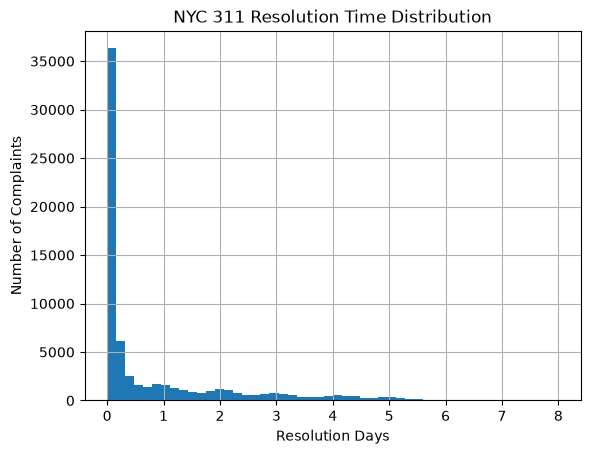

In [168]:


df['resolution_days'].dropna().hist(bins=50)

plt.xlabel('Resolution Days')
plt.ylabel('Number of Complaints')
plt.title('NYC 311 Resolution Time Distribution')

plt.show()

In [169]:
agent_resolution=df.groupby('agency')['resolution_days'].agg(["count","mean","median"]).sort_values("mean",ascending=False)
agent_resolution

,count,mean,median
agency,,,
OTI,4,2.646739,2.553056
DOHMH,466,2.547644,2.021042
HPD,16121,2.425512,2.157697
TLC,153,2.260765,2.577708
OOS,18,1.939060,1.425984
DCWP,130,1.776030,1.714259
DSNY,4218,1.375597,1.088108
DPR,466,1.364916,0.697841
DOT,2753,1.319925,0.833507


In [170]:
df.groupby('agency')['resolution_days'].agg(
    ['count', 'mean', 'median',"min","max"]
)

,count,mean,median,min,max
agency,,,,,
DCWP,130,1.776030,1.714259,0.378519,6.722049
DEP,2415,1.024559,0.567060,0.000000,7.994514
DHS,1981,0.340370,0.221088,0.002963,5.578588
DOB,1092,1.161568,0.562274,0.000000,7.044757
DOHMH,466,2.547644,2.021042,0.027813,7.992477
DOT,2753,1.319925,0.833507,0.000000,7.922708
DPR,466,1.364916,0.697841,0.000590,7.520602
DSNY,4218,1.375597,1.088108,0.000174,6.869456
EDC,0,NaN,NaN,NaN,NaN


In [171]:
df.groupby('agency').agg(
    total_complaints=('agency', 'size'),
    valid_resolution=('resolution_days', 'count'),
    missing_resolution=('resolution_days', 'size')
)

,total_complaints,valid_resolution,missing_resolution
agency,,,
DCWP,537,130,537
DEP,4811,2415,4811
DHS,2071,1981,2071
DOB,2911,1092,2911
DOHMH,1933,466,1933
DOT,5606,2753,5606
DPR,1671,466,1671
DSNY,6357,4218,6357
EDC,98,0,98


In [172]:
missing_resolution=('resolution_days', 'size')
missing_resolution

('resolution_days', 'size')

In [173]:
agency_check = df.groupby('agency').agg(
    total_complaints=('agency', 'size'),
    valid_resolution=('resolution_days', 'count'),
    missing_resolution=(
        'resolution_days',
        lambda x: x.isna().sum()
    )
)

agency_check

,total_complaints,valid_resolution,missing_resolution
agency,,,
DCWP,537,130,407
DEP,4811,2415,2396
DHS,2071,1981,90
DOB,2911,1092,1819
DOHMH,1933,466,1467
DOT,5606,2753,2853
DPR,1671,466,1205
DSNY,6357,4218,2139
EDC,98,0,98


In [174]:
edc_df = df[df['agency'] == 'EDC']

edc_df[[
    'agency',
    'status',
    'created_date',
    'closed_date',
    'resolution_days'
]].head(100)

,agency,status,created_date,closed_date,resolution_days
3644,EDC,IN PROGRESS,2026-11-20 18:05:46,NaT,NaN
3666,EDC,IN PROGRESS,2026-11-20 18:02:56,NaT,NaN
3692,EDC,IN PROGRESS,2026-11-20 17:59:53,NaT,NaN
3841,EDC,IN PROGRESS,2026-11-20 17:40:24,NaT,NaN
4172,EDC,IN PROGRESS,2026-11-20 16:56:24,NaT,NaN
...,...,...,...,...,...
87897,EDC,IN PROGRESS,2026-11-13 16:17:45,NaT,NaN
87914,EDC,IN PROGRESS,2026-11-13 16:17:02,NaT,NaN
88093,EDC,IN PROGRESS,2026-11-13 16:02:18,NaT,NaN
88261,EDC,IN PROGRESS,2026-11-13 15:48:05,NaT,NaN


In [175]:
edc_df['status'].value_counts(dropna=False)

status
IN PROGRESS    98
Name: count, dtype: int64

In [176]:
Target_columns="resolution_days"
feature_columns = [
    'agency',
    'complaint_type',
    'descriptor_clean',
    'location_type_clean',
    'borough',
    'incident_zip_clean',
    'community_board',
    'council_district',
    'latitude',
    'longitude'
]


In [177]:
complaint_type_resolution=df.groupby('complaint_type')['resolution_days'].agg(["count","mean","median","min","max"]).sort_values("mean",ascending=False)
complaint_type_resolution.head(10)

,count,mean,median,min,max
complaint_type,,,,,
DRINKING WATER,2,6.764606,6.764606,6.517569,7.011644
ROOT/SEWER/SIDEWALK CONDITION,1,6.030822,6.030822,6.030822,6.030822
UNSANITARY ANIMAL PVT PROPERTY,9,5.065100,5.434317,1.245208,7.992477
HIGHWAY SIGN - DAMAGED,3,5.063426,4.891146,4.637361,5.661771
CURB CONDITION,35,4.977154,4.229699,0.203924,7.148252
UNSANITARY PIGEON CONDITION,10,4.743478,4.685318,1.492257,7.860486
FOR HIRE VEHICLE COMPLAINT,1,4.534479,4.534479,4.534479,4.534479
OUTSIDE BUILDING,2,3.983588,3.983588,2.836238,5.130937
ILLEGAL ANIMAL KEPT AS PET,2,3.892106,3.892106,2.457986,5.326227


In [178]:
complaint_resolution=df.groupby('complaint_type')['resolution_days'].agg(["count","mean","median","min","max"]).reset_index()
complaint_resolution = complaint_resolution[
    complaint_resolution['count'] >= 30
]
complaint_resolution = complaint_resolution.sort_values(
    'mean', ascending=False
)
complaint_resolution.head(20)

,complaint_type,count,mean,median,min,max
29,CURB CONDITION,35,4.977154,4.229699,0.203924,7.148252
119,RODENT,112,3.637103,3.574971,1.206100,7.411030
38,DOOR/WINDOW,271,3.194934,3.045868,0.214630,7.898600
154,WATER LEAK,299,3.145724,2.999294,0.214630,7.881979
121,SAFETY,157,3.114566,2.967002,0.290359,7.898600
146,UNSANITARY CONDITION,581,3.020195,2.861655,0.066412,7.633241
133,STREET SIGN - DANGLING,46,3.002295,2.814988,0.031817,7.922708
50,FLOORING/STAIRS,139,2.924425,2.653356,0.281389,7.333646
131,STREET LIGHT CONDITION,96,2.844734,2.602083,0.000000,7.225694
108,PAINT/PLASTER,501,2.735767,2.227847,0.214630,7.881979


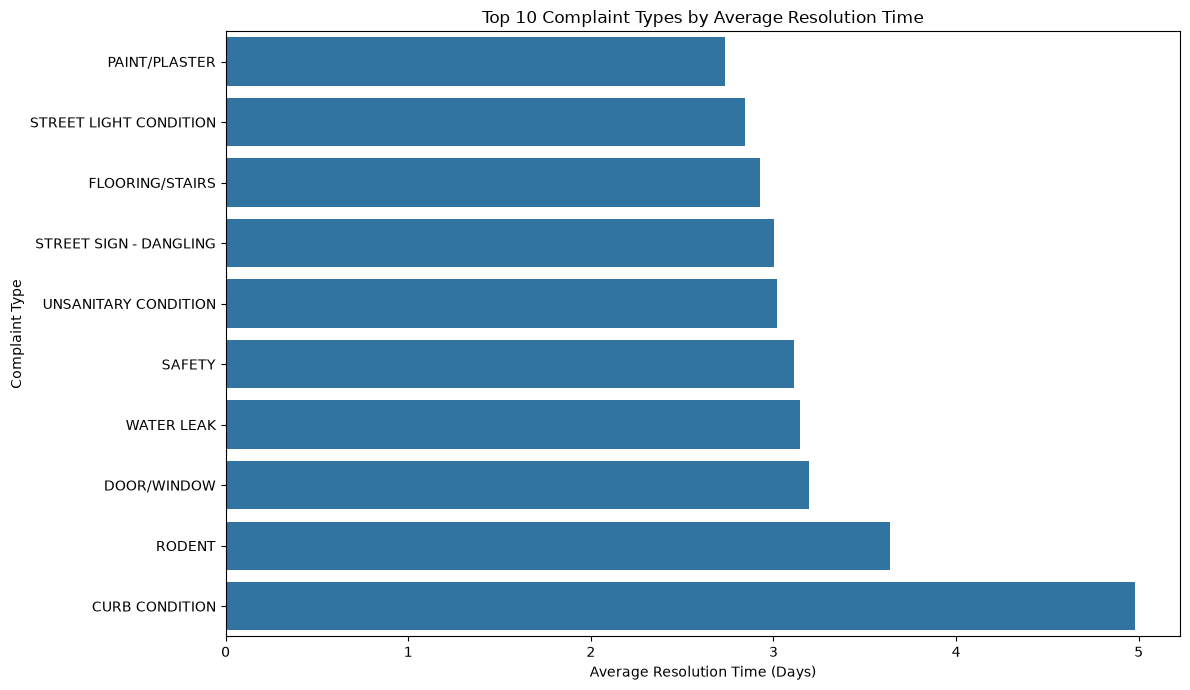

In [179]:


top10 = complaint_resolution.head(10).sort_values(
    'mean', ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x='mean',
    y='complaint_type'
)

plt.xlabel('Average Resolution Time (Days)')
plt.ylabel('Complaint Type')
plt.title('Top 10 Complaint Types by Average Resolution Time')

plt.tight_layout()
plt.show()

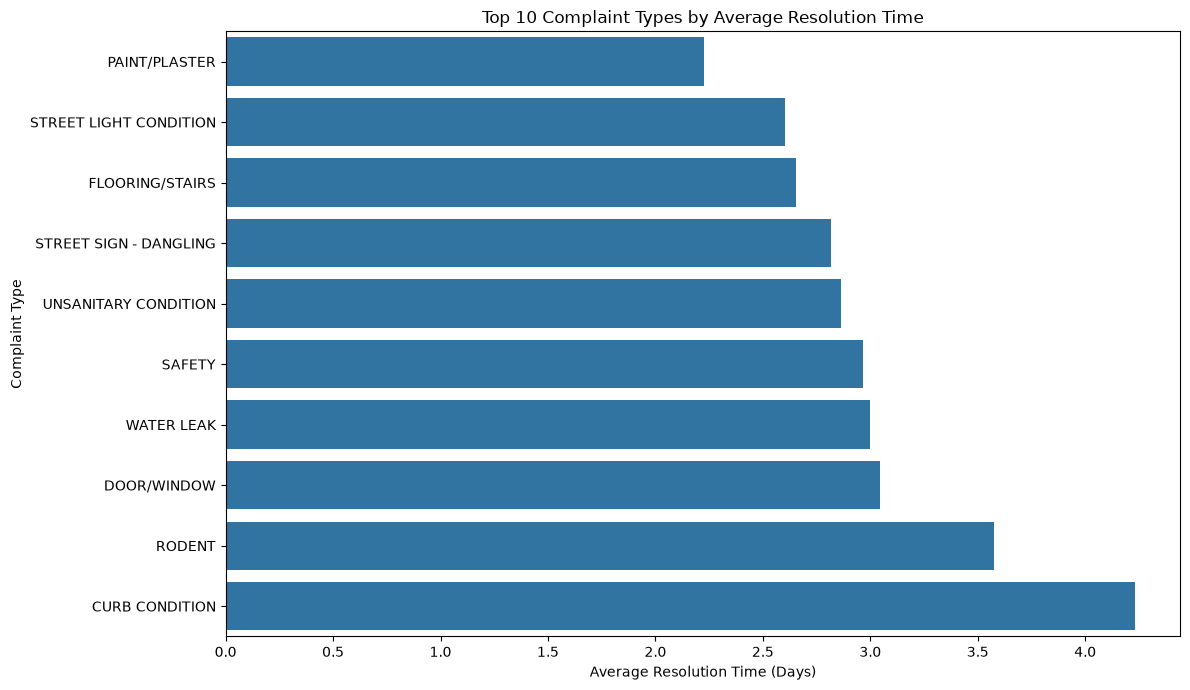

In [180]:
top10 = complaint_resolution.head(10).sort_values(
    'median', ascending=True
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x='median',
    y='complaint_type'
)

plt.xlabel('Average Resolution Time (Days)')
plt.ylabel('Complaint Type')
plt.title('Top 10 Complaint Types by Average Resolution Time')

plt.tight_layout()
plt.show()

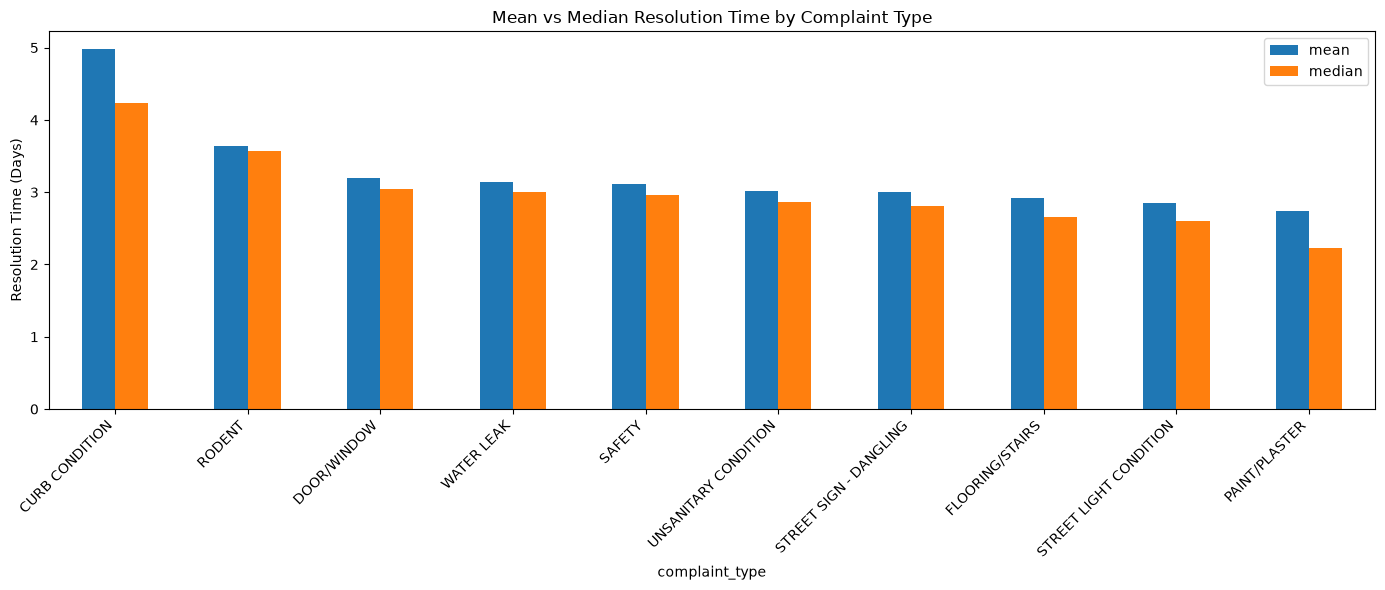

In [181]:
top10_compare = complaint_resolution.head(10)

top10_compare.plot(
    x='complaint_type',
    y=['mean', 'median'],
    kind='bar',
    figsize=(14, 6)
)

plt.ylabel('Resolution Time (Days)')
plt.title('Mean vs Median Resolution Time by Complaint Type')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

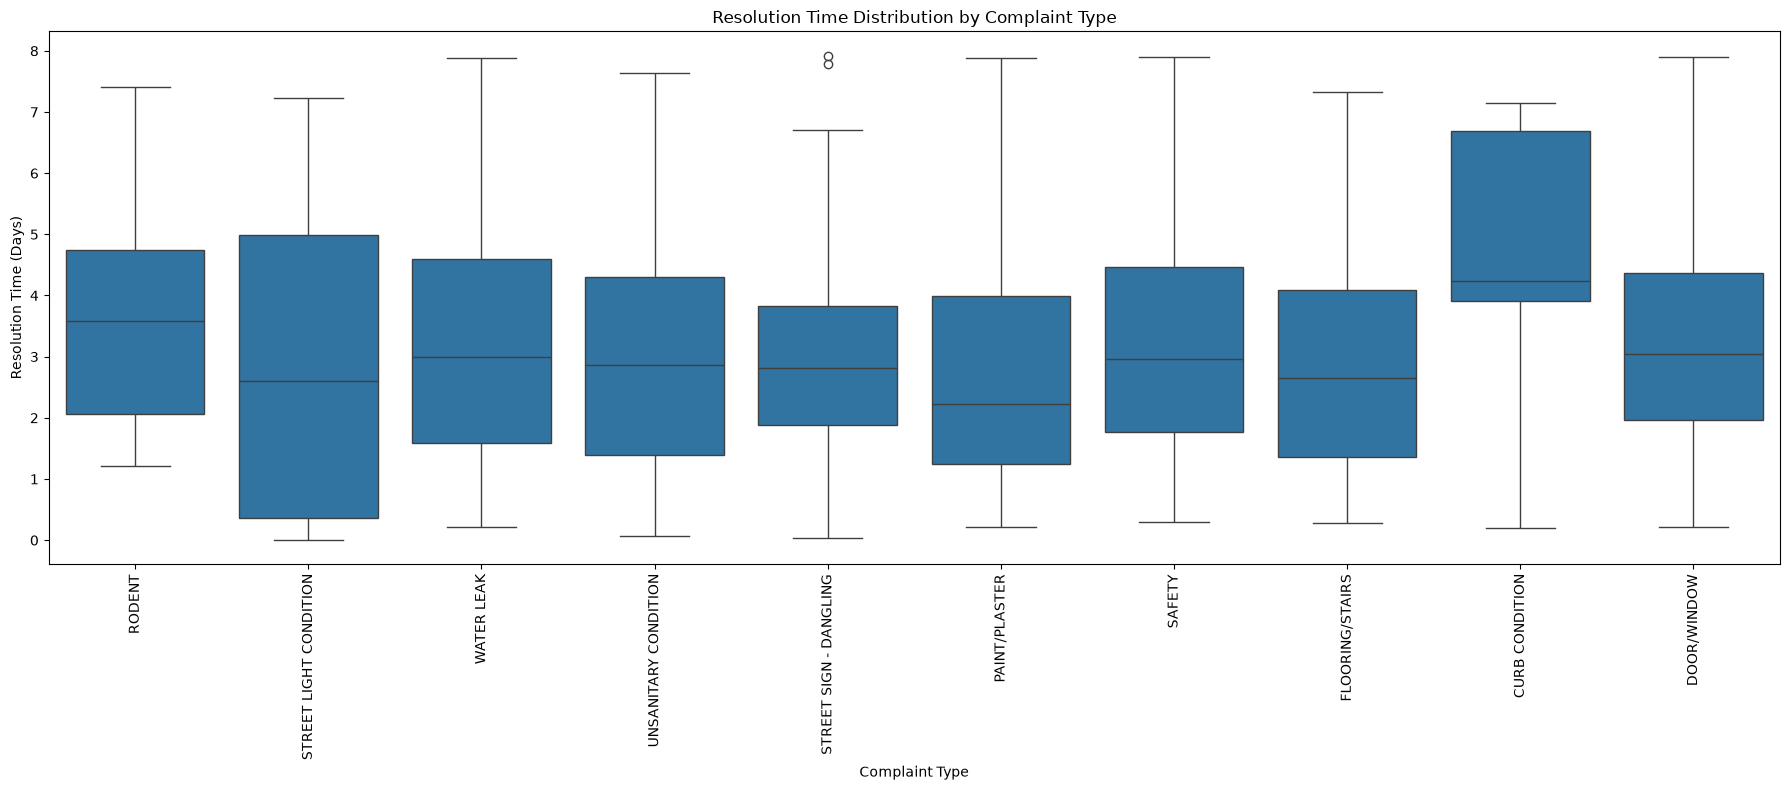

In [182]:
selected_type=complaint_resolution.head(10).sort_values('mean',ascending=False)['complaint_type'].tolist()

selected_df = df[df['complaint_type'].isin(selected_type)]


plt.figure(figsize=(18, 8))

sns.boxplot(
    data=selected_df,
    x='complaint_type',
    y='resolution_days'
)
plt.xlabel('Complaint Type')
plt.ylabel('Resolution Time (Days)')
plt.title('Resolution Time Distribution by Complaint Type')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [183]:
# Categorical columns = object (text) + bool (True/False) columns

cat_colums = df.select_dtypes(include=['object', 'bool']).columns.drop(
    [
        'descriptor_2',
        'descriptor_original',
        'descriptor_merged',
        'location_type_clean',
        'incident_zip_clean',
        'zip_validation',
        'incident_address_clean',
        'due_date_estimated'
    ],
    errors='ignore'
)
cat_colums,len(cat_colums)
#cat_colums.columns,len(cat_colums.columns)

C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\2173273626.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_colums = df.select_dtypes(include=['object', 'bool']).columns.drop(


(Index(['agency', 'agency_name', 'complaint_type', 'descriptor',
        'incident_address', 'status', 'resolution_description',
        'community_board', 'police_precinct', 'borough',
        'open_data_channel_type', 'park_facility_name', 'facility_type',
        'location_type', 'city', 'descriptor_2_clean', 'is_closed'],
       dtype='str'),
 17)

agency


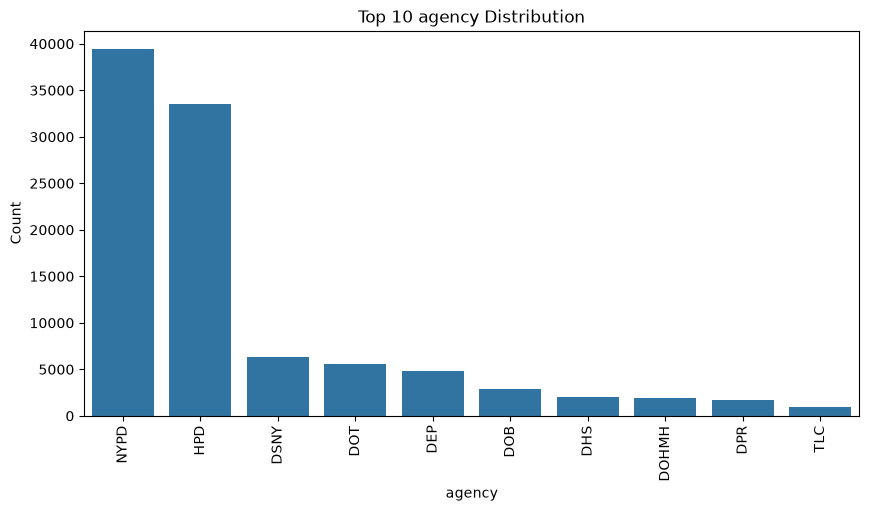

agency_name


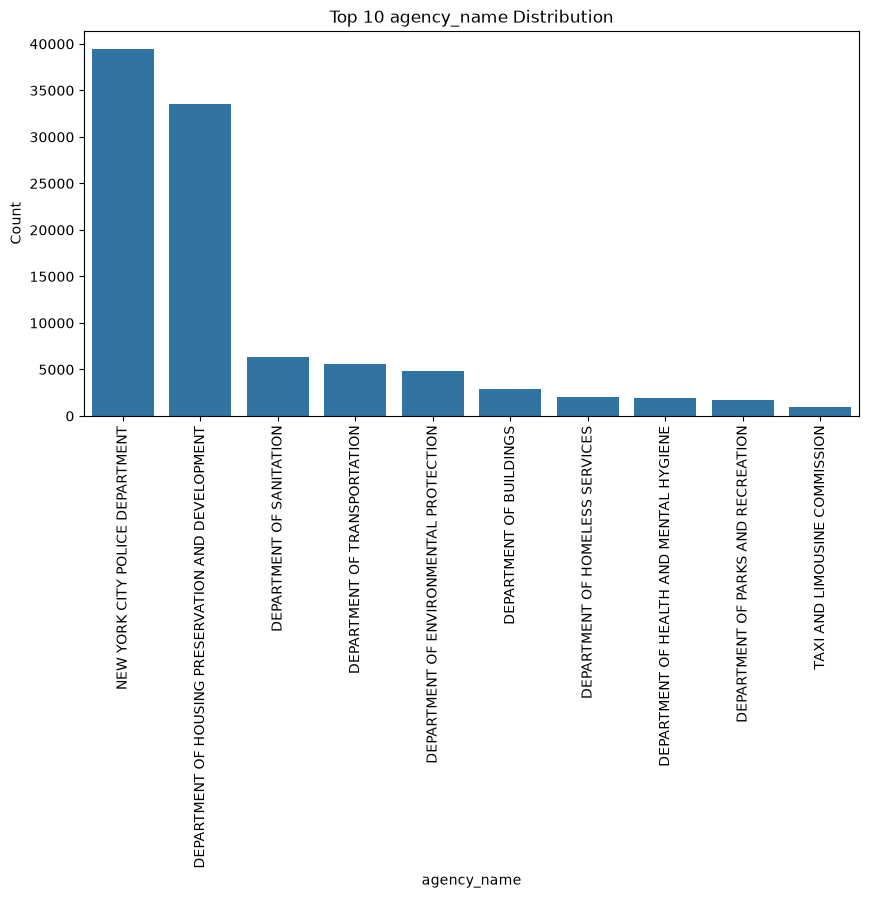

complaint_type


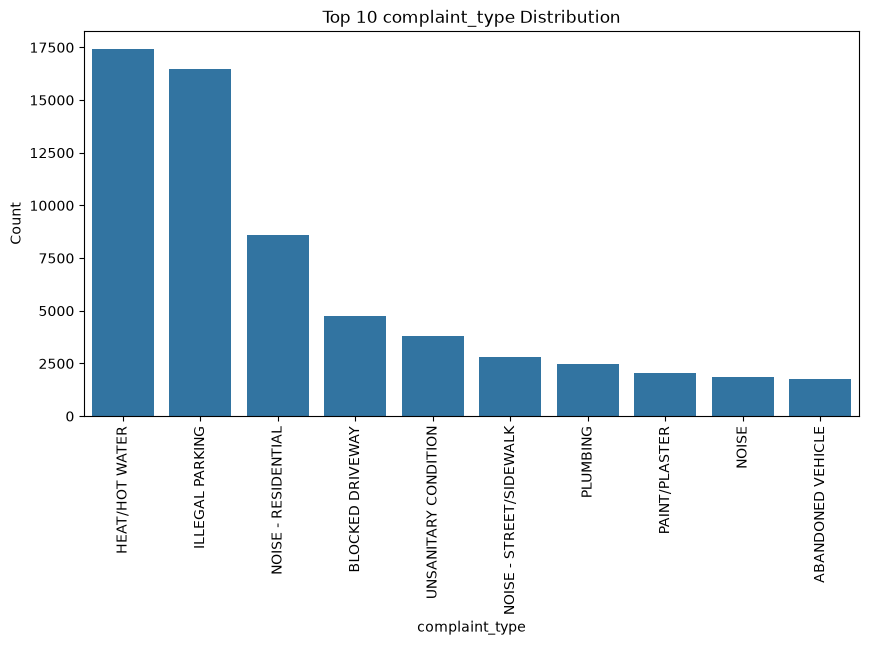

descriptor


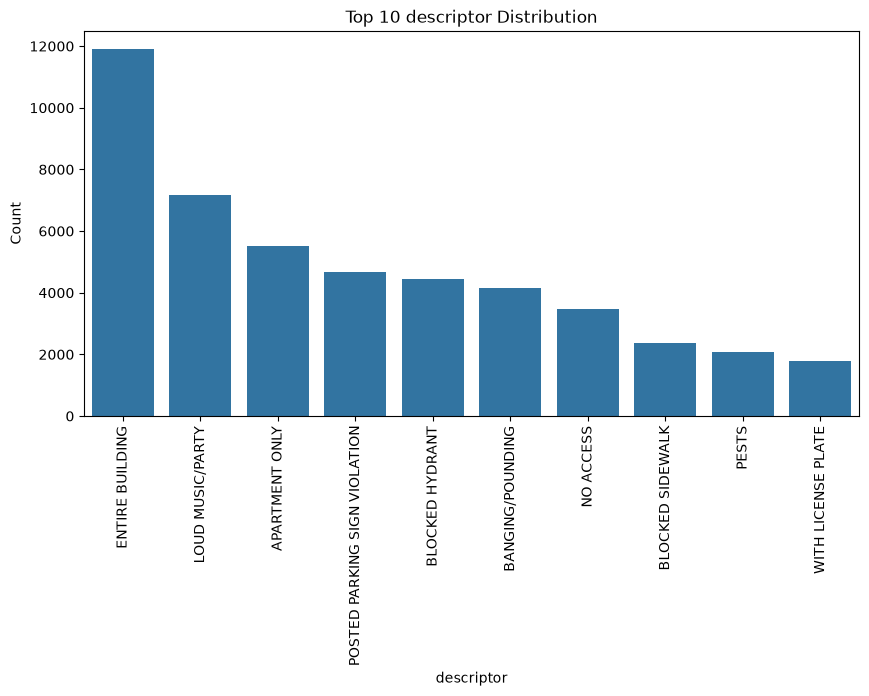

incident_address


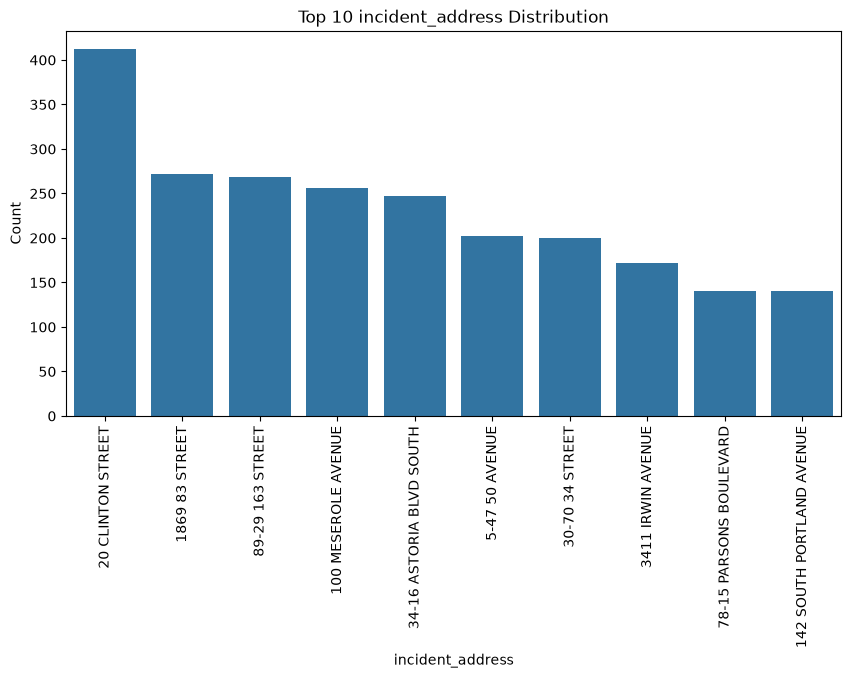

status


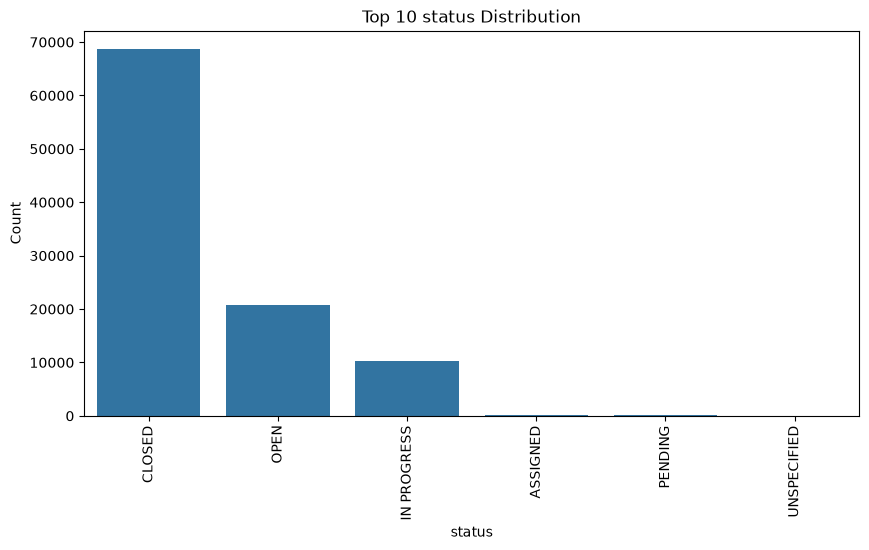

resolution_description


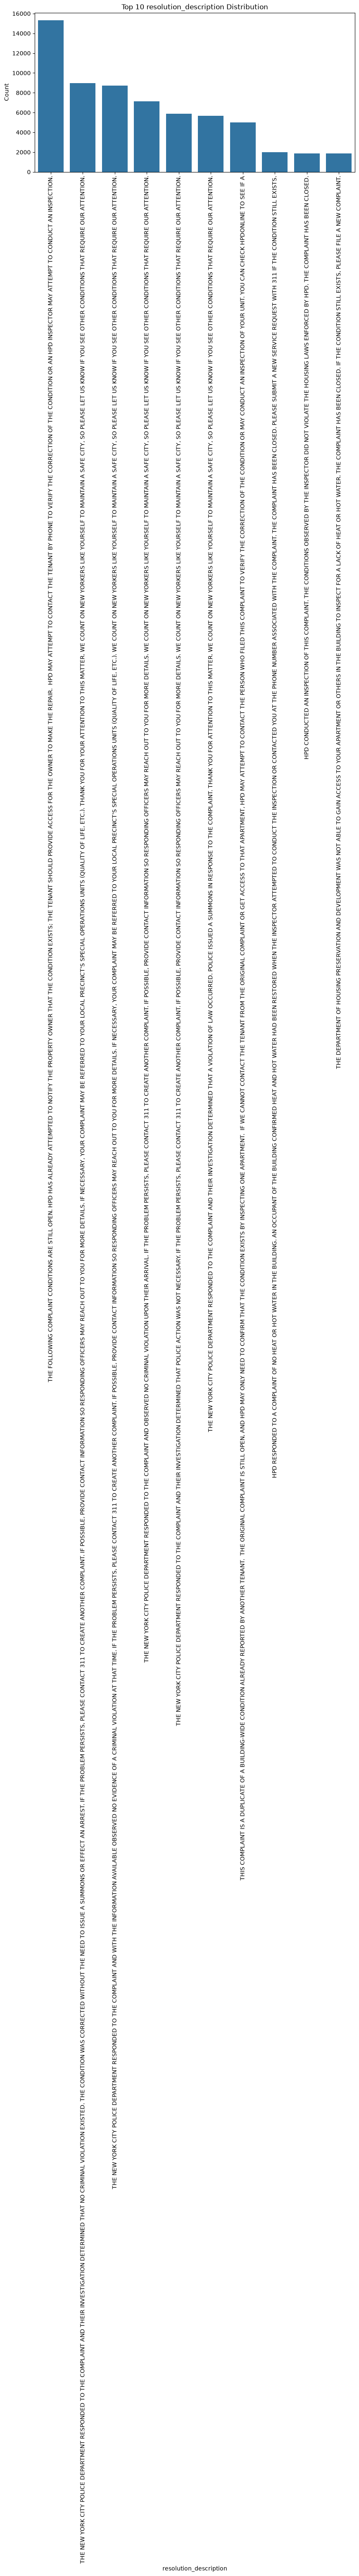

community_board


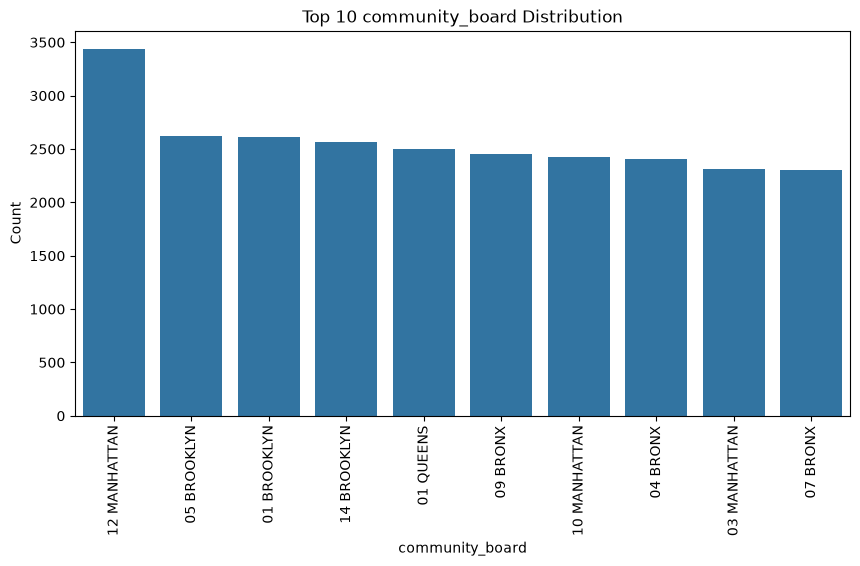

police_precinct


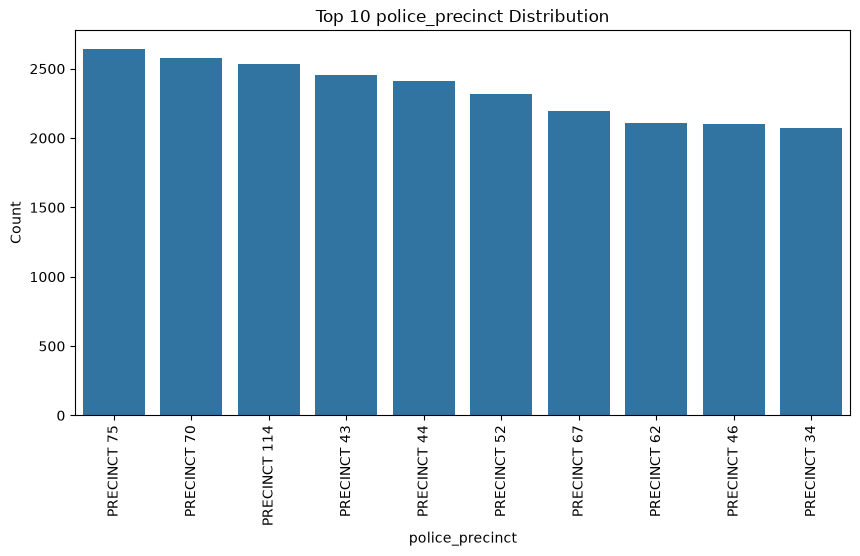

borough


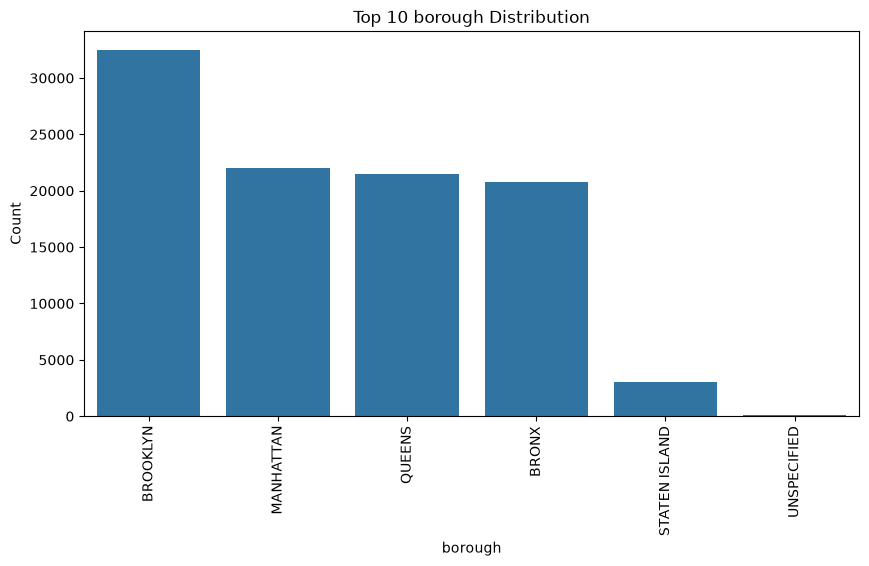

open_data_channel_type


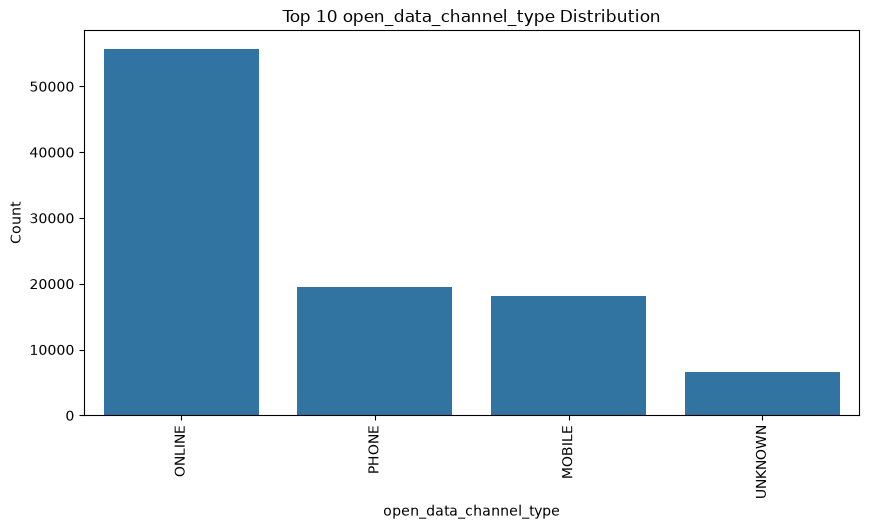

park_facility_name


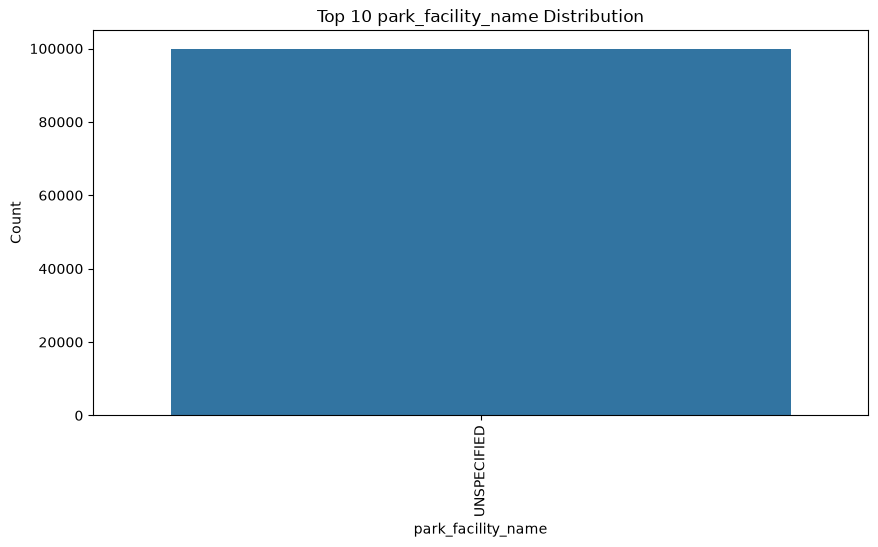

facility_type


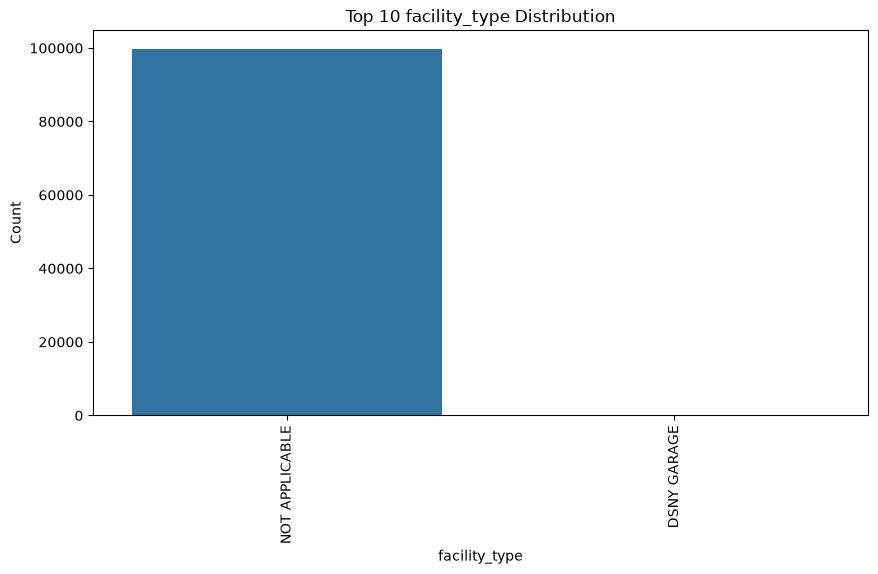

location_type


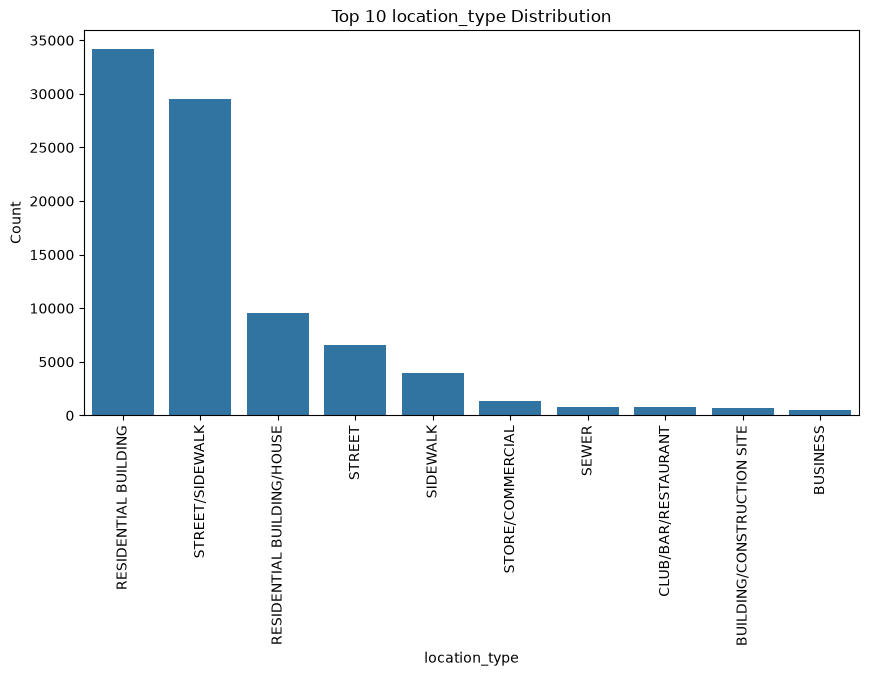

city


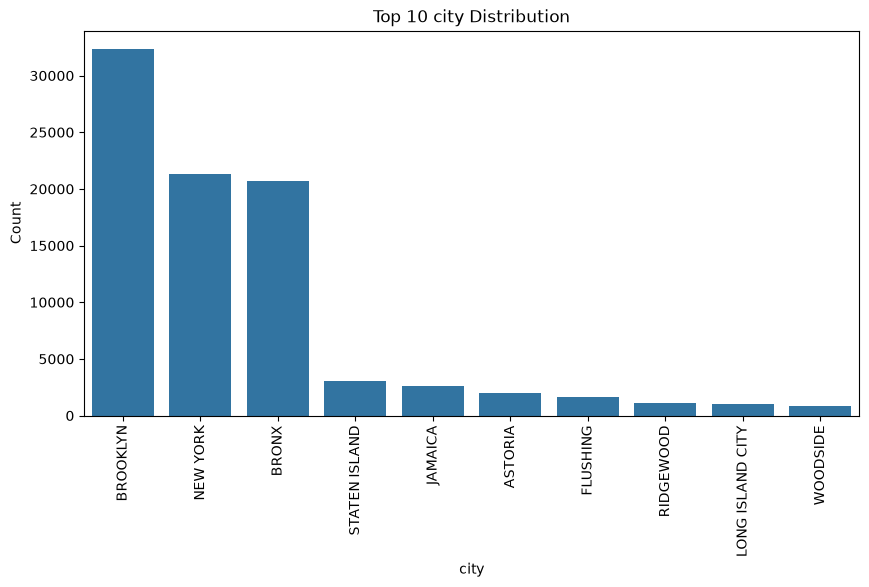

descriptor_2_clean


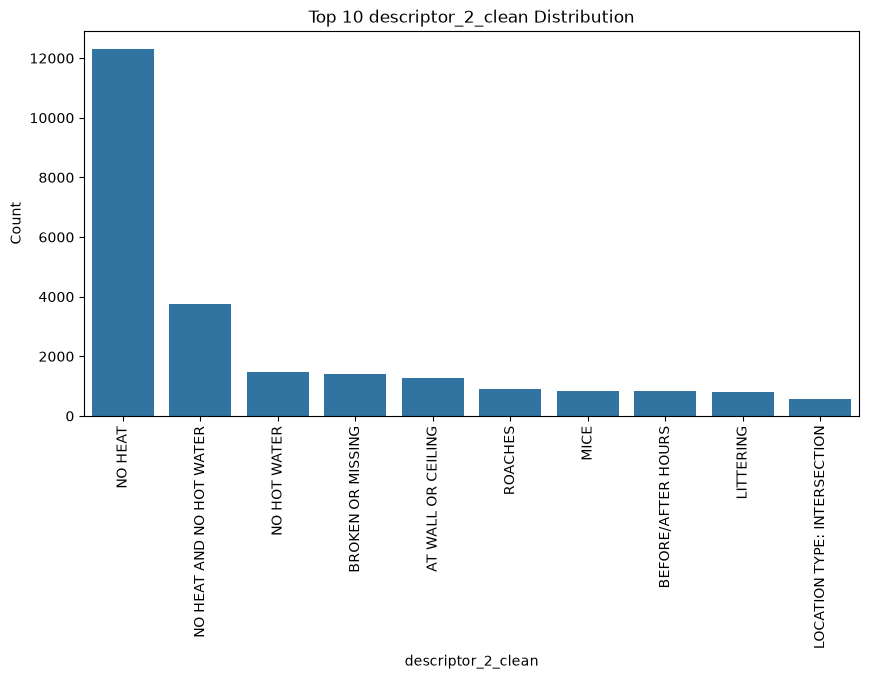

is_closed


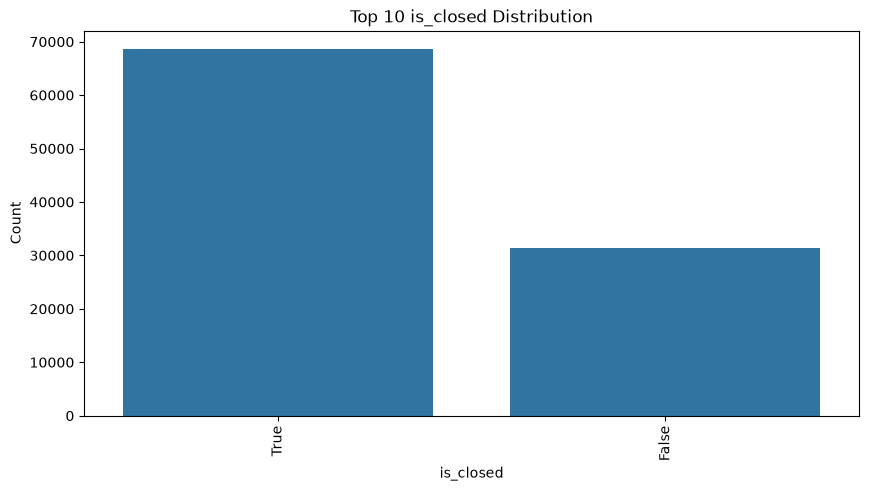

In [184]:
for clm in cat_colums:
     if clm not in ['resolution_days']:
        plt.figure(figsize=(10,5))
        print(clm)
        top_10 = df[clm].value_counts().head(10)
        sns.countplot(
            data=df[df[clm].isin(top_10.index)],
            x=clm,
            order=top_10.index
        )
        plt.xticks(rotation=90)
        plt.xlabel(f'{clm}')
        plt.ylabel('Count')
        plt.title(f'Top 10 {clm} Distribution')
        plt.show()

In [185]:
Num_colums=df.select_dtypes(include=['int64','float64','int32'])
Num_colums.columns,len(Num_colums.columns)

(Index(['unique_key', 'incident_zip', 'council_district', 'latitude',
        'longitude', 'created_month', 'created_weekday', 'created_hour',
        'resolution_hours', 'resolution_days'],
       dtype='str'),
 10)

In [186]:
df[['incident_zip','council_district', 'latitude', 'longitude']]

,incident_zip,council_district,latitude,longitude
0,NaN,<NA>,40.832616,-73.864167
1,10035.0,8,40.800524,-73.931565
2,11377.0,26,40.739018,-73.919536
3,10461.0,18,40.841247,-73.849787
4,10003.0,2,40.726870,-73.988909
...,...,...,...,...
99995,11239.0,42,40.653381,-73.876511
99996,10011.0,3,40.745977,-74.000083
99997,11216.0,35,40.670125,-73.955271
99998,11354.0,19,40.769812,-73.820683


In [187]:
# Numeric DISCRETE columns (few whole-number values)
Num_Disc=['created_weekday','created_month','created_hour']
df[Num_Disc]

,created_weekday,created_month,created_hour
0,5,11,2
1,5,11,2
2,5,11,2
3,5,11,2
4,5,11,2
...,...,...,...
99995,3,11,16
99996,3,11,16
99997,3,11,16
99998,3,11,16


In [188]:
df[['created_weekday','created_month','created_hour']].describe()

,created_weekday,created_month,created_hour
count,99998.000000,99998.0,99998.000000
mean,3.063431,11.0,13.168033
std,1.888193,0.0,6.015447
min,0.000000,11.0,0.000000
25%,1.000000,11.0,9.000000
50%,3.000000,11.0,13.000000
75%,4.000000,11.0,18.000000
max,6.000000,11.0,23.000000


created_weekday


C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\3093104550.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=clm,data=df,order=df[clm].value_counts().index,palette="pastel")


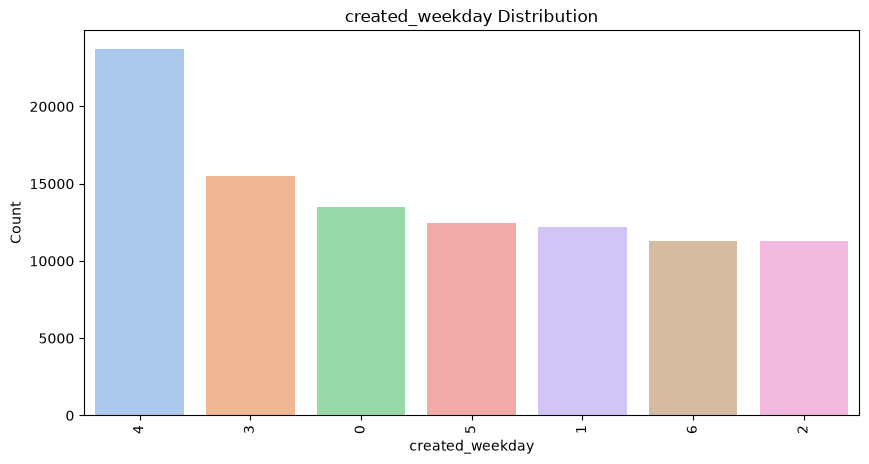

created_month


C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\3093104550.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=clm,data=df,order=df[clm].value_counts().index,palette="pastel")


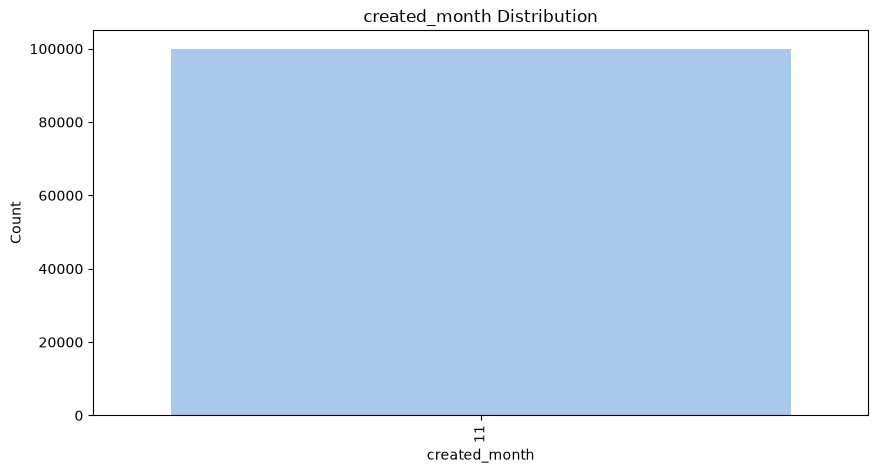

created_hour


C:\Users\Hxtreme\AppData\Local\Temp\ipykernel_24300\3093104550.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=clm,data=df,order=df[clm].value_counts().index,palette="pastel")


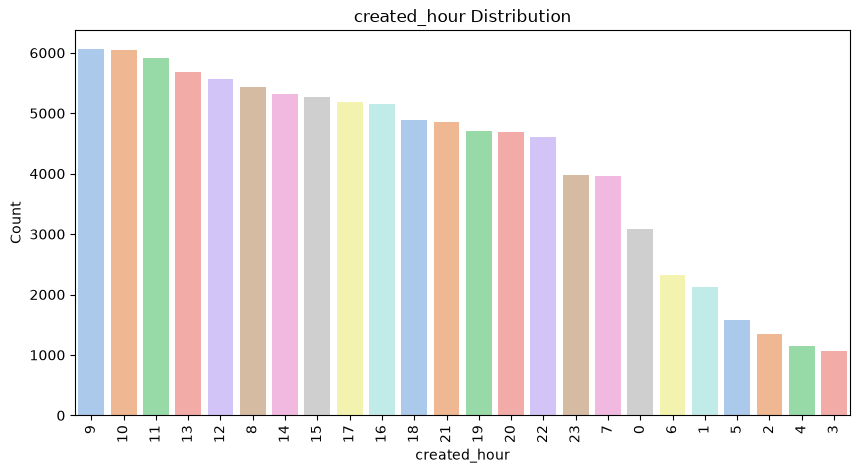

In [189]:
# Countplot for each discrete numeric column
for clm in Num_Disc:

        plt.figure(figsize=(10,5))
        print(clm)
        sns.countplot(x=clm,data=df,order=df[clm].value_counts().index,palette="pastel")
        plt.xticks(rotation=90)
        plt.xlabel(f'{clm}')
        plt.ylabel('Count')
        plt.title(f'{clm} Distribution')
        plt.show()

In [190]:
Num_cont=['incident_zip', 'council_district', 'latitude', 'longitude','resolution_days']

incident_zip


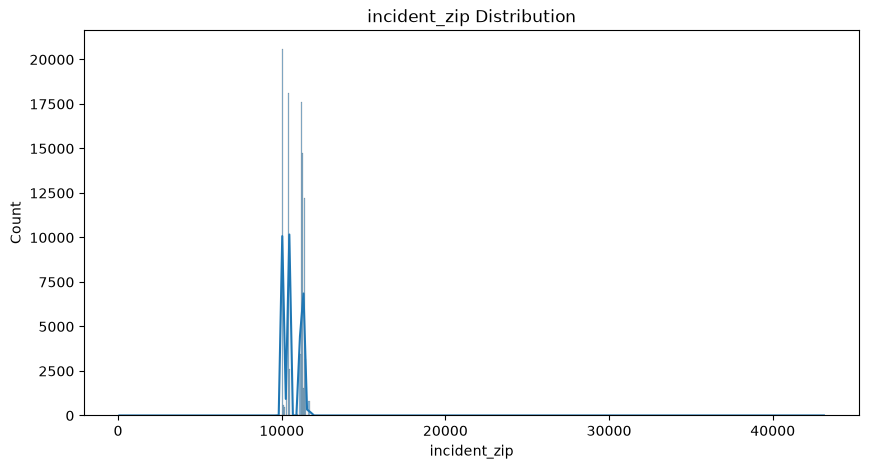

council_district


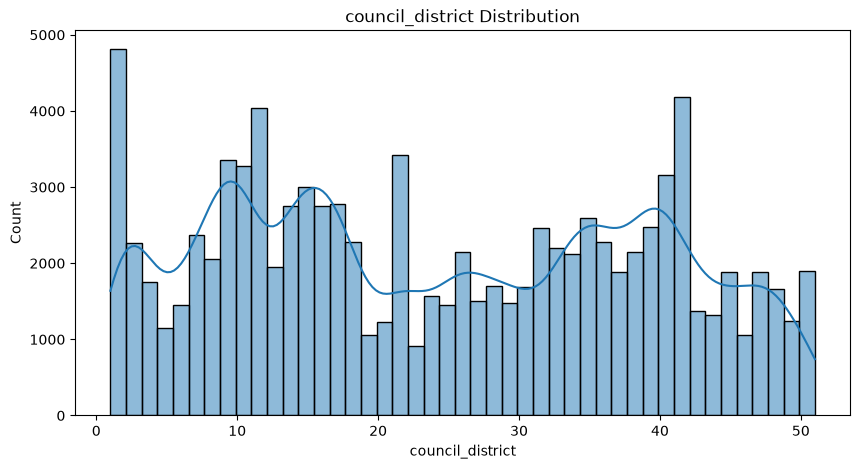

latitude


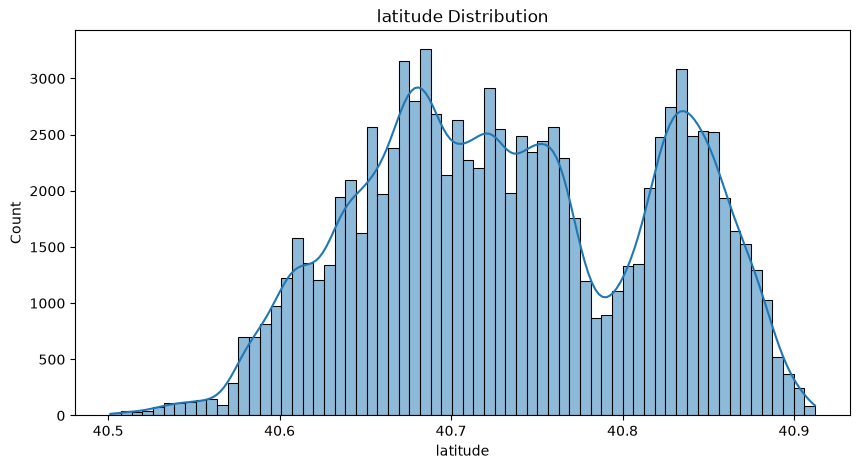

longitude


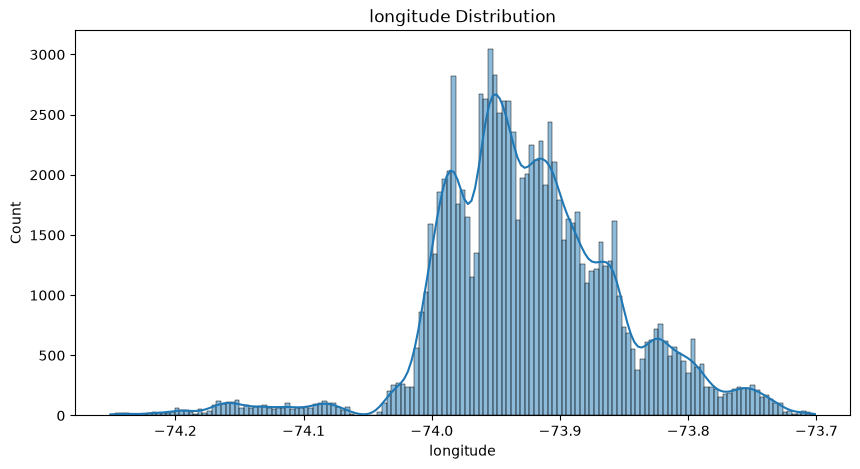

resolution_days


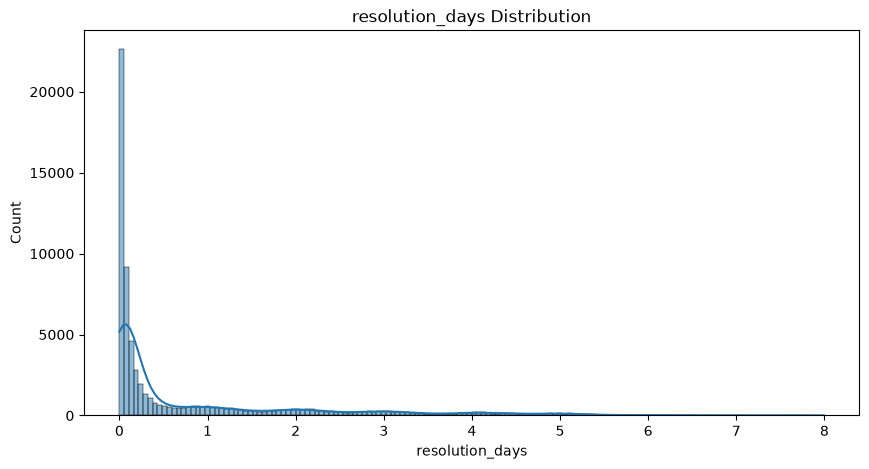

In [191]:
# Histogram + KDE curve for each continuous column - check shape and skewness
for clm in Num_cont:
    print(clm)
    plt.figure(figsize=(10,5))
    sns.histplot(df[clm],kde=True)
    plt.xlabel(f'{clm}')
    plt.ylabel('Count')
    plt.title(f'{clm} Distribution')
    plt.show()

incident_zip


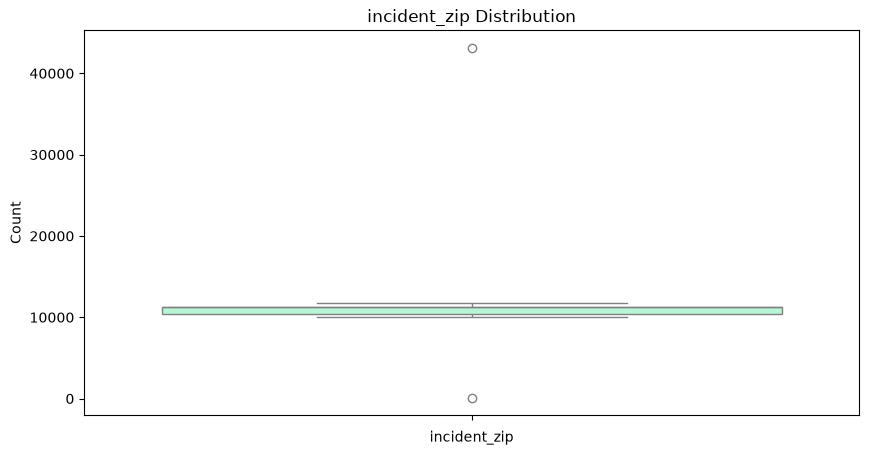

council_district


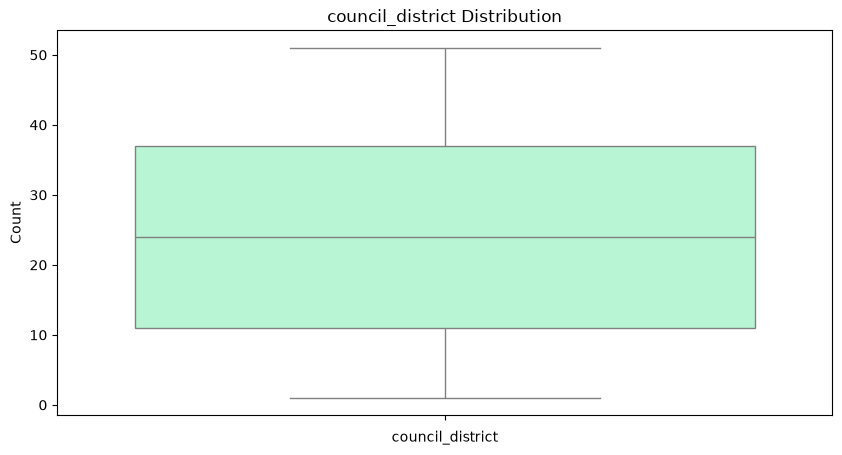

latitude


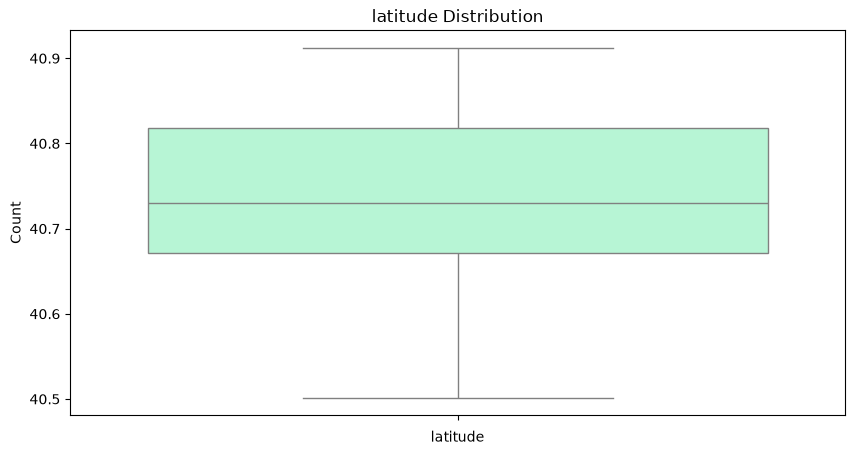

longitude


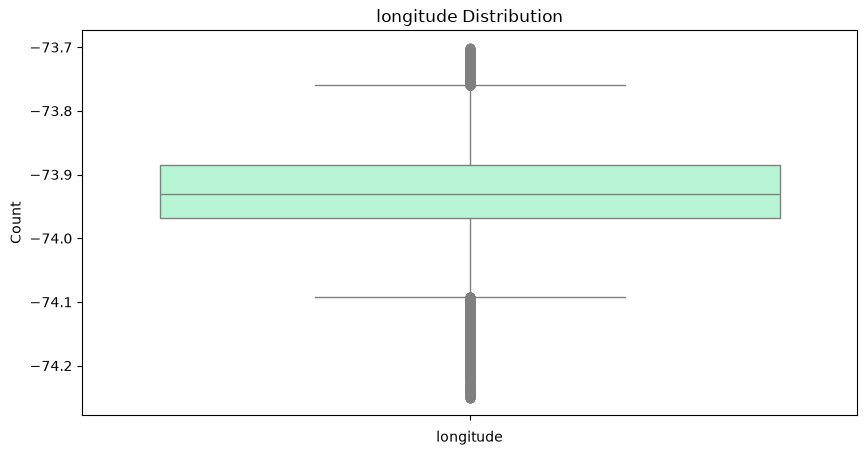

resolution_days


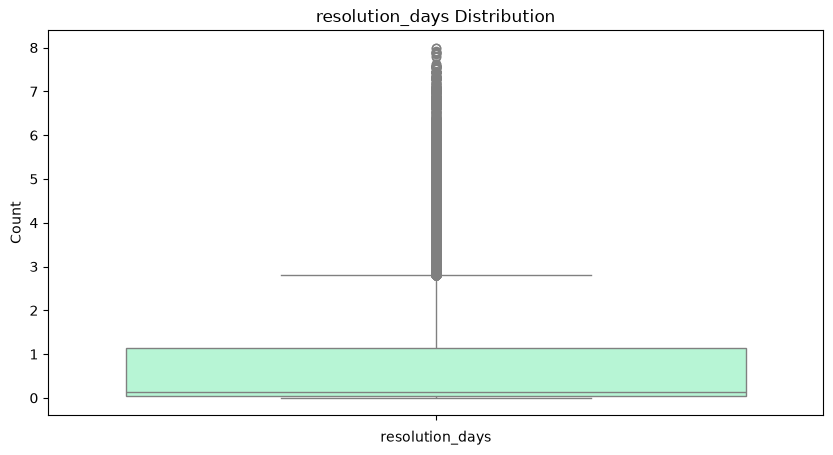

In [192]:
for clm in Num_cont:
    print(clm)
    plt.figure(figsize=(10,5))
    sns.boxplot(df[clm],color='#adffd5')
    plt.xlabel(f'{clm}')
    plt.ylabel('Count')
    plt.title(f'{clm} Distribution')
    plt.show()

In [193]:
#Which agency takes more time to close complaints?
agency_resolution = (
    df.groupby('agency')['resolution_days']
      .agg(['count', 'mean', 'median'])
      .sort_values('mean', ascending=False)
)

agency_resolution

,count,mean,median
agency,,,
OTI,4,2.646739,2.553056
DOHMH,466,2.547644,2.021042
HPD,16121,2.425512,2.157697
TLC,153,2.260765,2.577708
OOS,18,1.939060,1.425984
DCWP,130,1.776030,1.714259
DSNY,4218,1.375597,1.088108
DPR,466,1.364916,0.697841
DOT,2753,1.319925,0.833507


In [194]:
#Which complaint type takes more time?
complaint_resolution = (
    df.groupby('complaint_type')['resolution_days']
      .agg(['count', 'mean', 'median'])
      .sort_values('mean', ascending=False)
)

complaint_resolution.head(10)

,count,mean,median
complaint_type,,,
DRINKING WATER,2,6.764606,6.764606
ROOT/SEWER/SIDEWALK CONDITION,1,6.030822,6.030822
UNSANITARY ANIMAL PVT PROPERTY,9,5.065100,5.434317
HIGHWAY SIGN - DAMAGED,3,5.063426,4.891146
CURB CONDITION,35,4.977154,4.229699
UNSANITARY PIGEON CONDITION,10,4.743478,4.685318
FOR HIRE VEHICLE COMPLAINT,1,4.534479,4.534479
OUTSIDE BUILDING,2,3.983588,3.983588
ILLEGAL ANIMAL KEPT AS PET,2,3.892106,3.892106


In [195]:
#Which borough takes more time?
borough_resolution = (
    df.groupby('borough')['resolution_days']
      .agg(['count', 'mean', 'median'])
      .sort_values('mean', ascending=False)
)

borough_resolution

,count,mean,median
borough,,,
UNSPECIFIED,32,1.514312,1.025388
MANHATTAN,14677,1.018385,0.167986
BRONX,13621,0.914725,0.275382
BROOKLYN,22427,0.869485,0.112697
STATEN ISLAND,2044,0.733749,0.106447
QUEENS,15828,0.667021,0.096169


In [196]:
borough_complaint = (df[df['borough']!='UNSPECIFIED']
.groupby(['borough','complaint_type'])['resolution_days']
                     .agg(['count','mean','median','min','max'])
                     .sort_values('mean',ascending=False))
# Consider complaint types with at least 30 records
borough_complaint = borough_complaint[
    borough_complaint['count'] >= 30
]

# Sort by average resolution time
borough_complaint = borough_complaint.sort_values(
    ['borough', 'mean'],
    ascending=[True, False]
)


# Get top 10 complaint types in each borough
top10_borough = (
    borough_complaint
    .groupby('borough')
    .head(10)
)

top10_borough


count      mean    median       min  \
borough       complaint_type                                                  
BRONX         DOOR/WINDOW                 116  2.878725  2.836238  0.214630   
              UNSANITARY CONDITION        199  2.729393  2.196250  0.281389   
              SAFETY                       60  2.660162  2.320023  0.381493   
              WATER LEAK                   77  2.583278  2.139722  0.214630   
              FLOORING/STAIRS              62  2.491324  2.154149  0.281389   
              PLUMBING                    202  2.440780  2.125955  0.008970   
              ELECTRICAL                   81  2.403142  2.338380  0.092280   
              NOISE                        46  2.395617  2.141024  0.180775   
              GENERAL                      90  2.318351  1.634091  0.000000   
              PAINT/PLASTER               181  2.318212  1.790718  0.214630   
BROOKLYN      DOOR/WINDOW                  83  3.519021  3.614479  0.356933   
              FLOORING/STAIRS              38  3.276320  3.646811  0.287338   
              WATER LEAK                  123  3.175718  2.975938  0.292870   
              UNSANITARY CONDITION        177  3.146274  2.992512  0.066412   
              SIDEWALK CONDITION           65  3.014353  2.758542  0.001262   
              HEAT/HOT WATER             3540  2.996723  3.143385  0.001644   
              SAFETY                       33  2.763230  2.620903  0.331088   
              PLUMBING                    181  2.726429  2.588762  0.189722   
              PAINT/PLASTER               174  2.660905  2.181204  0.273102   
              ELECTRICAL                   88  2.571939  2.163466  0.066412   
MANHATTAN     WATER LEAK                   59  3.841071  4.021296  0.319155   
              PAINT/PLASTER                88  3.780088  3.596291  0.246620   
              DOOR/WINDOW                  45  3.736000  3.965694  0.405590   
              UNSANITARY CONDITION         96  3.247987  3.212946  0.290359   
              PLUMBING                    166  3.028959  2.912870  0.000000   
              RODENT                       70  2.976825  2.943310  1.211944   
              AIR QUALITY                  39  2.824650  3.072662  0.005625   
              HEAT/HOT WATER             3018  2.716691  2.702795  0.006111   
              ELECTRICAL                   46  2.699077  2.493154  0.246620   
              SIDEWALK CONDITION           38  2.381524  2.071389  0.001933   
QUEENS        SAFETY                       39  4.080221  4.466817  0.331296   
              WATER LEAK                   37  3.152640  3.002870  0.472280   
              UNSANITARY CONDITION        105  3.106232  2.955648  0.536389   
              PAINT/PLASTER                46  3.060587  2.725613  0.450451   
              SIDEWALK CONDITION           66  3.039132  3.048686  0.006331   
              PLUMBING                    102  2.722794  2.234635  0.000000   
              DAMAGED TREE                 39  2.587710  1.907870  0.002604   
              ELECTRICAL                   57  2.532551  2.288275  0.297593   
              GENERAL                      67  2.347002  1.390197  0.000000   
              INDOOR AIR QUALITY           47  2.246822  1.974861  1.019201   
STATEN ISLAND STREET LIGHT CONDITION       44  2.874400  2.602083  0.000000   
              DEAD ANIMAL                  32  2.348215  2.793218  0.732176   
              HEAT/HOT WATER               97  2.266928  2.117338  0.069398   
              DIRTY CONDITION              32  2.150904  2.026105  0.014225   
              MISSED COLLECTION            35  1.683951  1.667153  0.227488   
              DERELICT VEHICLES            39  1.302066  1.177083  0.152083   
              STREET CONDITION             75  1.069224  0.848704  0.000000   
              SEWER MAINTENANCE            88  1.068796  0.312321  0.004005   
              TRAFFIC SIGNAL CONDITION     43  0.654506  0.103472  0.029861   
           

In [197]:
# Option 1: Reset the index first so 'borough' becomes a standard column
boroughs =top10_borough.reset_index()['borough'].unique()
# Option 2: Access the index level directly
# display(top10_borough.index.get_level_values('borough').unique())

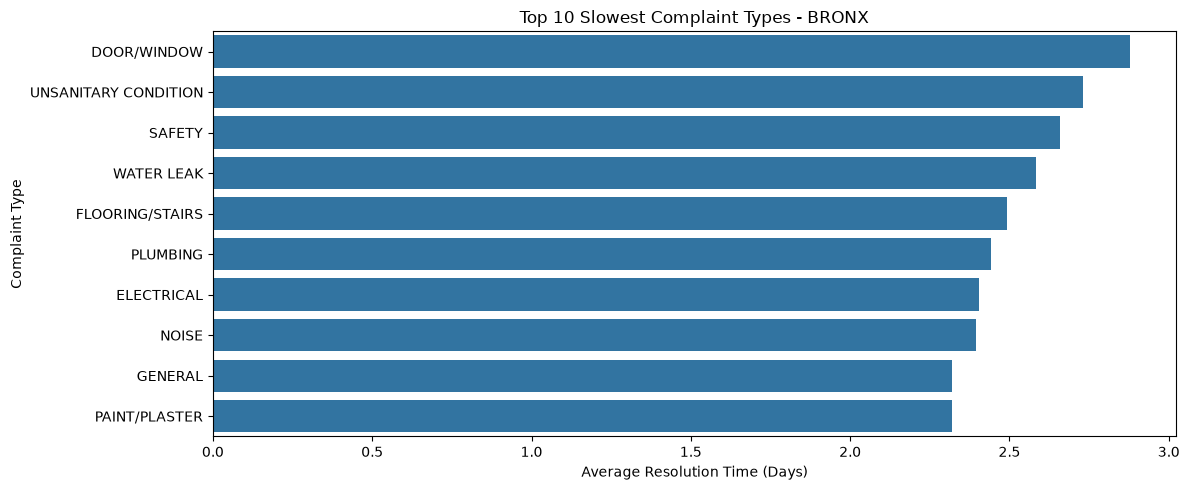

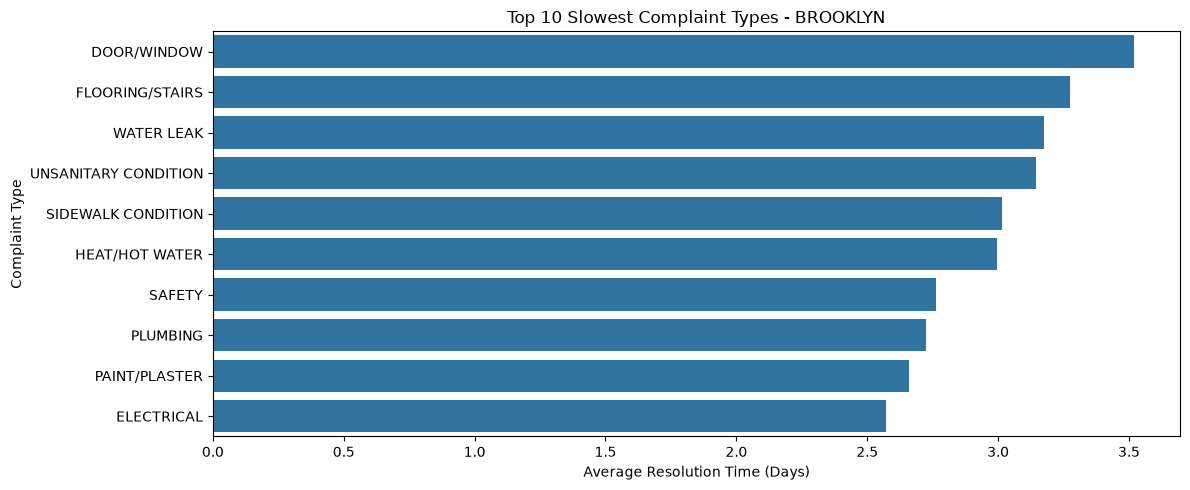

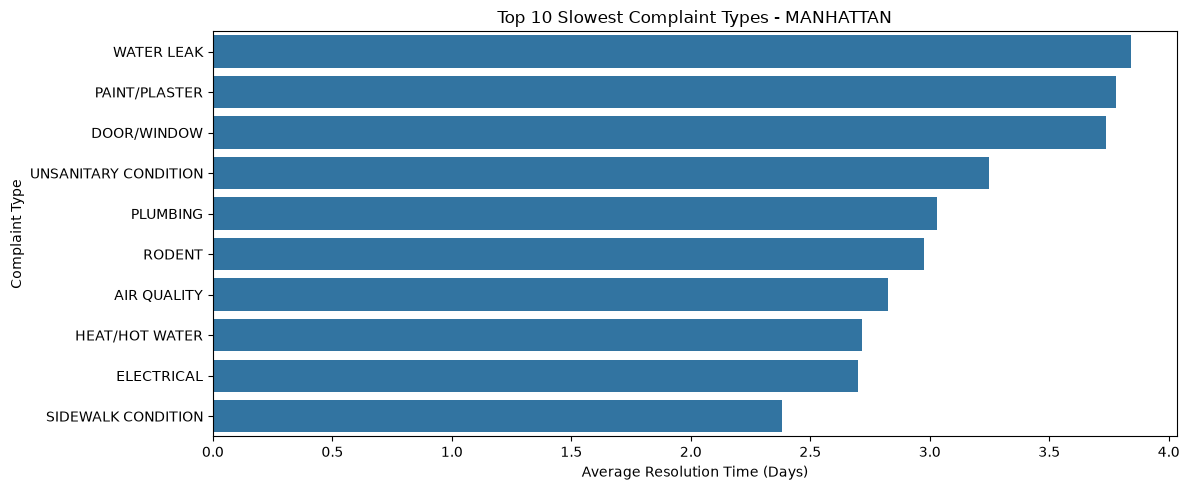

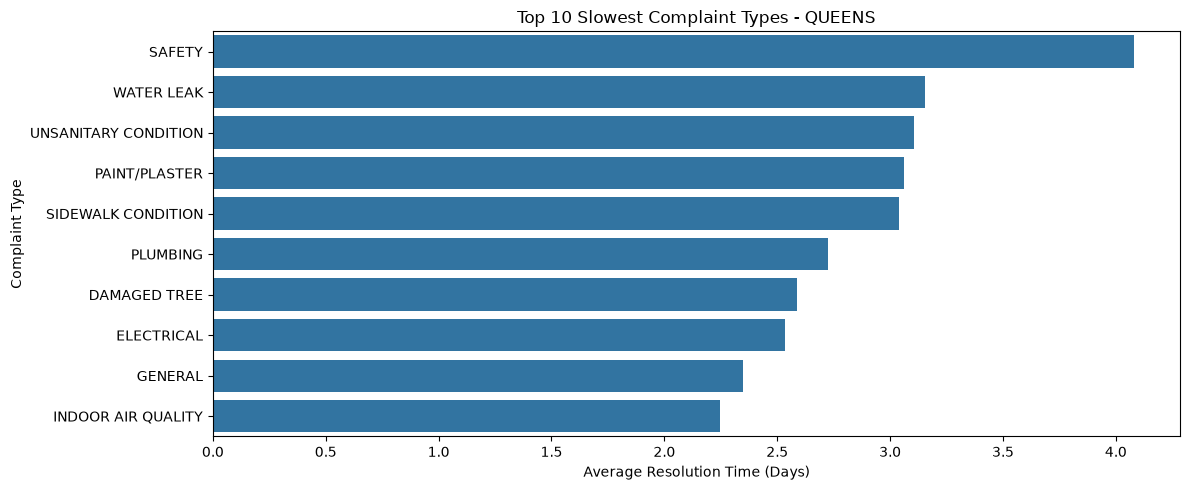

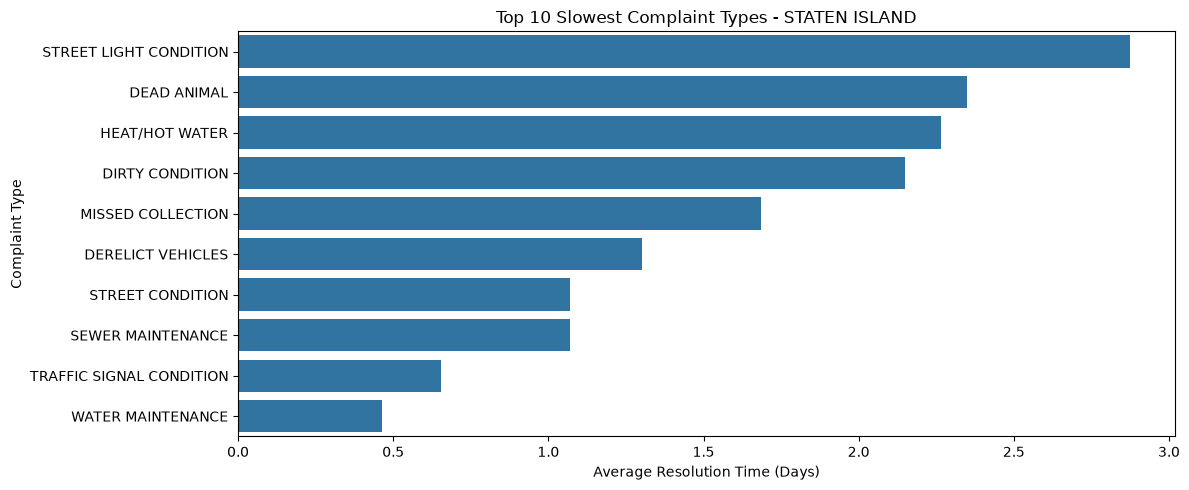

In [198]:
for borough in boroughs:

    selected_df =  top10_borough.reset_index()[
        top10_borough.reset_index()['borough'] == borough
    ]

    plt.figure(figsize=(12, 5))

    sns.barplot(
        data=selected_df,
        x='mean',
        y='complaint_type'
    )

    plt.title(f'Top 10 Slowest Complaint Types - {borough}')
    plt.xlabel('Average Resolution Time (Days)')
    plt.ylabel('Complaint Type')

    plt.tight_layout()
    plt.show()

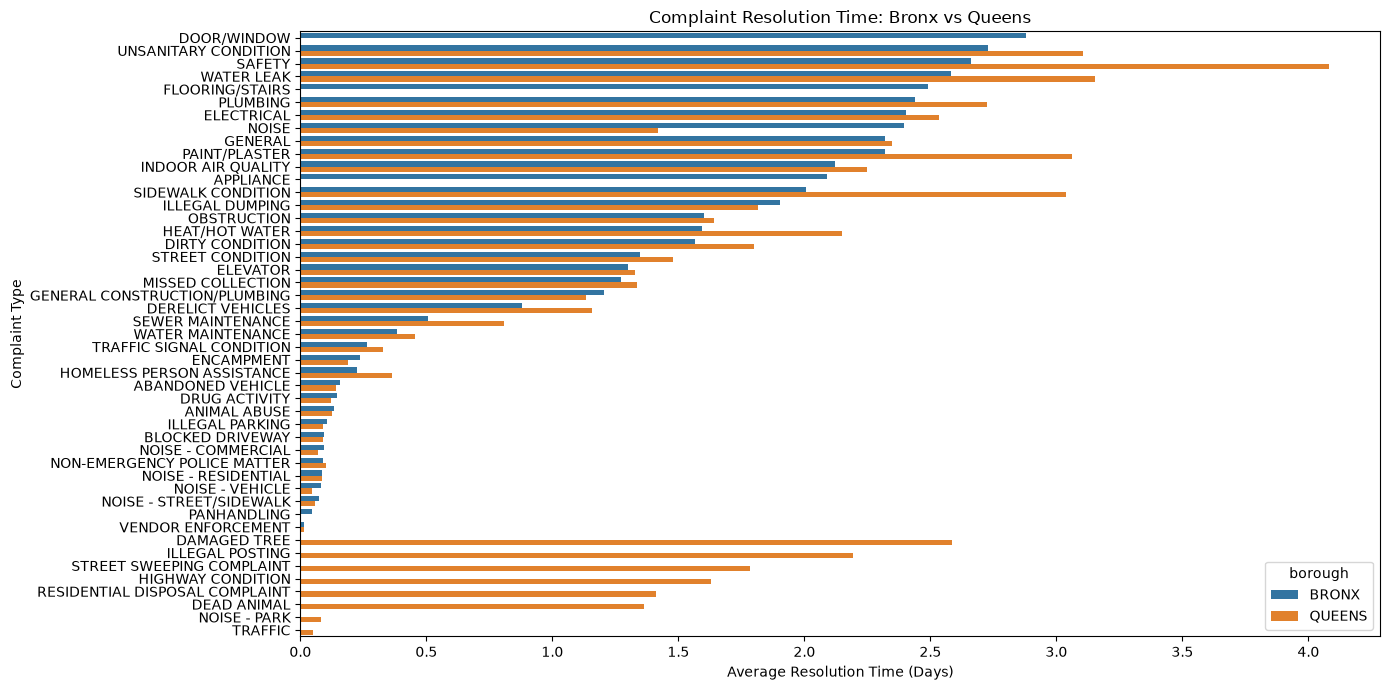

In [199]:
selected_df = borough_complaint.reset_index()[
    borough_complaint.reset_index()['borough'].isin(['BRONX', 'QUEENS'])
]

plt.figure(figsize=(14, 7))

sns.barplot(
    data=selected_df,
    x='mean',
    y='complaint_type',
    hue='borough'
)

plt.title('Complaint Resolution Time: Bronx vs Queens')
plt.xlabel('Average Resolution Time (Days)')
plt.ylabel('Complaint Type')

plt.tight_layout()
plt.show()

In [200]:
overall_delay = (
    df.groupby('complaint_type')['resolution_days']
    .agg(['count', 'mean', 'median'])
    .query('count >= 100')
    .sort_values('mean', ascending=False)
)
overall_delay

,count,mean,median
complaint_type,,,
RODENT,112,3.637103,3.574971
DOOR/WINDOW,271,3.194934,3.045868
WATER LEAK,299,3.145724,2.999294
SAFETY,157,3.114566,2.967002
UNSANITARY CONDITION,581,3.020195,2.861655
FLOORING/STAIRS,139,2.924425,2.653356
PAINT/PLASTER,501,2.735767,2.227847
SIDEWALK CONDITION,236,2.719906,2.143044
PLUMBING,656,2.715942,2.533611


In [201]:
delay_analysis = (
    df.groupby('complaint_type')['resolution_days']
    .agg(
        count='count',
        mean='mean',
        median='median',
        max='max'
    )
    .reset_index()
)

delay_analysis = delay_analysis[
    delay_analysis['count'] >= 100
]

delay_analysis['delay_difference'] = (
    delay_analysis['mean'] - delay_analysis['median']
)

delay_analysis = delay_analysis.sort_values(
    'delay_difference',
    ascending=False
)

delay_analysis.head(15)

,complaint_type,count,mean,median,max,delay_difference
30,DAMAGED TREE,129,1.946117,1.109051,7.009815,0.837066
45,ELEVATOR,191,1.394063,0.619491,5.584688,0.774572
56,GENERAL,287,2.293460,1.533275,7.565810,0.760184
94,NOISE,815,1.779981,1.123380,7.994514,0.656602
125,SIDEWALK CONDITION,236,2.719906,2.143044,7.575243,0.576862
124,SEWER MAINTENANCE,611,0.710638,0.187234,7.433808,0.523404
108,PAINT/PLASTER,501,2.735767,2.227847,7.881979,0.507920
57,GENERAL CONSTRUCTION/PLUMBING,582,1.035406,0.540943,6.577708,0.494463
116,REAL TIME ENFORCEMENT,146,0.847614,0.353681,5.536331,0.493933
130,STREET CONDITION,1118,1.403133,0.931811,7.873958,0.471322


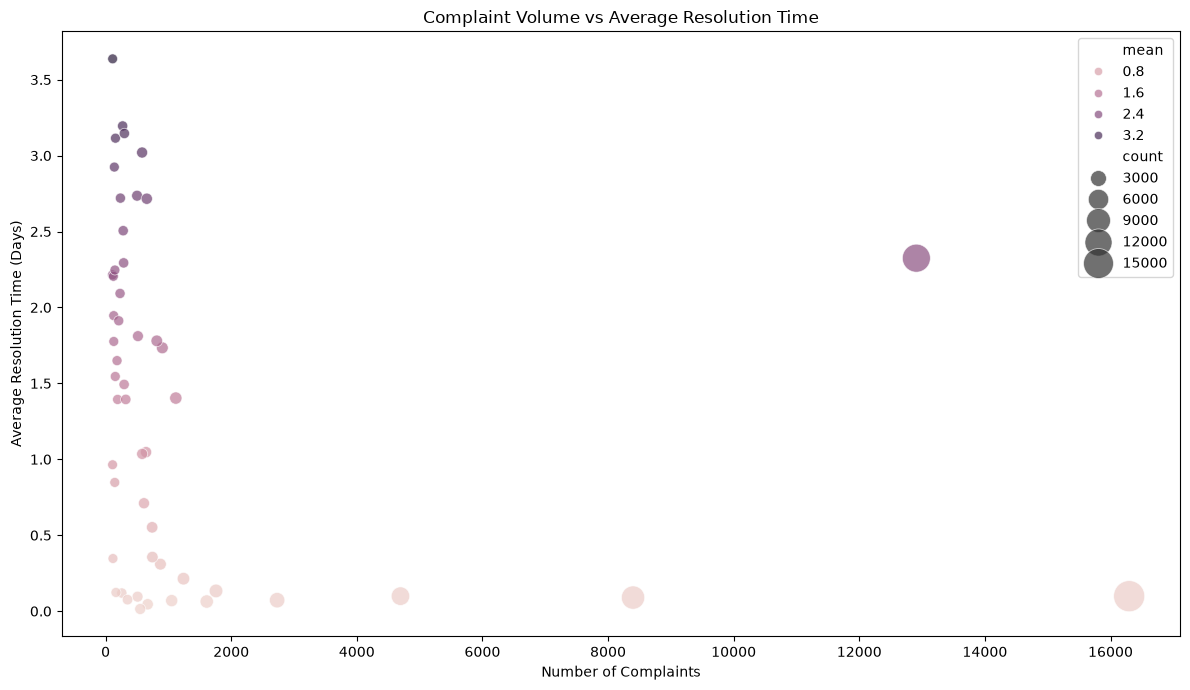

In [202]:
complaint_summary = (
    df.groupby('complaint_type')['resolution_days']
    .agg(
        count='count',
        mean='mean',
        median='median'
    )
    .reset_index()
)

complaint_summary = complaint_summary[
    complaint_summary['count'] >= 100
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=complaint_summary,
    x='count',
    y='mean',
    size='count',
    hue='mean',
    sizes=(50, 500),
    alpha=0.7
)

plt.title('Complaint Volume vs Average Resolution Time')
plt.xlabel('Number of Complaints')
plt.ylabel('Average Resolution Time (Days)')

plt.tight_layout()
plt.show()

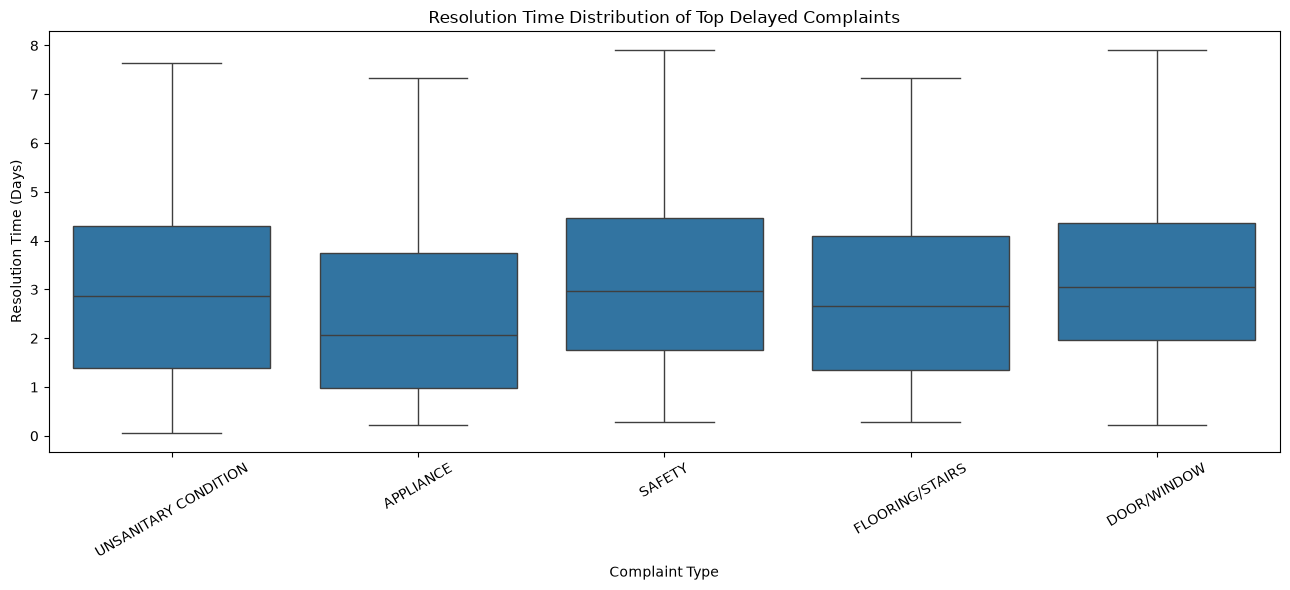

In [203]:
selected_types = [
    'APPLIANCE',
    'UNSANITARY CONDITION',
    'SAFETY',
    'DOOR/WINDOW',
    'FLOORING/STAIRS'
]

selected_df = df[
    df['complaint_type'].isin(selected_types)
]

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=selected_df,
    x='complaint_type',
    y='resolution_days'
)

plt.xticks(rotation=30)
plt.title('Resolution Time Distribution of Top Delayed Complaints')
plt.xlabel('Complaint Type')
plt.ylabel('Resolution Time (Days)')

plt.tight_layout()
plt.show()

In [204]:
#cleandata download

data_frame = df.columns.drop(
    [
        'descriptor_2',
        'descriptor_original',
        'descriptor_merged',
        'location_type_clean',
        'incident_zip_clean',
        'zip_validation',
        'incident_address_clean',
        'due_date_estimated'
    ],
    errors='ignore'
)


In [205]:
cleaned_df = df[data_frame].copy()

output_path = 'nyc_311_cleaned.csv'
cleaned_df.to_csv(output_path, index=False)
print(f'Saved {output_path}: {len(cleaned_df):,} rows, {len(cleaned_df.columns)} columns')

Saved nyc_311_cleaned.csv: 99,998 rows, 32 columns


In [206]:
cleaned_df.columns

Index(['unique_key', 'created_date', 'agency', 'agency_name', 'complaint_type',
       'descriptor', 'incident_address', 'status', 'resolution_description',
       'resolution_action_updated_date', 'community_board', 'police_precinct',
       'borough', 'open_data_channel_type', 'park_facility_name',
       'facility_type', 'location_type', 'incident_zip', 'city',
       'council_district', 'latitude', 'longitude', 'closed_date', 'due_date',
       'descriptor_clean', 'descriptor_2_clean', 'created_month',
       'created_weekday', 'created_hour', 'is_closed', 'resolution_hours',
       'resolution_days'],
      dtype='str')

CleanData insert into Postgres SQL

In [207]:
pip install SQLAlchemy

  Using cached sqlalchemy-2.1.9-cp312-cp312-win_amd64.whl.metadata (9.9 kB)
Using cached sqlalchemy-2.1.9-cp312-cp312-win_amd64.whl (2.4 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [208]:
CONNECTED = False

DB_CONFIG = {
    "host":     "localhost",
    "port":     5432,
    "database": "nyc_311",
    "user":     "postgres",
    "password": "123",
}

ENGINE = None

if CONNECTED:
    from sqlalchemy import create_engine
    url = (
        f"postgresql+psycopg2://{DB_CONFIG['user']}:{DB_CONFIG['password']}"
        f"@{DB_CONFIG['host']}:{DB_CONFIG['port']}/{DB_CONFIG['database']}"
    )
    ENGINE = create_engine(url)
    print("Connected to:", DB_CONFIG["database"])
else:
    print("Offline mode - your SQL will be printed, not run.")
    print("Copy it into pgAdmin's Query Tool to see results.")

Offline mode - your SQL will be printed, not run.
Copy it into pgAdmin's Query Tool to see results.


In [5]:
import pandas as pd
df_cleaned = pd.read_csv("nyc_311_cleaned.csv")

print("Rows and Columns:", df_cleaned.shape)


Caching the list of root modules, please wait!
(This will only be done once - type '%rehashx' to reset cache!)

Rows and Columns: (99998, 32)


In [210]:
from getpass import getpass
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
df_cleaned.to_sql(
    name="service_requests",
    con=ENGINE,
    if_exists="replace",
    index=False
)

AttributeError: 'NoneType' object has no attribute 'cursor'

In [ ]:
df_cleaned

In [211]:
import socket

try:
    with socket.create_connection(("127.0.0.1", 5432), timeout=5):
        print("PostgreSQL port 5432 is OPEN")
except OSError as e:
    print("Could not connect to port 5432:", e)

PostgreSQL port 5432 is OPEN


In [2]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

url = URL.create(
    drivername="postgresql+psycopg2",
    username="postgres",
    password="123",
    host="127.0.0.1",
    port=5432,
    database="urban_pulse_db",
    query={"connect_timeout": "5"}
)

ENGINE = create_engine(url, pool_pre_ping=True)

try:
    with ENGINE.connect() as conn:
        result = conn.execute(
            text("SELECT current_database(), current_user")
        )
        print("Connected Successfully!")
        print(result.fetchone())

except Exception as e:
    print("Connection Error:", repr(e))

Connected Successfully!
('urban_pulse_db', 'postgres')


In [6]:
df_cleaned.to_sql(
    name="service_requests",
    con=ENGINE,
    schema="public",
    if_exists="replace",
    index=False,
    chunksize=5000,
    method="multi"
)

print("Data inserted successfully!")

Data inserted successfully!


In [7]:
from sqlalchemy import text

with ENGINE.connect() as conn:
    count = conn.execute(
        text("SELECT COUNT(*) FROM public.service_requests")
    ).scalar_one()
    print(f"Rows in table: {count:,}")

Rows in table: 99,998
